# MT5 Volatility Seasonality Analyzer

This notebook organizes the M1, M5, and D1 volatility studies into reusable functions.

It supports:

- M1 / M5 intraday candle volatility by broker time
- Clean non-overlapping sessions and overlaps
- Full session high-low range
- Session expansion speed
- Directional efficiency
- D1 monthly range seasonality
- D1 weekday range analysis
- A final wrapper function where you can pass any new asset CSV path


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

## 1. Core helper functions

In [16]:
def load_mt5_csv(csv_path):
    """
    Load an MT5 OHLC CSV and normalize column names.

    Required columns:
        time, open, high, low, close

    Optional columns:
        tick_volume, spread, real_volume, range, body, weekday, ema20, atr14, etc.
    """
    csv_path = Path(csv_path)
    if not csv_path.exists():
        raise FileNotFoundError(f"CSV not found: {csv_path}")

    df = pd.read_csv(csv_path)

    # Normalize columns just in case
    df.columns = [str(c).strip().lower() for c in df.columns]

    required = ["time", "open", "high", "low", "close"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}. Found columns: {list(df.columns)}")

    df["time"] = pd.to_datetime(df["time"])
    df = df.sort_values("time").reset_index(drop=True)

    return df


def add_candle_features(df):
    """
    Add common candle metrics.
    """
    d = df.copy()

    d["range_raw"] = d["high"] - d["low"]
    d["body_raw"] = (d["close"] - d["open"]).abs()

    d.loc[d["range_raw"] <= 0, "range_raw"] = np.nan

    d["direction"] = np.sign(d["close"] - d["open"])
    d["directional_efficiency"] = d["body_raw"] / d["range_raw"]
    d["wick_ratio"] = 1 - d["directional_efficiency"]

    return d


def add_atr_features(df, atr_periods):
    """
    Add true range, ATR values, range/ATR, and body/ATR.
    """
    d = df.copy()

    prev_close = d["close"].shift(1)

    tr1 = d["high"] - d["low"]
    tr2 = (d["high"] - prev_close).abs()
    tr3 = (d["low"] - prev_close).abs()

    d["true_range"] = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)

    for p in atr_periods:
        d[f"atr{p}"] = d["true_range"].rolling(p).mean()
        d[f"range_atr{p}"] = d["range_raw"] / d[f"atr{p}"]
        d[f"body_atr{p}"] = d["body_raw"] / d[f"atr{p}"]

    return d


def minutes_since_midnight(ts):
    return ts.hour * 60 + ts.minute


def assign_clean_sessions(df):
    """
    Assign clean, non-overlapping broker-time sessions.

    Broker time assumption: UTC+03:00

    Sessions:
        Off-session:         01:00 - 03:00
        Asia core:           03:00 - 10:00
        Asia-London overlap: 10:00 - 12:00
        London core:         12:00 - 16:30
        London-NY overlap:   16:30 - 19:00
        New York core:       19:00 - 01:00
    """
    d = df.copy()

    d["broker_time"] = pd.to_datetime(d["broker_time"])
    d["minute_of_day"] = d["broker_time"].apply(minutes_since_midnight)
    d["date"] = d["broker_time"].dt.date
    d["tod"] = d["broker_time"].dt.strftime("%H:%M")

    def label(m):
        if 3 * 60 <= m < 10 * 60:
            return "Asia core"
        elif 10 * 60 <= m < 12 * 60:
            return "Asia-London overlap"
        elif 12 * 60 <= m < 16 * 60 + 30:
            return "London core"
        elif 16 * 60 + 30 <= m < 19 * 60:
            return "London-NY overlap"
        elif m >= 19 * 60 or m < 1 * 60:
            return "New York core"
        else:
            return "Off-session"

    session_order = [
        "Asia core",
        "Asia-London overlap",
        "London core",
        "London-NY overlap",
        "New York core",
        "Off-session",
    ]

    d["session_clean"] = d["minute_of_day"].apply(label)
    d["session_clean"] = pd.Categorical(
        d["session_clean"],
        categories=session_order,
        ordered=True
    )

    return d, session_order

## 2. Intraday analyzer for M1 and M5 CSV files

In [17]:
def analyze_intraday_csv(
    csv_path,
    timeframe,
    asset_name=None,
    broker_time_shift_hours=0,
    atr_periods=None,
    structural_atr=None,
    min_session_minutes=30,
    plot=True,
):
    """
    Analyze intraday volatility structure for M1 or M5 data.

    Parameters
    ----------
    csv_path : str
        Path to MT5 CSV file.
    timeframe : str
        "M1" or "M5".
    asset_name : str, optional
        Name used in chart titles. If None, the CSV file name is used.
    broker_time_shift_hours : int or float
        Use 0 if your CSV time is already broker time.
        Use +3, -2, etc. if you need to shift timestamps before assigning sessions.
    atr_periods : list[int], optional
        ATR windows to compare.
    structural_atr : int, optional
        ATR window used for session stats.
    min_session_minutes : int
        Minimum session fragment length to keep for full session range stats.
    plot : bool
        Whether to create plots.

    Returns
    -------
    dict with:
        df
        tod_stats
        candle_session_stats
        session_ranges
        session_range_summary
    """
    timeframe = timeframe.upper().strip()

    if timeframe not in ["M1", "M5"]:
        raise ValueError("timeframe must be 'M1' or 'M5'")

    if asset_name is None:
        asset_name = Path(csv_path).stem

    if timeframe == "M1":
        candle_minutes = 1
        if atr_periods is None:
            atr_periods = [60, 1500] #[60, 480, 1440, 1500]
        if structural_atr is None:
            structural_atr = 1500
        xtick_step = 60
    else:
        candle_minutes = 5
        if atr_periods is None:
            atr_periods = [14, 300] #[14, 96, 288, 300]
        if structural_atr is None:
            structural_atr = 300
        xtick_step = 12

    atr_col = f"atr{structural_atr}"
    range_atr_col = f"range_atr{structural_atr}"
    body_atr_col = f"body_atr{structural_atr}"

    df = load_mt5_csv(csv_path)
    d = add_candle_features(df)
    d = add_atr_features(d, atr_periods)

    # Broker time handling
    d["broker_time"] = d["time"] + pd.to_timedelta(broker_time_shift_hours, unit="h")

    d, session_order = assign_clean_sessions(d)

    # -------------------------
    # Time-of-day profile
    # -------------------------
    profile_cols = [f"range_atr{p}" for p in atr_periods]

    tod_stats = (
        d
        .replace([np.inf, -np.inf], np.nan)
        .dropna(subset=profile_cols)
        .groupby("tod")[profile_cols + ["directional_efficiency", "wick_ratio"]]
        .agg(["mean", "median"])
    )

    tod_stats.columns = ["_".join(col) for col in tod_stats.columns]
    tod_stats = tod_stats.reset_index()

    if plot:
        x = np.arange(len(tod_stats))

        plt.figure(figsize=(18, 6))
        for p in atr_periods:
            plt.plot(
                x,
                tod_stats[f"range_atr{p}_median"],
                label=f"Median range / ATR{p}"
            )

        plt.xticks(x[::xtick_step], tod_stats["tod"].iloc[::xtick_step], rotation=45)
        plt.title(f"{asset_name} {timeframe} Intraday Range Normalized by Different ATR Lengths")
        plt.xlabel("Broker Time of Day UTC+03:00")
        plt.ylabel("Median Candle Range / ATR")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(18, 5))
        plt.plot(
            x,
            tod_stats["directional_efficiency_median"],
            label="Median directional efficiency"
        )
        plt.xticks(x[::xtick_step], tod_stats["tod"].iloc[::xtick_step], rotation=45)
        plt.title(f"{asset_name} {timeframe} Directional Efficiency by Time of Day")
        plt.xlabel("Broker Time of Day UTC+03:00")
        plt.ylabel("|Close - Open| / Range")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()

    # -------------------------
    # Clean candle-level session stats
    # -------------------------
    candle_session_stats = (
        d
        .replace([np.inf, -np.inf], np.nan)
        .dropna(subset=[range_atr_col, body_atr_col, "directional_efficiency"])
        .groupby("session_clean", observed=False)
        .agg(
            candles=(range_atr_col, "count"),

            median_range_atr=(range_atr_col, "median"),
            mean_range_atr=(range_atr_col, "mean"),
            p75_range_atr=(range_atr_col, lambda x: x.quantile(0.75)),
            p90_range_atr=(range_atr_col, lambda x: x.quantile(0.90)),

            median_body_atr=(body_atr_col, "median"),
            median_directional_efficiency=("directional_efficiency", "median"),
            median_wick_ratio=("wick_ratio", "median"),

            median_tick_volume=("tick_volume", "median") if "tick_volume" in d.columns else (range_atr_col, "count"),
            mean_tick_volume=("tick_volume", "mean") if "tick_volume" in d.columns else (range_atr_col, "count"),
        )
    )

    display(candle_session_stats)

    if plot:
        plt.figure(figsize=(12, 5))
        candle_session_stats["median_range_atr"].plot(kind="bar")
        plt.title(f"{asset_name} {timeframe} Clean Session Volatility: Median Candle Range / ATR{structural_atr}")
        plt.xlabel("Clean Session")
        plt.ylabel(f"Median {timeframe} Range / ATR{structural_atr}")
        plt.grid(True, axis="y", alpha=0.3)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(12, 5))
        candle_session_stats["median_directional_efficiency"].plot(kind="bar")
        plt.title(f"{asset_name} {timeframe} Clean Session Directional Efficiency")
        plt.xlabel("Clean Session")
        plt.ylabel("Median |Close - Open| / Range")
        plt.grid(True, axis="y", alpha=0.3)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

    # -------------------------
    # Full session high-low range stats
    # -------------------------
    session_ranges = (
        d
        .replace([np.inf, -np.inf], np.nan)
        .dropna(subset=[atr_col])
        .groupby(["date", "session_clean"], observed=False)
        .agg(
            session_high=("high", "max"),
            session_low=("low", "min"),
            median_atr=(atr_col, "median"),
            candles=("close", "count")
        )
        .reset_index()
    )

    session_ranges["session_range"] = (
        session_ranges["session_high"] - session_ranges["session_low"]
    )

    session_ranges["session_range_atr"] = (
        session_ranges["session_range"] / session_ranges["median_atr"]
    )

    min_candles = max(1, int(min_session_minutes / candle_minutes))
    session_ranges = session_ranges[session_ranges["candles"] >= min_candles].copy()

    session_ranges["duration_hours"] = (
        session_ranges["candles"] * candle_minutes / 60
    )

    session_ranges["session_range_atr_per_hour"] = (
        session_ranges["session_range_atr"] / session_ranges["duration_hours"]
    )

    session_range_summary = (
        session_ranges
        .groupby("session_clean", observed=False)
        .agg(
            sessions=("session_range_atr", "count"),

            median_session_range_atr=("session_range_atr", "median"),
            mean_session_range_atr=("session_range_atr", "mean"),
            p75_session_range_atr=("session_range_atr", lambda x: x.quantile(0.75)),
            p90_session_range_atr=("session_range_atr", lambda x: x.quantile(0.90)),

            median_range_atr_per_hour=("session_range_atr_per_hour", "median"),
            mean_range_atr_per_hour=("session_range_atr_per_hour", "mean"),

            median_raw_range=("session_range", "median"),
            mean_raw_range=("session_range", "mean"),
            median_duration_hours=("duration_hours", "median"),
        )
    )

    display(session_range_summary)

    if plot:
        plt.figure(figsize=(12, 5))
        session_range_summary["median_session_range_atr"].plot(kind="bar")
        plt.title(f"{asset_name} {timeframe} Clean Full Session High-Low Range / ATR{structural_atr}")
        plt.xlabel("Clean Session")
        plt.ylabel(f"(Session High - Session Low) / Median ATR{structural_atr}")
        plt.grid(True, axis="y", alpha=0.3)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(12, 5))
        session_range_summary["median_range_atr_per_hour"].plot(kind="bar")
        plt.title(f"{asset_name} {timeframe} Clean Session Expansion Speed")
        plt.xlabel("Clean Session")
        plt.ylabel(f"Session Range / ATR{structural_atr} per Hour")
        plt.grid(True, axis="y", alpha=0.3)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

        plot_data = [
            session_ranges.loc[
                session_ranges["session_clean"] == s,
                "session_range_atr"
            ].dropna()
            for s in session_order
        ]

        plt.figure(figsize=(14, 6))
        plt.boxplot(
            plot_data,
            labels=session_order,
            showfliers=False
        )
        plt.title(f"{asset_name} {timeframe} Clean Session High-Low Range Distribution / ATR{structural_atr}")
        plt.xlabel("Clean Session")
        plt.ylabel(f"(Session High - Session Low) / Median ATR{structural_atr}")
        plt.grid(True, axis="y", alpha=0.3)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

    return {
        "df": d,
        "tod_stats": tod_stats,
        "candle_session_stats": candle_session_stats,
        "session_ranges": session_ranges,
        "session_range_summary": session_range_summary,
        "structural_atr": structural_atr,
        "timeframe": timeframe,
        "asset_name": asset_name,
    }

## 3. Daily analyzer for D1 CSV files

In [18]:
def analyze_d1_csv(
    csv_path,
    asset_name=None,
    atr_periods=None,
    structural_atr=250,
    plot=True,
):
    """
    Analyze D1 range seasonality by month and day of week.

    Parameters
    ----------
    csv_path : str
        Path to MT5 D1 CSV.
    asset_name : str, optional
        Name used in chart titles.
    atr_periods : list[int], optional
        ATR windows to compare.
    structural_atr : int
        ATR window used for main stats. Default 250 trading days.
    plot : bool
        Whether to create plots.

    Returns
    -------
    dict with:
        df
        month_stats
        weekday_stats
    """
    if asset_name is None:
        asset_name = Path(csv_path).stem

    if atr_periods is None:
        atr_periods = [14, 20, 60, 250]

    df = load_mt5_csv(csv_path)
    d = add_candle_features(df)
    d = add_atr_features(d, atr_periods)

    structural_range_col = f"range_atr{structural_atr}"
    structural_body_col = f"body_atr{structural_atr}"

    d["month_name"] = d["time"].dt.month_name()
    d["weekday"] = d["time"].dt.day_name()

    month_order = [
        "January", "February", "March", "April", "May", "June",
        "July", "August", "September", "October", "November", "December"
    ]

    weekday_order = [
        "Monday", "Tuesday", "Wednesday", "Thursday", "Friday"
    ]

    d["month_name"] = pd.Categorical(
        d["month_name"],
        categories=month_order,
        ordered=True
    )

    d["weekday"] = pd.Categorical(
        d["weekday"],
        categories=weekday_order,
        ordered=True
    )

    # Remove weekend candles if present
    d = d[d["weekday"].notna()].copy()

    agg_dict = {
        "candles": (structural_range_col, "count"),
        "median_range_raw": ("range_raw", "median"),
        "mean_range_raw": ("range_raw", "mean"),
        "p75_range_raw": ("range_raw", lambda x: x.quantile(0.75)),
        "p90_range_raw": ("range_raw", lambda x: x.quantile(0.90)),
        f"mean_range_atr{structural_atr}": (structural_range_col, "mean"),
        f"p75_range_atr{structural_atr}": (structural_range_col, lambda x: x.quantile(0.75)),
        f"p90_range_atr{structural_atr}": (structural_range_col, lambda x: x.quantile(0.90)),
        f"median_body_atr{structural_atr}": (structural_body_col, "median"),
        "median_directional_efficiency": ("directional_efficiency", "median"),
        "median_wick_ratio": ("wick_ratio", "median"),
    }

    for p in atr_periods:
        agg_dict[f"median_range_atr{p}"] = (f"range_atr{p}", "median")

    month_stats = (
        d
        .replace([np.inf, -np.inf], np.nan)
        .dropna(subset=[structural_range_col])
        .groupby("month_name", observed=False)
        .agg(**agg_dict)
    )

    display(month_stats)

    if plot:
        plt.figure(figsize=(14, 5))
        month_stats[f"median_range_atr{structural_atr}"].plot(kind="bar")
        plt.title(f"{asset_name} D1 Monthly Range Seasonality: Median Daily Range / ATR{structural_atr}")
        plt.xlabel("Month")
        plt.ylabel(f"Median Daily Range / ATR{structural_atr}")
        plt.grid(True, axis="y", alpha=0.3)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

        month_plot_data = [
            d.loc[d["month_name"] == m, structural_range_col].dropna()
            for m in month_order
        ]

        plt.figure(figsize=(14, 6))
        plt.boxplot(
            month_plot_data,
            labels=month_order,
            showfliers=False
        )
        plt.title(f"{asset_name} D1 Monthly Distribution of Daily Range Normalized by ATR{structural_atr}")
        plt.xlabel("Month")
        plt.ylabel(f"Daily Range / ATR{structural_atr}")
        plt.grid(True, axis="y", alpha=0.3)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(14, 6))
        for p in atr_periods:
            plt.plot(
                month_stats.index.astype(str),
                month_stats[f"median_range_atr{p}"],
                marker="o",
                label=f"Median range / ATR{p}"
            )

        plt.title(f"{asset_name} D1 Monthly Range Using Different ATR Normalizations")
        plt.xlabel("Month")
        plt.ylabel("Median Daily Range / ATR")
        plt.grid(True, alpha=0.3)
        plt.xticks(rotation=45, ha="right")
        plt.legend()
        plt.tight_layout()
        plt.show()

    weekday_stats = (
        d
        .replace([np.inf, -np.inf], np.nan)
        .dropna(subset=[structural_range_col])
        .groupby("weekday", observed=False)
        .agg(**agg_dict)
    )

    display(weekday_stats)

    if plot:
        plt.figure(figsize=(10, 5))
        weekday_stats[f"median_range_atr{structural_atr}"].plot(kind="bar")
        plt.title(f"{asset_name} D1 Range by Day of Week: Median Daily Range / ATR{structural_atr}")
        plt.xlabel("Day of Week")
        plt.ylabel(f"Median Daily Range / ATR{structural_atr}")
        plt.grid(True, axis="y", alpha=0.3)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

        weekday_plot_data = [
            d.loc[d["weekday"] == w, structural_range_col].dropna()
            for w in weekday_order
        ]

        plt.figure(figsize=(10, 6))
        plt.boxplot(
            weekday_plot_data,
            labels=weekday_order,
            showfliers=False
        )
        plt.title(f"{asset_name} D1 Distribution of Daily Range by Weekday Normalized by ATR{structural_atr}")
        plt.xlabel("Day of Week")
        plt.ylabel(f"Daily Range / ATR{structural_atr}")
        plt.grid(True, axis="y", alpha=0.3)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(10, 5))
        weekday_stats["median_directional_efficiency"].plot(kind="bar")
        plt.title(f"{asset_name} D1 Directional Efficiency by Weekday")
        plt.xlabel("Day of Week")
        plt.ylabel("Median |Close - Open| / Range")
        plt.grid(True, axis="y", alpha=0.3)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

    return {
        "df": d,
        "month_stats": month_stats,
        "weekday_stats": weekday_stats,
        "structural_atr": structural_atr,
        "asset_name": asset_name,
    }

## D1 Day-of-Month Volatility Seasonality


In [19]:

# %%
def analyze_d1_day_of_month_csv(
    csv_path,
    asset_name=None,
    atr_periods=None,
    structural_atr=250,
    min_candles_per_day=10,
    plot=True,
):
    """
    Analyze D1 volatility by day of the month.

    This shows whether certain calendar days, such as the 1st, 15th,
    or month-end, tend to have higher or lower daily volatility.

    Volatility is normalized by ATR, just like the other D1 charts.

    Parameters
    ----------
    csv_path : str
        Path to MT5 D1 CSV.

    asset_name : str, optional
        Name used in chart titles.

    atr_periods : list[int], optional
        ATR windows to compare.

    structural_atr : int
        Main ATR window used for the primary chart and summary.
        Default is 250 trading days.

    min_candles_per_day : int
        Minimum number of historical candles required for a day-of-month
        bucket to be included in plots.

    plot : bool
        Whether to create charts.

    Returns
    -------
    dict with:
        df
        day_of_month_stats
        structural_atr
        asset_name
    """
    if asset_name is None:
        asset_name = Path(csv_path).stem

    if atr_periods is None:
        atr_periods = [14, 20, 60, 250]

    if structural_atr not in atr_periods:
        atr_periods = list(atr_periods) + [structural_atr]

    df = load_mt5_csv(csv_path)
    d = add_candle_features(df)
    d = add_atr_features(d, atr_periods)

    structural_range_col = f"range_atr{structural_atr}"
    structural_body_col = f"body_atr{structural_atr}"

    d["day_of_month"] = d["time"].dt.day
    d["weekday"] = d["time"].dt.day_name()

    weekday_order = [
        "Monday", "Tuesday", "Wednesday", "Thursday", "Friday"
    ]

    d["weekday"] = pd.Categorical(
        d["weekday"],
        categories=weekday_order,
        ordered=True
    )

    # Remove weekend candles if present
    d = d[d["weekday"].notna()].copy()

    agg_dict = {
        "candles": (structural_range_col, "count"),

        "median_range_raw": ("range_raw", "median"),
        "mean_range_raw": ("range_raw", "mean"),
        "p75_range_raw": ("range_raw", lambda x: x.quantile(0.75)),
        "p90_range_raw": ("range_raw", lambda x: x.quantile(0.90)),

        f"mean_range_atr{structural_atr}": (structural_range_col, "mean"),
        f"p75_range_atr{structural_atr}": (structural_range_col, lambda x: x.quantile(0.75)),
        f"p90_range_atr{structural_atr}": (structural_range_col, lambda x: x.quantile(0.90)),

        f"median_body_atr{structural_atr}": (structural_body_col, "median"),
        "median_directional_efficiency": ("directional_efficiency", "median"),
        "median_wick_ratio": ("wick_ratio", "median"),
    }

    for p in atr_periods:
        agg_dict[f"median_range_atr{p}"] = (f"range_atr{p}", "median")

    day_of_month_stats = (
        d
        .replace([np.inf, -np.inf], np.nan)
        .dropna(subset=[structural_range_col])
        .groupby("day_of_month")
        .agg(**agg_dict)
        .sort_index()
    )

    display(day_of_month_stats)

    if plot:
        plot_stats = day_of_month_stats[
            day_of_month_stats["candles"] >= min_candles_per_day
        ].copy()

        plt.figure(figsize=(14, 5))
        plot_stats[f"median_range_atr{structural_atr}"].plot(kind="bar")
        plt.title(
            f"{asset_name} D1 Volatility by Day of Month: "
            f"Median Daily Range / ATR{structural_atr}"
        )
        plt.xlabel("Day of Month")
        plt.ylabel(f"Median Daily Range / ATR{structural_atr}")
        plt.grid(True, axis="y", alpha=0.3)
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

        day_plot_data = [
            d.loc[d["day_of_month"] == day, structural_range_col].dropna()
            for day in plot_stats.index
        ]

        plt.figure(figsize=(14, 6))
        plt.boxplot(
            day_plot_data,
            labels=plot_stats.index.astype(str),
            showfliers=False
        )
        plt.title(
            f"{asset_name} D1 Distribution of Daily Range by Day of Month "
            f"Normalized by ATR{structural_atr}"
        )
        plt.xlabel("Day of Month")
        plt.ylabel(f"Daily Range / ATR{structural_atr}")
        plt.grid(True, axis="y", alpha=0.3)
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(14, 6))
        for p in atr_periods:
            plt.plot(
                plot_stats.index,
                plot_stats[f"median_range_atr{p}"],
                marker="o",
                label=f"Median range / ATR{p}"
            )

        plt.title(
            f"{asset_name} D1 Day-of-Month Range Using Different ATR Normalizations"
        )
        plt.xlabel("Day of Month")
        plt.ylabel("Median Daily Range / ATR")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(14, 5))
        plot_stats["median_directional_efficiency"].plot(kind="bar")
        plt.title(f"{asset_name} D1 Directional Efficiency by Day of Month")
        plt.xlabel("Day of Month")
        plt.ylabel("Median |Close - Open| / Range")
        plt.grid(True, axis="y", alpha=0.3)
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

    return {
        "df": d,
        "day_of_month_stats": day_of_month_stats,
        "structural_atr": structural_atr,
        "asset_name": asset_name,
    }

## 4. Example usage for your current gold files

In [20]:
# M5 gold analysis
# xau_m5_results = analyze_intraday_csv(
#     csv_path=r"mt5_data\XAUUSDzero_M5_max_bars.csv",
#     timeframe="M5",
#     asset_name="XAUUSDzero",
# )

# M1 gold analysis
# xau_m1_results = analyze_intraday_csv(
#     csv_path=r"mt5_data\XAUUSDzero_M1_max_bars.csv",
#     timeframe="M1",
#     asset_name="XAUUSDzero",
# )

# D1 gold analysis
# xau_d1_results = analyze_d1_csv(
#     csv_path=r"mt5_data\XAUUSDzero_D1_max_bars.csv",
#     asset_name="XAUUSDzero",
# )

## 5. Final wrapper function for any new asset CSV

Use this function when you add another CSV, for example a forex pair.

Examples:

```python
eurusd_m5 = analyze_asset_csv(r"mt5_data\EURUSD_M5_max_bars.csv", timeframe="M5", asset_name="EURUSD")
eurusd_m1 = analyze_asset_csv(r"mt5_data\EURUSD_M1_max_bars.csv", timeframe="M1", asset_name="EURUSD")
eurusd_d1 = analyze_asset_csv(r"mt5_data\EURUSD_D1_max_bars.csv", timeframe="D1", asset_name="EURUSD")
```


In [21]:
def analyze_asset_csv(
    csv_path,
    timeframe,
    asset_name=None,
    broker_time_shift_hours=0,
    plot=True,
):
    """
    Main wrapper function for any asset CSV.

    Use this at the bottom of the notebook for new assets.

    Parameters
    ----------
    csv_path : str
        Path to the CSV file.
    timeframe : str
        "M1", "M5", or "D1".
    asset_name : str, optional
        Name for chart titles.
    broker_time_shift_hours : int or float
        Use 0 if the CSV time is already broker time UTC+03:00.
        Example: if your CSV is UTC and you want broker UTC+03:00, use 3.
    plot : bool
        Whether to create charts.

    Returns
    -------
    dict of analysis results.
    """
    timeframe = timeframe.upper().strip()

    if timeframe in ["M1", "M5"]:
        return analyze_intraday_csv(
            csv_path=csv_path,
            timeframe=timeframe,
            asset_name=asset_name,
            broker_time_shift_hours=broker_time_shift_hours,
            plot=plot,
        )

    elif timeframe == "D1":
        return analyze_d1_csv(
            csv_path=csv_path,
            asset_name=asset_name,
            plot=plot,
        )

    else:
        raise ValueError("timeframe must be 'M1', 'M5', or 'D1'")


# =========================
# Add another asset here
# =========================

# Example:
# results = analyze_asset_csv(
#     csv_path=r"mt5_data\EURUSDzero_M5_max_bars.csv",
#     timeframe="M5",
#     asset_name="EURUSDzero",
#     broker_time_shift_hours=0,
#     plot=True,
# )

## EURUSD

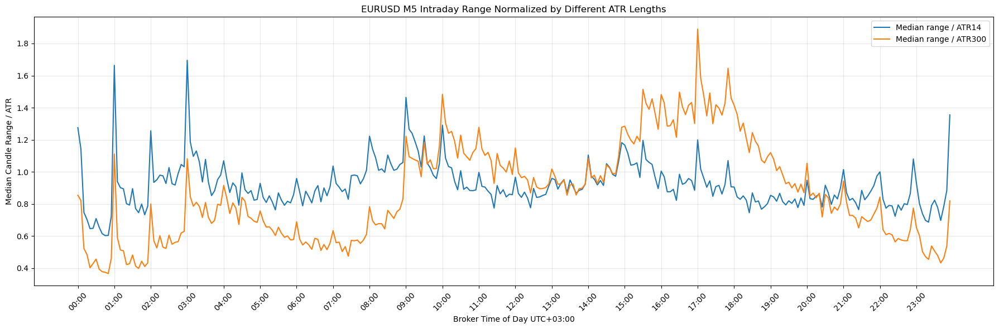

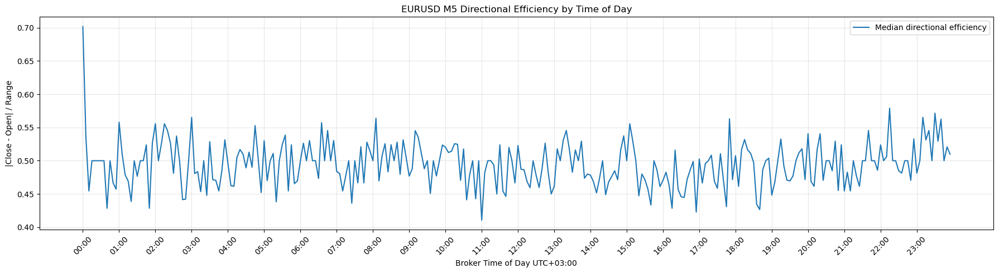

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,26208,0.714844,0.821182,0.997541,1.375439,0.331024,0.500000,0.500000,129.0,151.344208
Asia-London overlap,7503,1.130486,1.264173,1.497277,1.967619,0.522819,0.488372,0.511628,212.0,234.658936
London core,16885,1.062303,1.230931,1.444365,1.971411,0.485219,0.484848,0.515152,201.0,225.987622
London-NY overlap,9360,1.341000,1.499320,1.781449,2.325043,0.604924,0.482759,0.517241,271.0,292.223718
New York core,22212,0.696275,0.830926,1.006913,1.423564,0.309523,0.500000,0.500000,122.0,136.212318
Off-session,7488,0.537736,0.682557,0.822029,1.233416,0.243507,0.500000,0.500000,84.0,107.848691


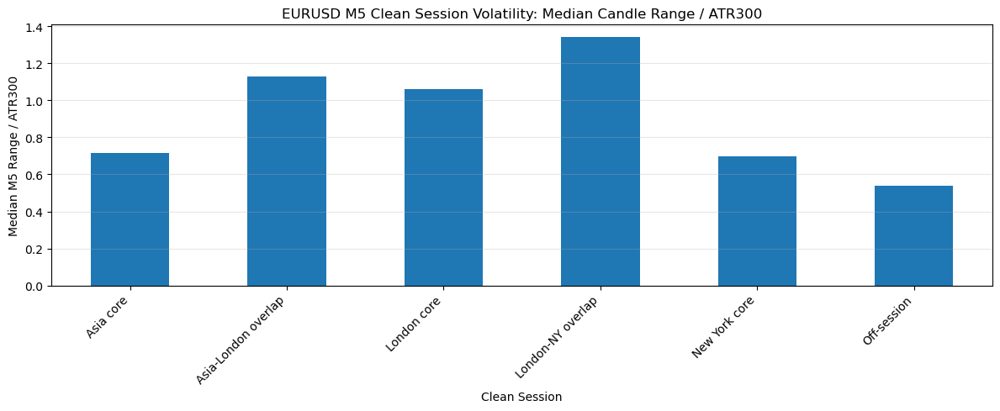

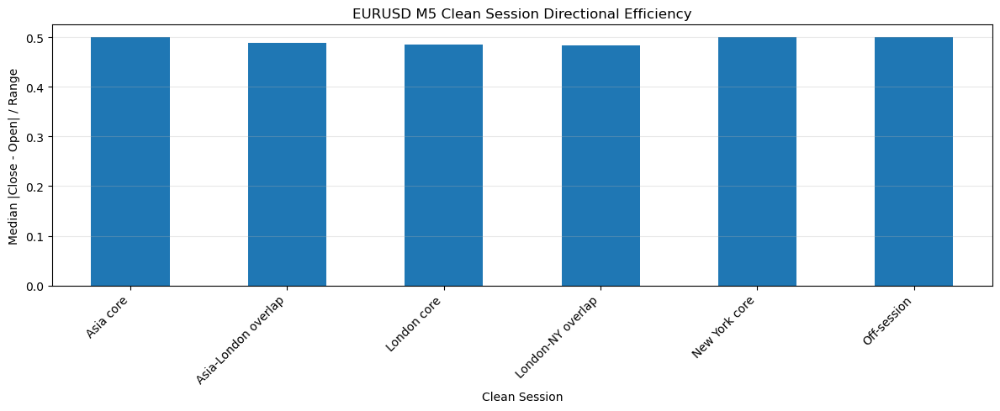

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,312,7.788779,8.476344,9.936079,12.713112,1.112683,1.210906,0.002880,0.003349,7.0
Asia-London overlap,313,5.960416,6.646122,7.631899,10.008638,2.994887,3.327426,0.002220,0.002693,2.0
London core,313,8.951997,9.982110,11.505588,16.108476,1.989333,2.221868,0.003400,0.003917,4.5
London-NY overlap,312,8.060454,8.795859,10.167807,12.684346,3.224182,3.518344,0.003085,0.003534,2.5
New York core,313,13.055818,14.575715,18.060527,23.785162,2.179456,2.460998,0.004790,0.005823,6.0
Off-session,312,3.181085,3.918673,4.485441,5.865791,1.590543,1.959337,0.001165,0.001541,2.0


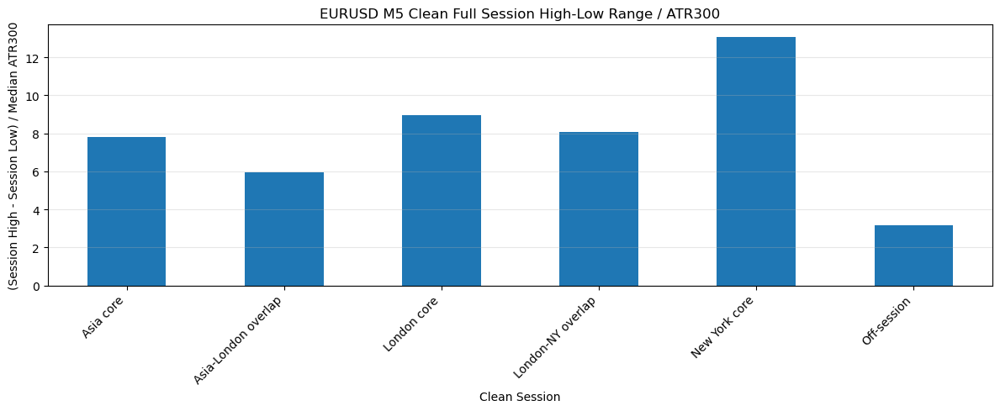

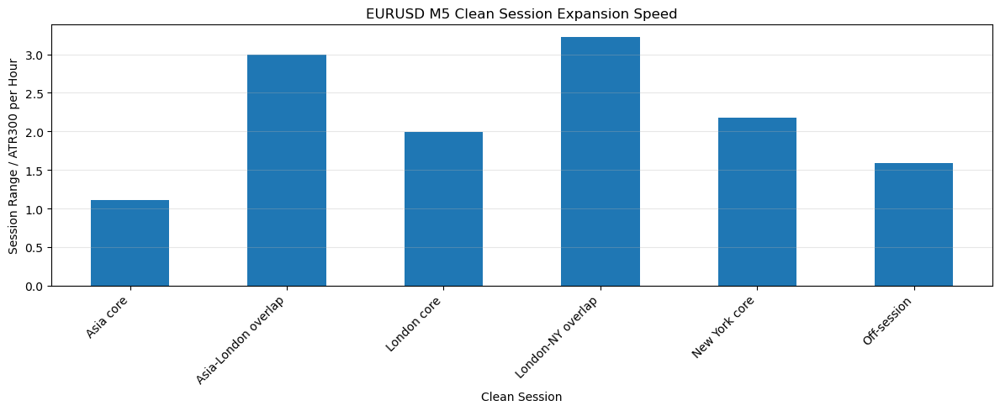

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


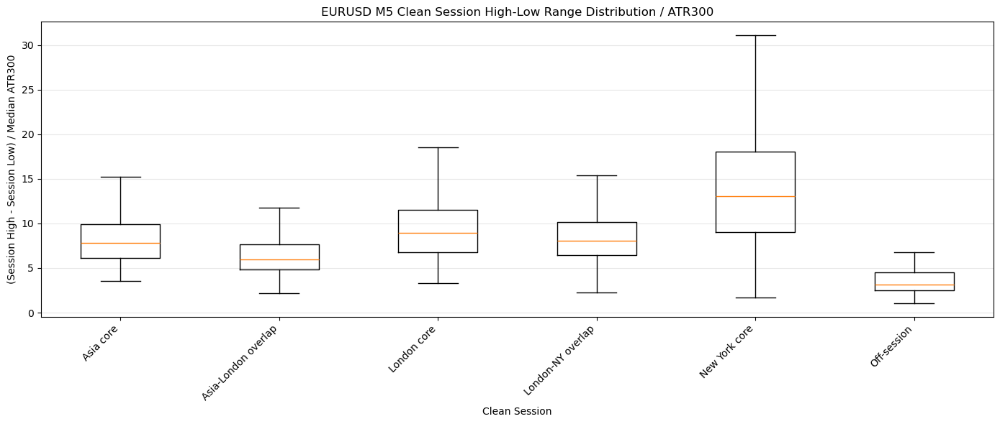

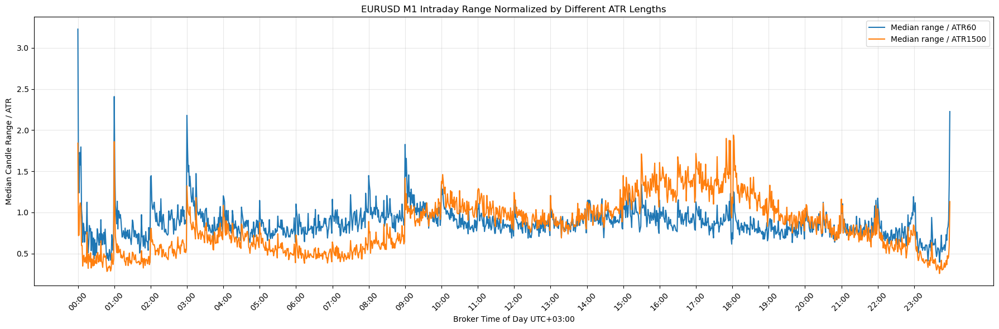

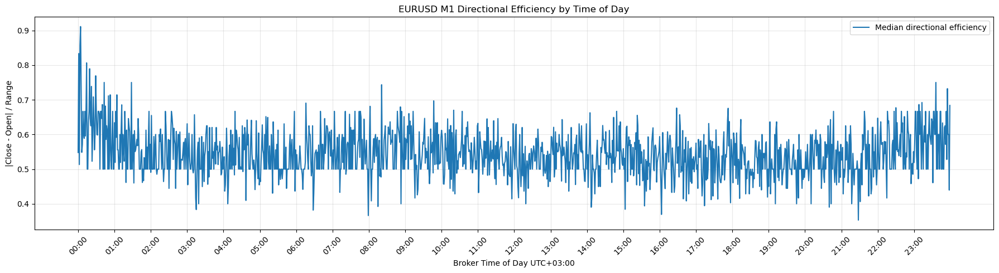

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,26005,0.649970,0.767088,0.954941,1.365371,0.320239,0.545455,0.454545,24.0,26.199615
Asia-London overlap,7440,1.054565,1.197542,1.456193,1.953555,0.530100,0.545455,0.454545,38.0,39.261694
London core,16735,1.044659,1.235225,1.483276,2.068383,0.512492,0.535714,0.464286,37.0,40.034837
London-NY overlap,9283,1.320310,1.498843,1.810218,2.432037,0.636853,0.523810,0.476190,50.0,51.291608
New York core,21103,0.702988,0.868987,1.085873,1.610611,0.331400,0.550000,0.450000,26.0,28.427143
Off-session,7347,0.501379,0.684857,0.846017,1.357633,0.247036,0.555556,0.444444,17.0,20.908534


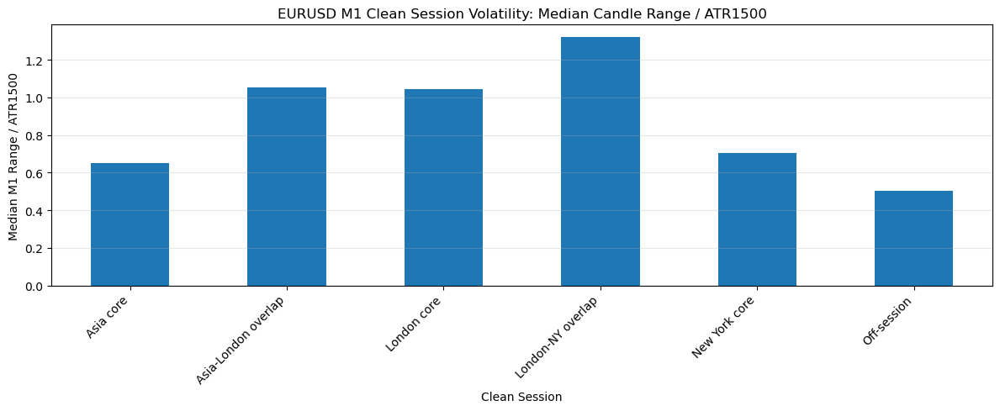

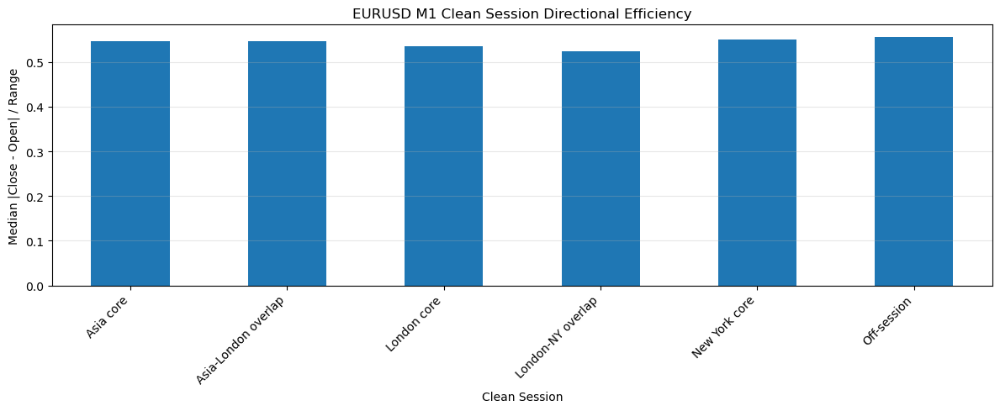

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,62,18.367563,21.130674,23.952707,31.036772,2.627111,3.019635,0.002600,0.003191,7.000000
Asia-London overlap,62,14.597576,16.382299,20.010238,23.556887,7.298788,8.191150,0.002155,0.002518,2.000000
London core,62,20.823359,23.499645,25.680457,37.354867,4.627413,5.222143,0.003320,0.003634,4.500000
London-NY overlap,62,18.276036,19.495059,23.498329,29.991681,7.310414,7.808462,0.002685,0.003050,2.500000
New York core,63,34.786571,36.348010,45.281883,59.317611,5.955665,6.349177,0.004940,0.005668,5.916667
Off-session,62,8.923145,10.250268,11.078105,13.602793,4.461573,5.135744,0.001150,0.001551,2.000000


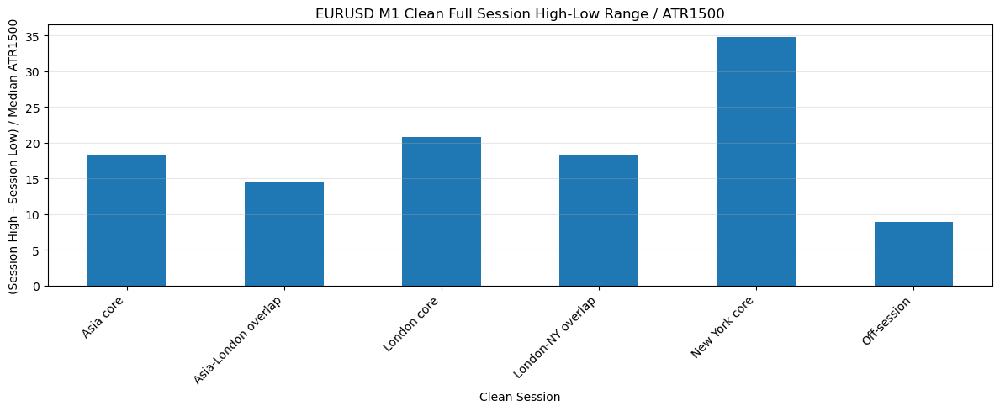

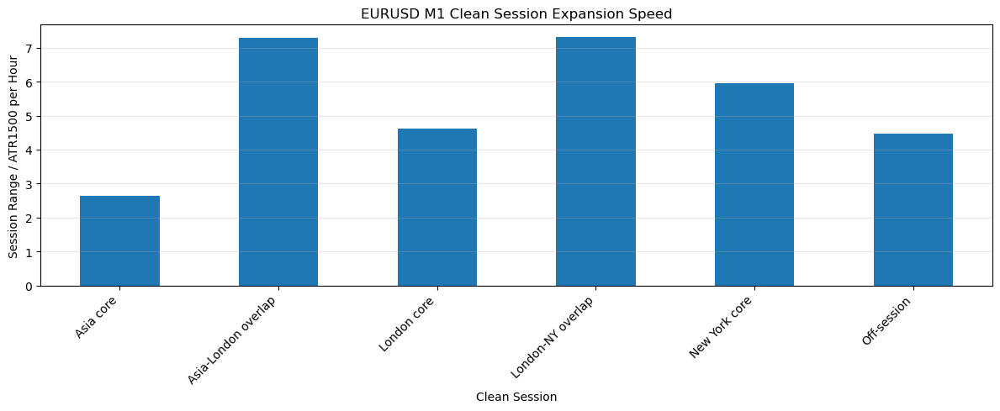

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


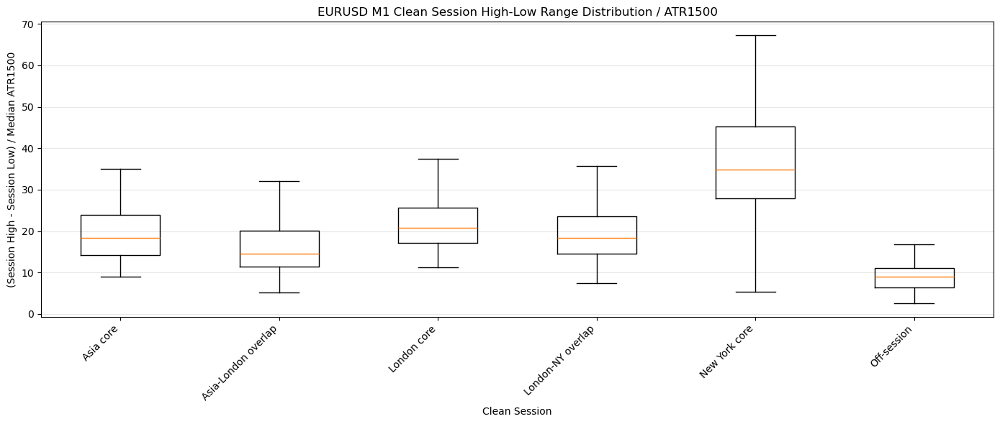

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
month_name,,,,,,,,,,,,,,,
January,1107,0.00790,0.008851,0.0122,0.01704,0.907488,1.188033,1.581850,0.244569,0.348485,0.651515,0.852792,0.850340,0.855401,0.843937
February,1026,0.00750,0.008128,0.0114,0.01595,0.841801,1.097293,1.465584,0.205716,0.323868,0.676132,0.798499,0.771085,0.791308,0.801818
March,1136,0.00790,0.008730,0.0119,0.01665,0.925512,1.145337,1.628951,0.251130,0.372914,0.627086,0.819765,0.818344,0.789301,0.790874
April,1096,0.00730,0.008052,0.0110,0.01600,0.825848,1.067839,1.495890,0.202734,0.344188,0.655812,0.814427,0.794110,0.766901,0.758213
May,1117,0.00760,0.008219,0.0115,0.01614,0.829798,1.115685,1.463333,0.249087,0.379747,0.620253,0.839270,0.828811,0.792555,0.785532
June,1112,0.00740,0.008020,0.0113,0.01540,0.815195,1.080623,1.442468,0.212551,0.333333,0.666667,0.800152,0.799956,0.800068,0.772775
July,1143,0.00730,0.007844,0.0110,0.01566,0.814235,1.076084,1.472743,0.205660,0.343750,0.656250,0.801180,0.797482,0.772566,0.723072
August,1134,0.00738,0.008073,0.0113,0.01507,0.824008,1.085355,1.458307,0.228158,0.344457,0.655543,0.802727,0.799748,0.796138,0.768878
September,1097,0.00770,0.008612,0.0119,0.01680,0.864109,1.160553,1.534119,0.217022,0.333333,0.666667,0.815534,0.817817,0.815358,0.776794


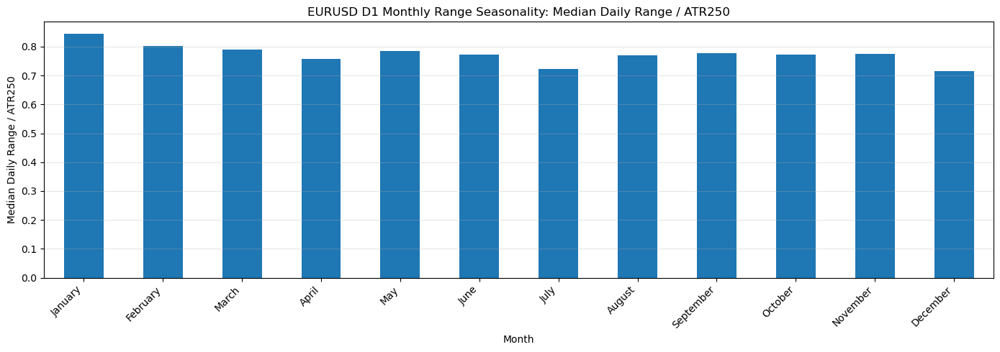

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:115: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


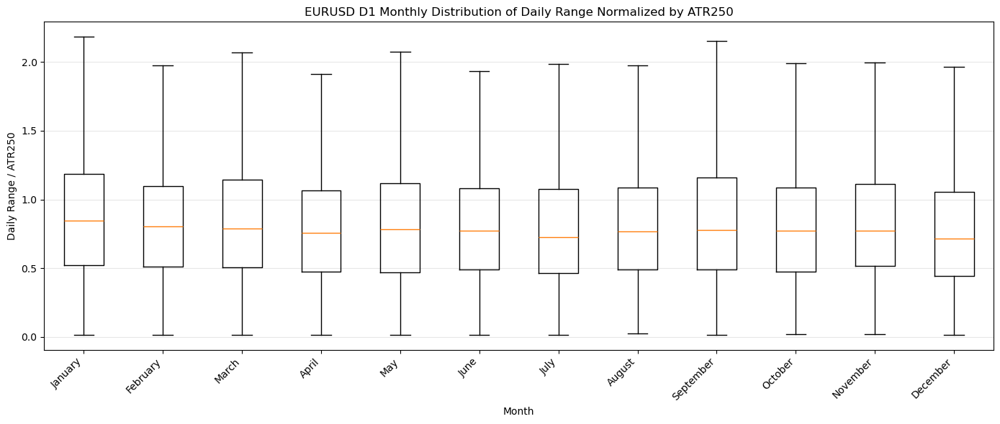

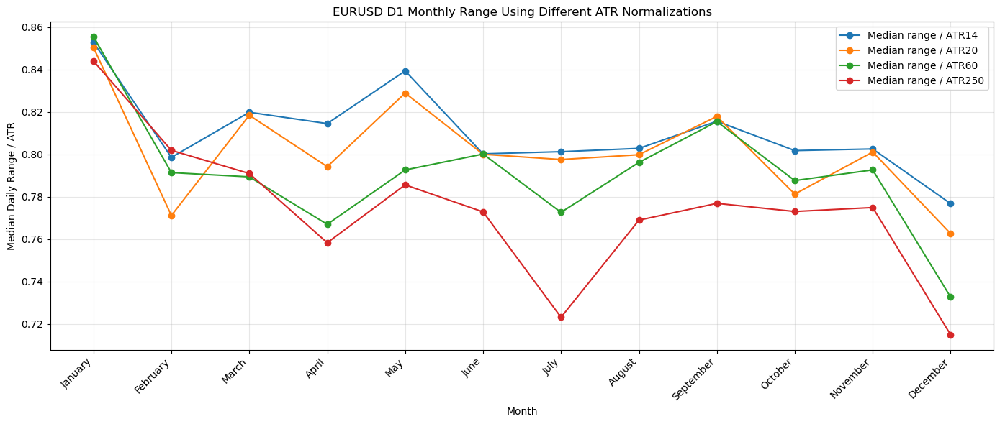

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
weekday,,,,,,,,,,,,,,,
Monday,2591,0.0068,0.007812,0.010600,0.015300,0.791727,1.021983,1.426407,0.208972,0.355786,0.644214,0.739792,0.736032,0.724638,0.707375
Tuesday,2669,0.0073,0.008108,0.011100,0.015608,0.827754,1.084118,1.454229,0.212745,0.341463,0.658537,0.799049,0.795534,0.784409,0.762078
Wednesday,2672,0.0076,0.008156,0.011218,0.015700,0.835168,1.102165,1.472767,0.224261,0.338150,0.661850,0.815700,0.805691,0.793100,0.769122
Thursday,2669,0.0079,0.008651,0.012000,0.016920,0.890208,1.141981,1.540989,0.235536,0.346821,0.653179,0.856716,0.846984,0.836805,0.813764
Friday,2665,0.0077,0.008550,0.012000,0.016960,0.870114,1.139279,1.559861,0.237884,0.352941,0.647059,0.844221,0.840336,0.825000,0.808530


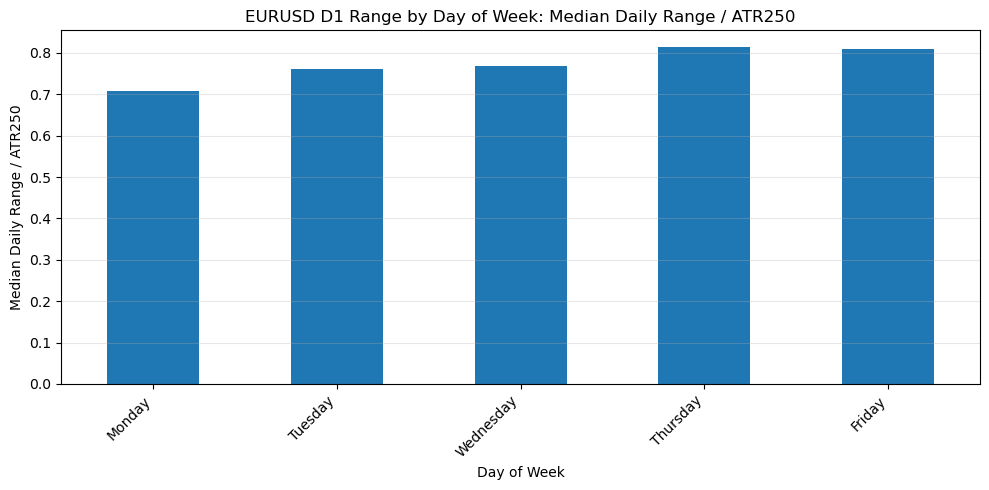

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:173: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


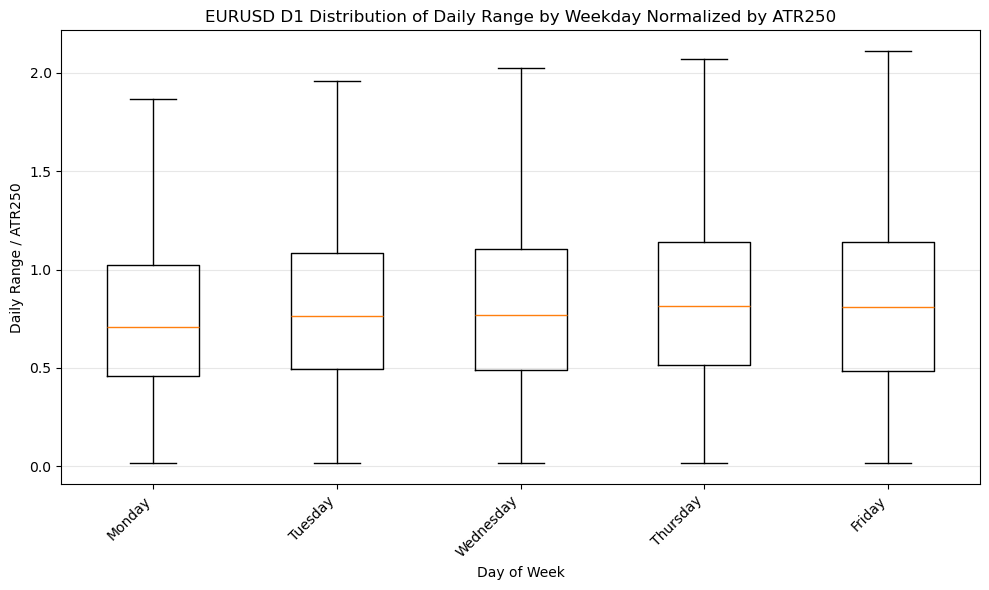

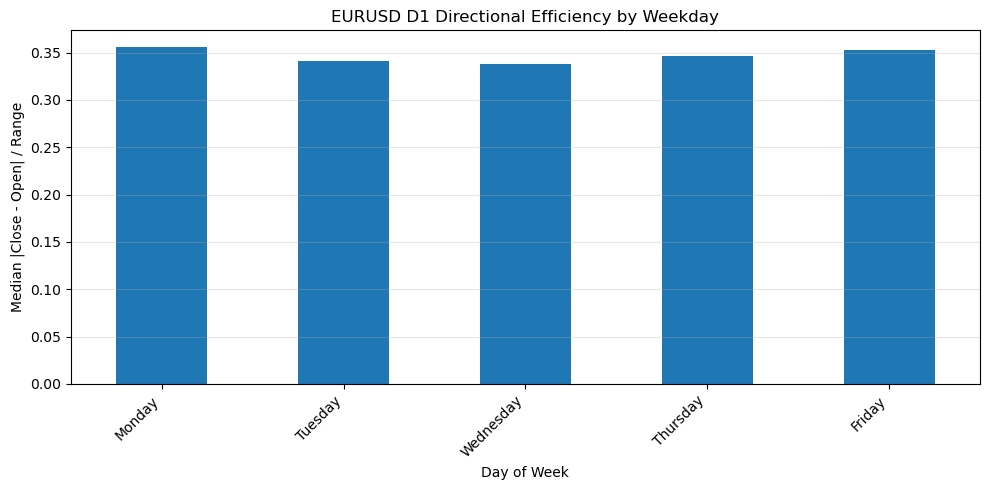

In [22]:
eurusd_m5 = analyze_asset_csv(r"mt5_data\EURUSDzero_M5_max_bars.csv", timeframe="M5", asset_name="EURUSD")
eurusd_m1 = analyze_asset_csv(r"mt5_data\EURUSDzero_M1_max_bars.csv", timeframe="M1", asset_name="EURUSD")
eurusd_d1 = analyze_asset_csv(r"mt5_data\EURUSDzero_D1_max_bars.csv", timeframe="D1", asset_name="EURUSD")

## USDJPY

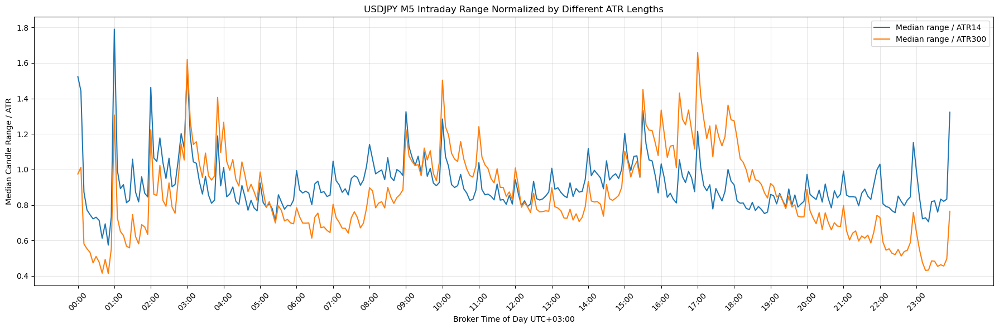

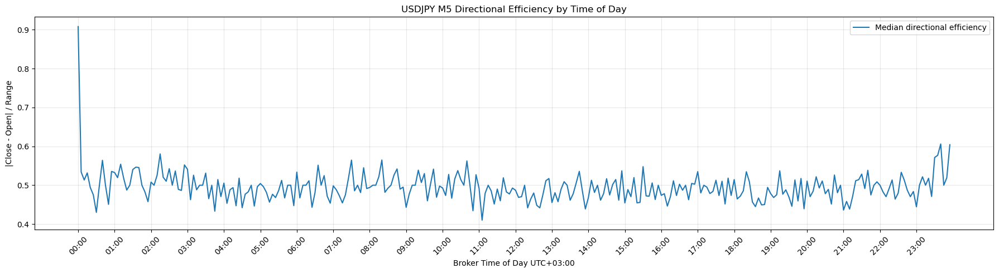

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,26208,0.870855,1.004464,1.212033,1.651082,0.393288,0.493242,0.506758,174.0,182.534951
Asia-London overlap,7512,1.026972,1.158340,1.371760,1.818982,0.479467,0.491803,0.508197,209.0,217.499068
London core,16886,0.888891,1.060103,1.223293,1.700021,0.408253,0.482248,0.517752,194.0,206.647282
London-NY overlap,9360,1.143867,1.306866,1.547000,2.073093,0.523522,0.488372,0.511628,251.0,257.355876
New York core,22195,0.639731,0.770469,0.924276,1.308894,0.287240,0.500000,0.500000,143.0,145.592341
Off-session,7488,0.789191,0.961912,1.213318,1.725925,0.366215,0.520493,0.479507,125.0,145.346020


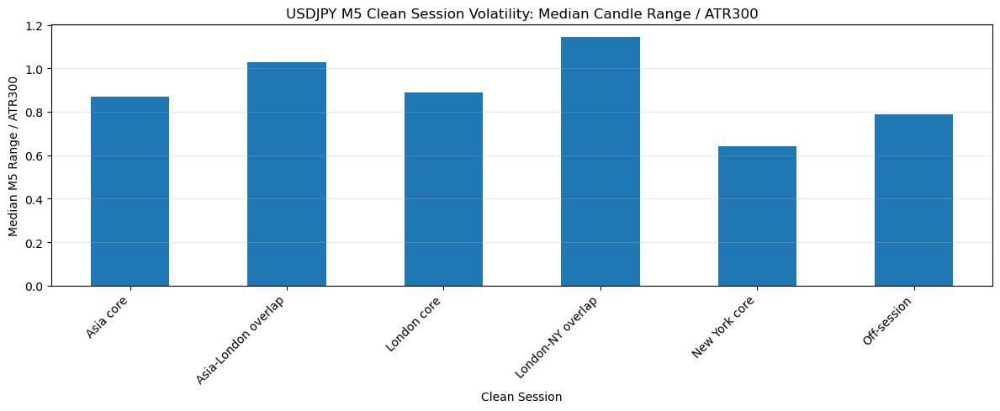

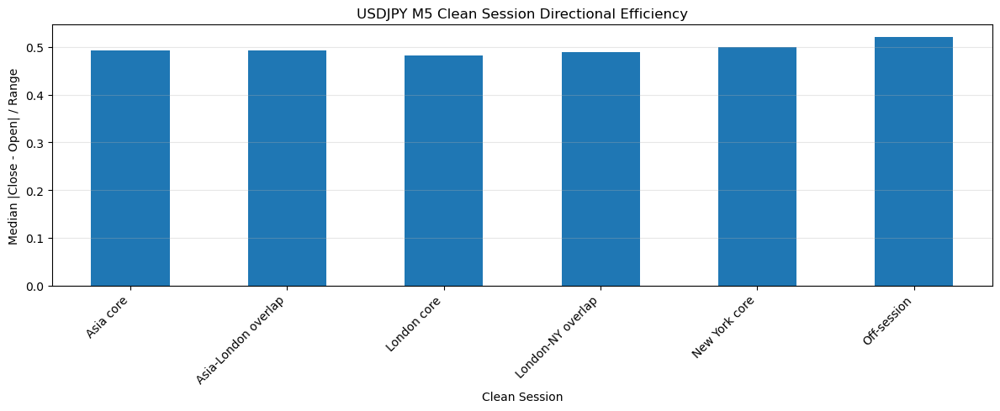

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,312,9.640296,10.888407,12.598149,16.462767,1.377185,1.555487,0.6015,0.653878,7.0
Asia-London overlap,313,5.756510,6.313564,7.226344,9.462291,2.878255,3.156782,0.3420,0.394294,2.0
London core,313,8.245883,9.157595,10.713215,13.841481,1.837678,2.037202,0.4950,0.562917,4.5
London-NY overlap,312,6.985795,7.608516,8.629311,10.867871,2.794318,3.043406,0.4125,0.473644,2.5
New York core,313,13.012531,14.865626,19.110101,24.361717,2.238040,2.516492,0.7750,0.929492,6.0
Off-session,312,4.731370,5.354956,6.369595,8.316194,2.365685,2.677478,0.2790,0.324362,2.0


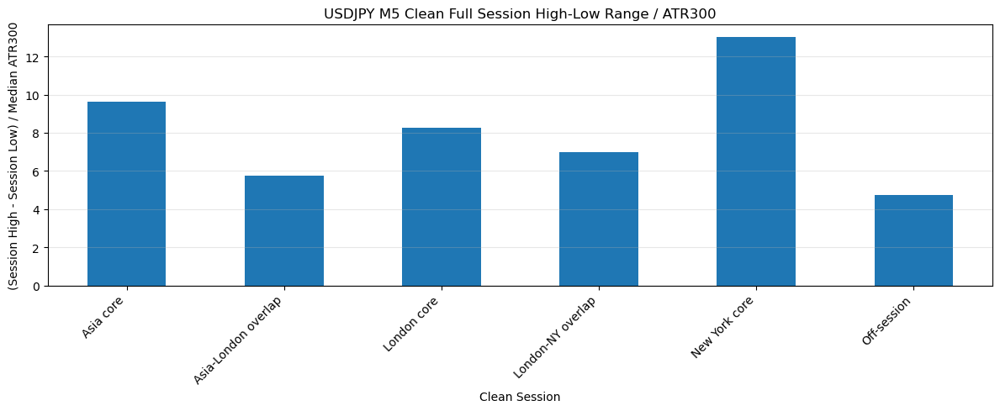

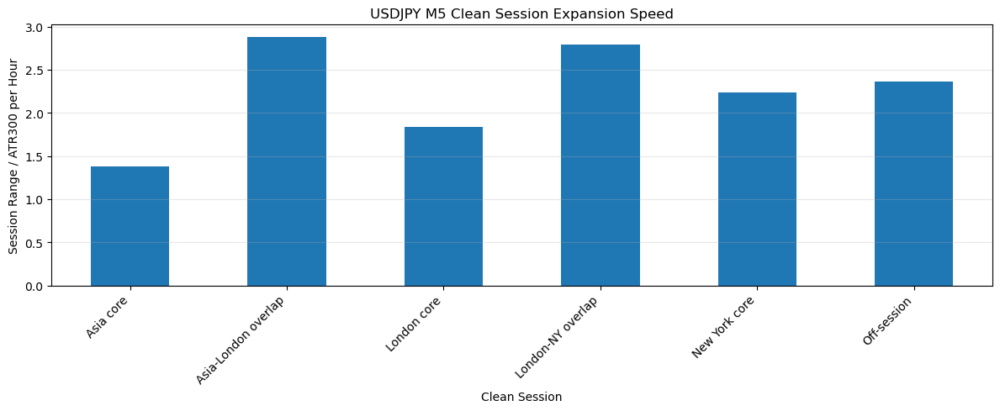

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


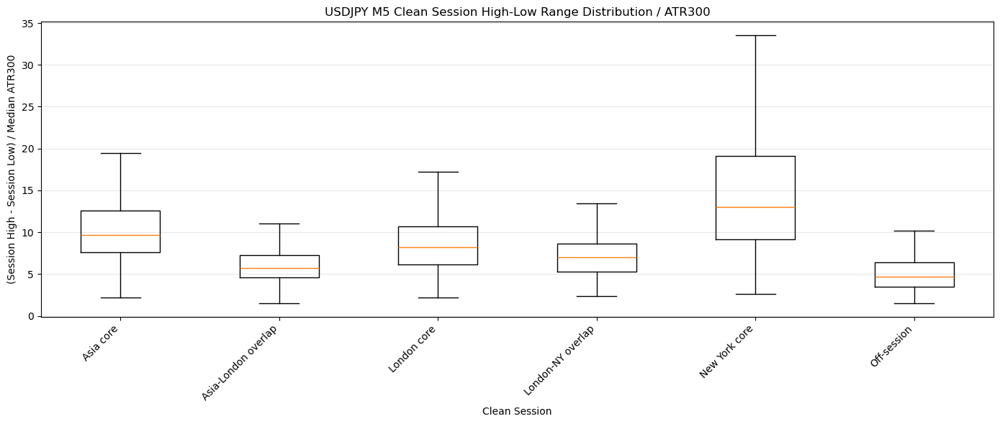

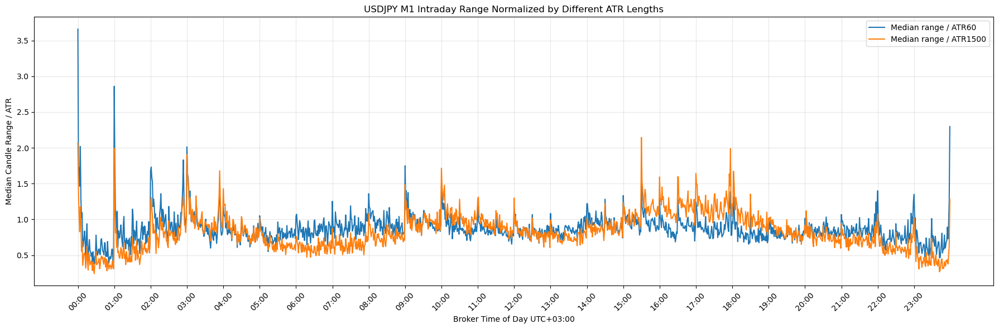

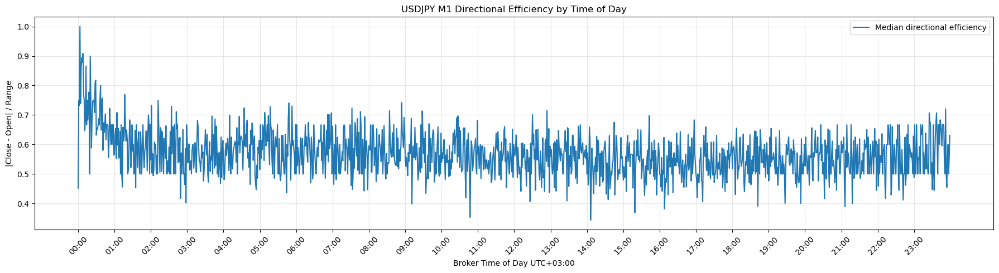

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,26035,0.777660,0.939587,1.161987,1.675669,0.400727,0.578947,0.421053,30.0,32.022777
Asia-London overlap,7440,0.978882,1.138043,1.395147,1.929017,0.509676,0.566667,0.433333,39.0,40.484946
London core,16738,0.906517,1.112718,1.309438,1.851650,0.461291,0.550000,0.450000,39.0,41.017684
London-NY overlap,9282,1.120523,1.285870,1.557618,2.109865,0.567043,0.538462,0.461538,50.0,50.388494
New York core,21142,0.658408,0.812413,1.011596,1.512732,0.318768,0.571429,0.428571,30.0,30.670183
Off-session,7418,0.696032,0.882520,1.157123,1.770829,0.329835,0.588235,0.411765,22.0,26.289836


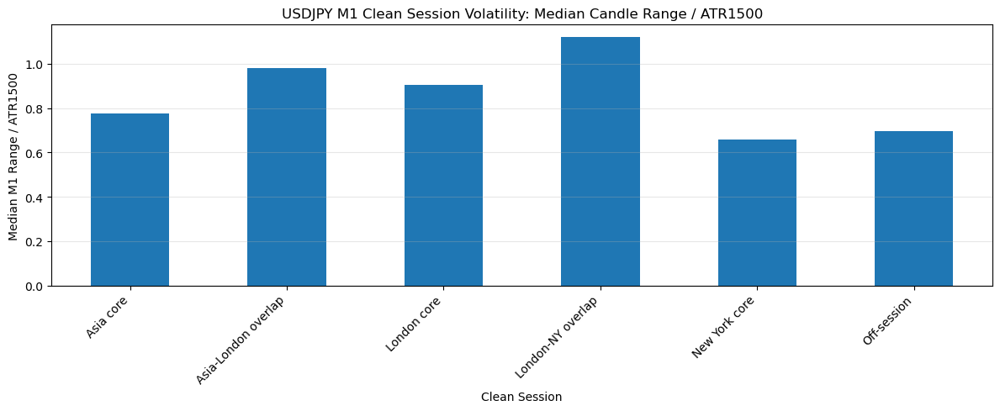

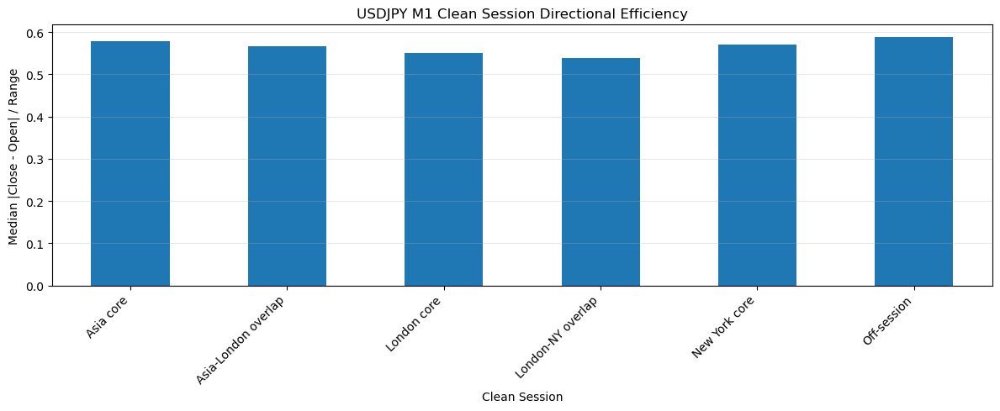

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,62,22.128217,27.079638,31.194918,40.832737,3.161174,3.868727,0.5020,0.577839,7.000000
Asia-London overlap,62,14.163314,16.013706,17.612013,24.804010,7.081657,8.006853,0.3245,0.350839,2.000000
London core,62,18.932499,23.376645,26.512085,32.828720,4.207222,5.194810,0.4135,0.516823,4.500000
London-NY overlap,62,15.603766,17.001647,19.176791,24.149938,6.241506,6.809400,0.3385,0.369952,2.500000
New York core,62,30.692156,36.066094,44.405932,59.559802,5.279580,6.251511,0.7140,0.808194,5.916667
Off-session,62,11.916543,13.868189,16.604811,22.377540,5.958271,6.937508,0.2605,0.294661,2.000000


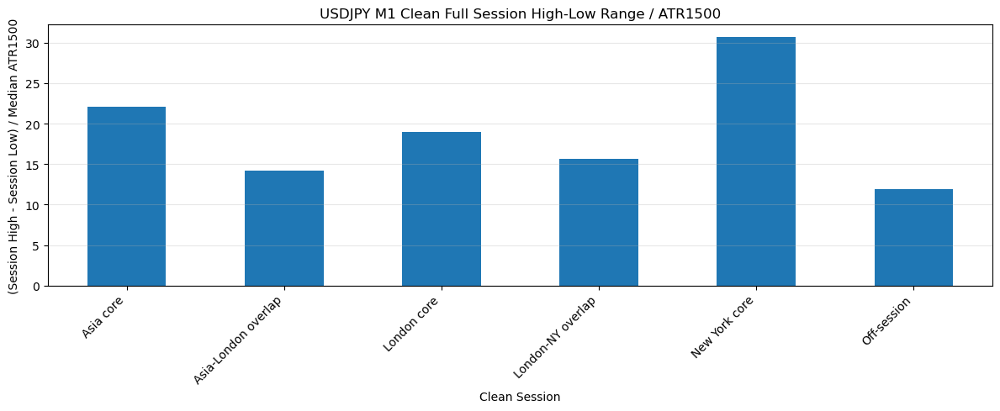

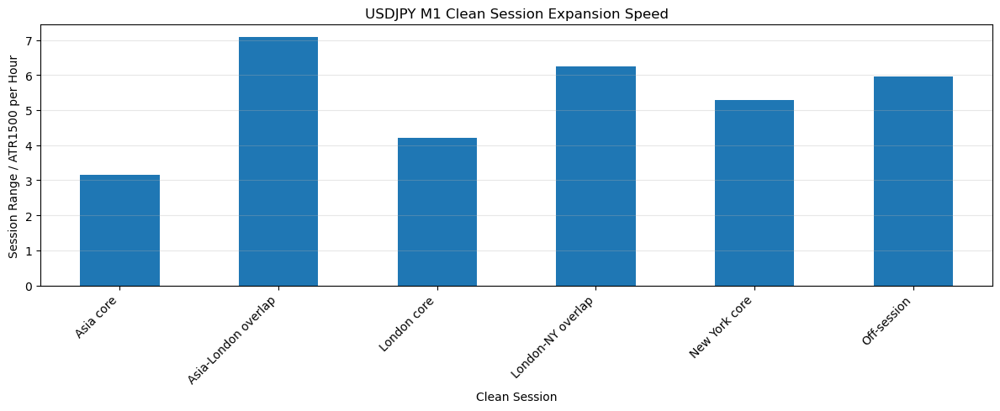

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


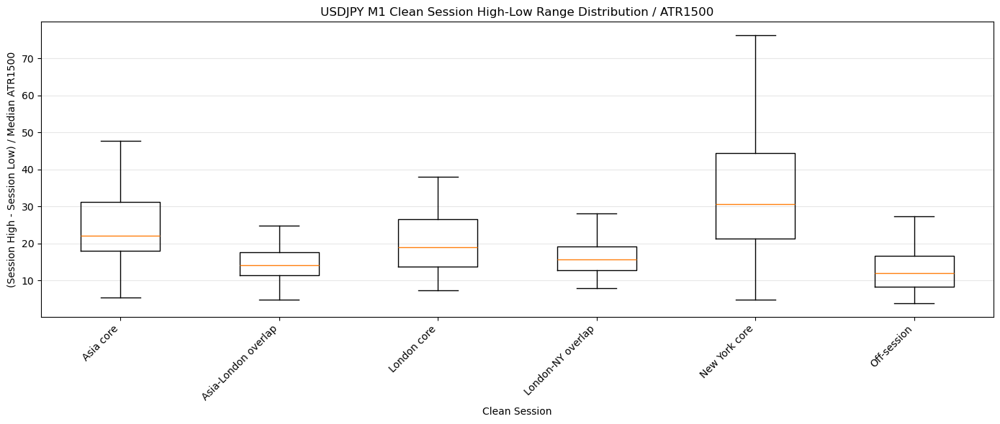

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
month_name,,,,,,,,,,,,,,,
January,870,1.06,1.190731,1.4500,2.0000,1.092694,1.340646,1.757185,0.405610,0.444444,0.555556,0.985807,1.007719,1.022772,0.967136
February,810,0.98,1.093532,1.3500,1.8119,1.017927,1.205118,1.607207,0.373309,0.440000,0.560000,0.903851,0.891040,0.937251,0.900911
March,890,1.04,1.180876,1.4600,1.9910,1.126657,1.334457,1.836587,0.416366,0.461196,0.538804,0.926063,0.932595,0.956354,0.962283
April,857,0.95,1.111173,1.3200,1.8500,1.035396,1.236603,1.674368,0.377829,0.449541,0.550459,0.900721,0.881226,0.863592,0.889097
May,879,0.93,1.060725,1.3000,1.7760,0.985828,1.166127,1.657025,0.357289,0.460784,0.539216,0.896287,0.890869,0.832154,0.856889
June,835,0.95,1.120035,1.3500,1.8920,1.032032,1.206029,1.689756,0.370598,0.454545,0.545455,0.915771,0.911162,0.879811,0.873429
July,865,0.98,1.101466,1.3600,1.9000,1.001739,1.182965,1.613794,0.396622,0.468750,0.531250,0.927654,0.931065,0.904923,0.889247
August,864,0.96,1.116597,1.3500,1.8570,1.023326,1.200738,1.637533,0.388043,0.455214,0.544786,0.891294,0.895292,0.887706,0.876974
September,838,0.96,1.145379,1.3930,2.0100,1.016909,1.210429,1.588957,0.380265,0.452277,0.547723,0.929571,0.929107,0.904329,0.907912


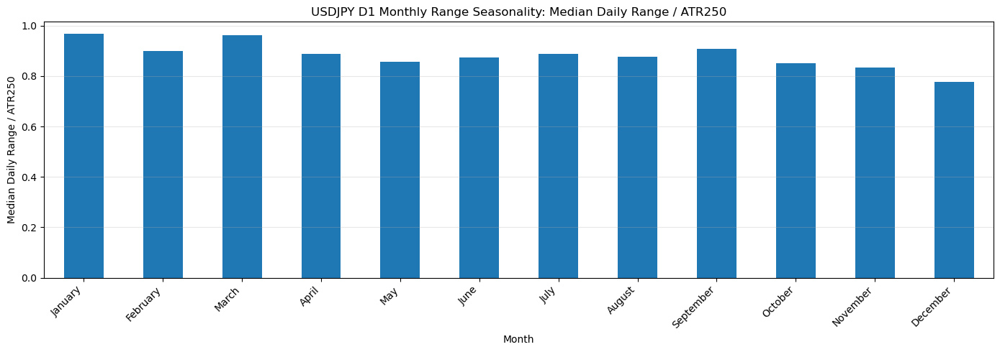

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:115: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


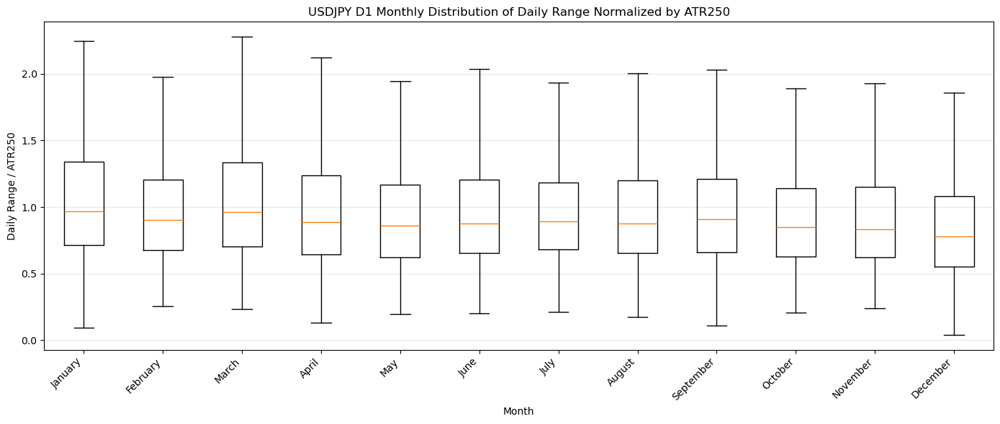

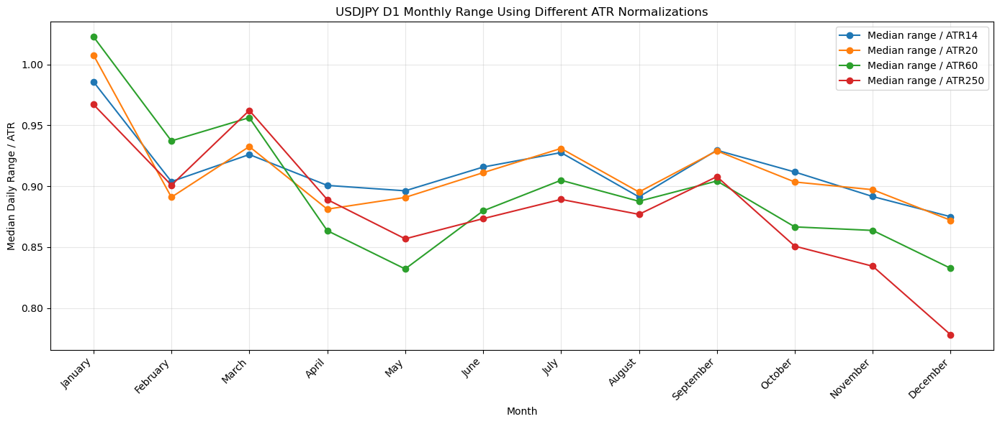

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
weekday,,,,,,,,,,,,,,,
Monday,2059,0.89,1.026042,1.270,1.750,0.940884,1.136737,1.518621,0.355858,0.461538,0.538462,0.845361,0.839631,0.826343,0.818861
Tuesday,2052,0.94,1.079413,1.320,1.800,0.989914,1.164579,1.590731,0.367830,0.461649,0.538351,0.898535,0.894354,0.873826,0.861679
Wednesday,2051,0.97,1.131261,1.361,1.920,1.034882,1.220025,1.705818,0.382922,0.455882,0.544118,0.936223,0.936803,0.914194,0.895095
Thursday,2053,0.98,1.142821,1.387,1.969,1.046630,1.254205,1.676455,0.376984,0.436842,0.563158,0.940247,0.936390,0.921736,0.905691
Friday,2045,1.00,1.154413,1.400,1.986,1.058512,1.276418,1.720480,0.391182,0.462264,0.537736,0.951613,0.954724,0.928837,0.917229


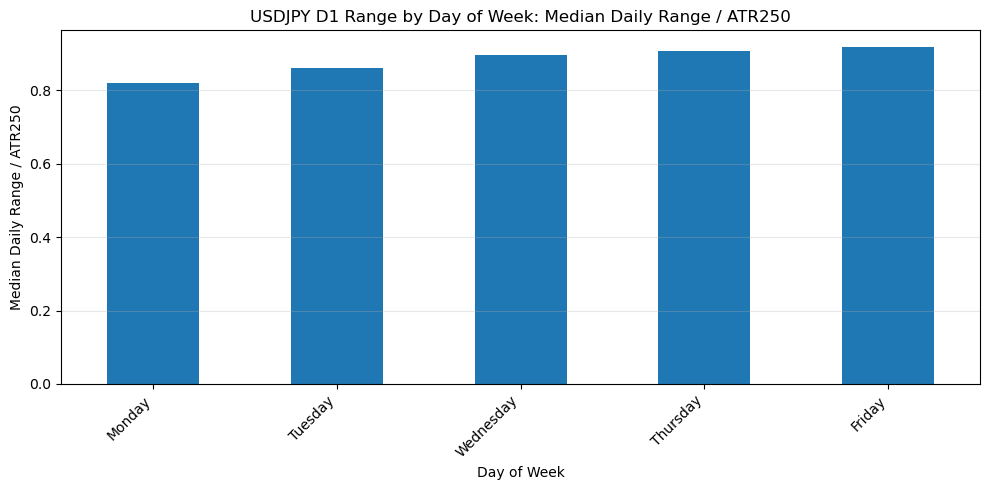

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:173: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


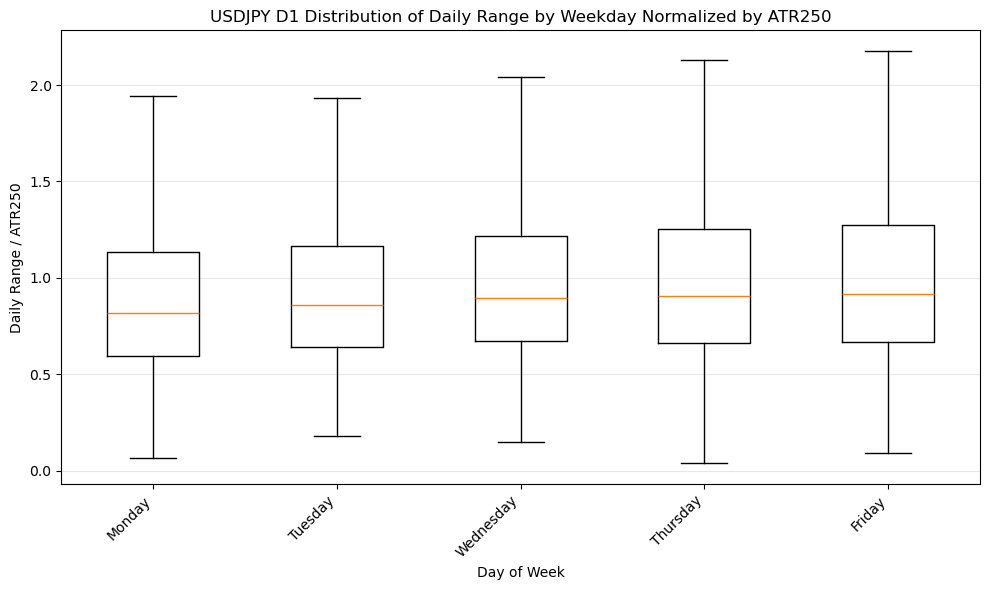

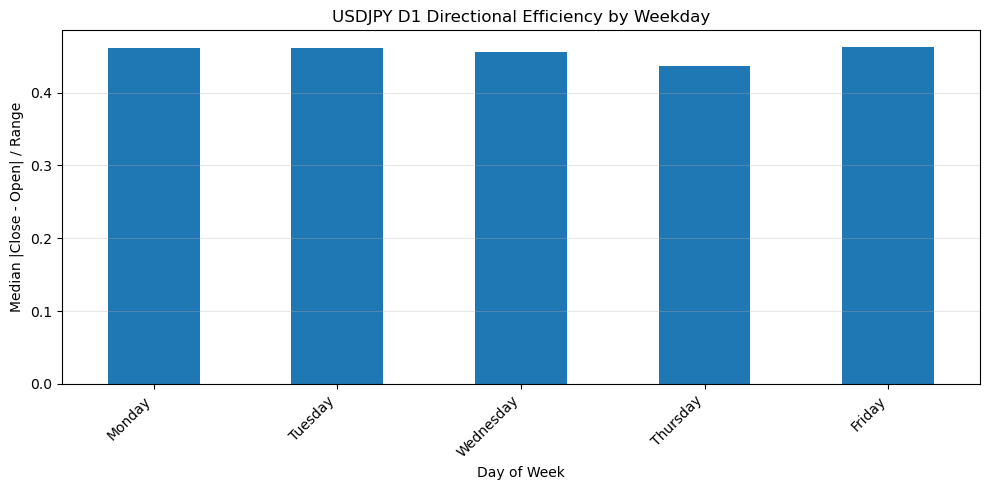

In [23]:
usdjpy_m5 = analyze_asset_csv(r"mt5_data\USDJPYzero_M5_max_bars.csv", timeframe="M5", asset_name="USDJPY")
usdjpy_m1 = analyze_asset_csv(r"mt5_data\USDJPYzero_M1_max_bars.csv", timeframe="M1", asset_name="USDJPY")
usdjpy_d1 = analyze_asset_csv(r"mt5_data\USDJPYzero_D1_max_bars.csv", timeframe="D1", asset_name="USDJPY")

## S&P

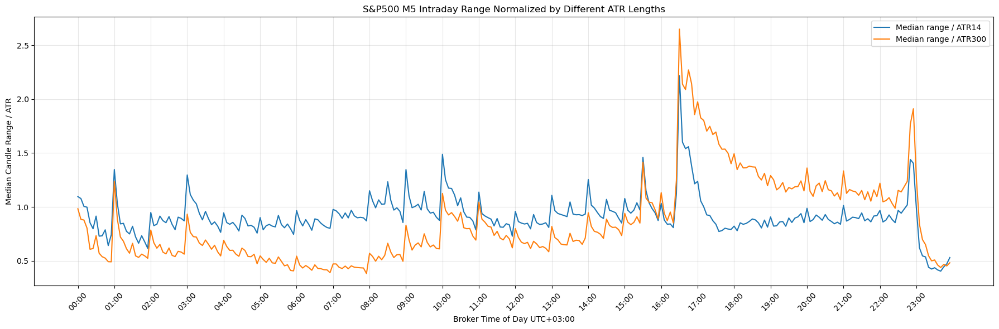

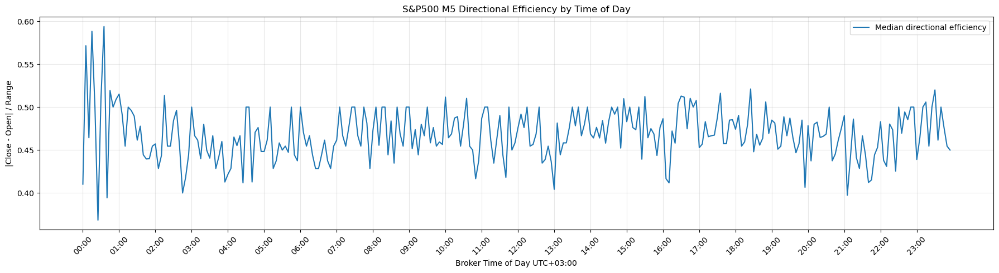

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,27656,0.542192,0.633593,0.769295,1.063055,0.228039,0.461538,0.538462,128.0,149.213444
Asia-London overlap,7896,0.819536,0.930016,1.118386,1.494934,0.353972,0.467742,0.532258,201.0,206.800405
London core,17763,0.786164,0.941036,1.106671,1.550121,0.348675,0.470588,0.529412,183.0,199.239543
London-NY overlap,9869,1.611310,1.818795,2.230744,3.009695,0.712420,0.480000,0.520000,391.0,361.836154
New York core,18604,1.078490,1.263665,1.543445,2.153488,0.447522,0.465317,0.534683,294.0,275.978929
Off-session,7909,0.621755,0.761686,0.901899,1.326754,0.263919,0.463415,0.536585,135.0,149.975597


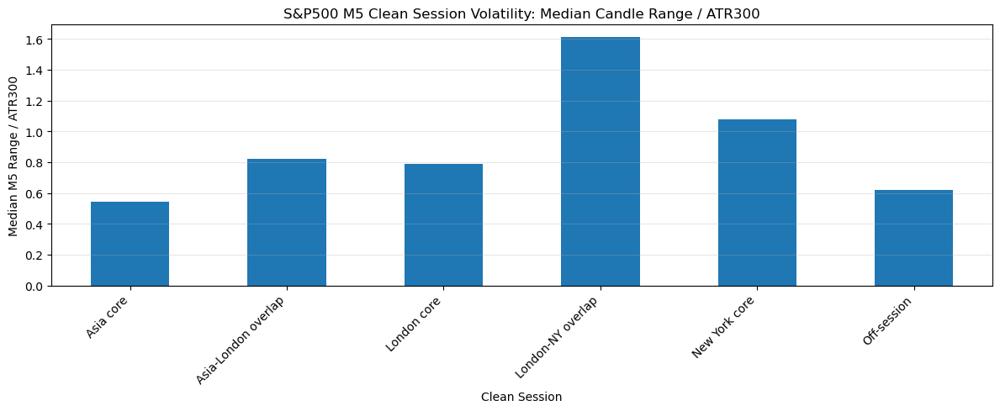

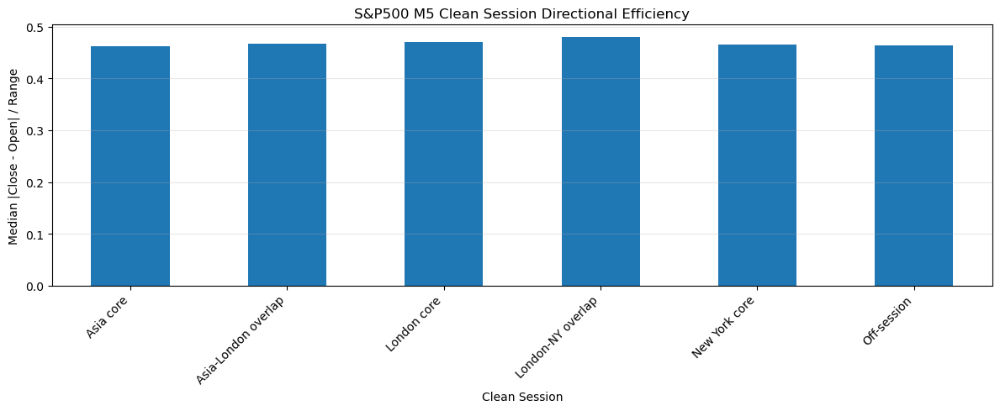

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,330,5.966940,6.666949,7.626342,10.747873,0.857770,0.957798,21.90,28.227273,7.0
Asia-London overlap,329,4.441759,4.952532,5.806117,7.624783,2.220879,2.476266,17.80,21.257751,2.0
London core,331,6.766069,7.747678,8.957721,12.405112,1.505549,1.744961,26.00,33.640483,4.5
London-NY overlap,329,9.966358,10.825016,13.264997,16.381768,3.986543,4.330225,42.60,48.989362,2.5
New York core,329,9.709242,10.938820,13.428202,19.103175,2.068966,2.343363,39.70,51.183587,5.0
Off-session,330,3.531518,4.177817,4.868673,6.833450,1.765759,2.092553,14.85,18.331515,2.0


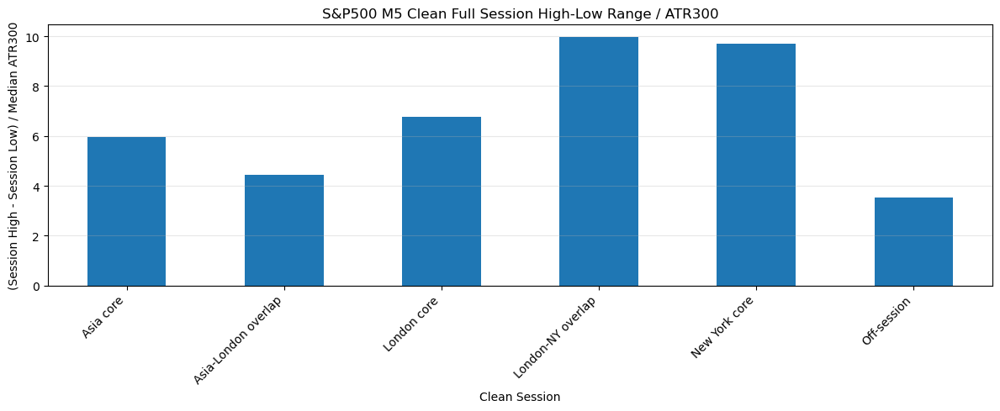

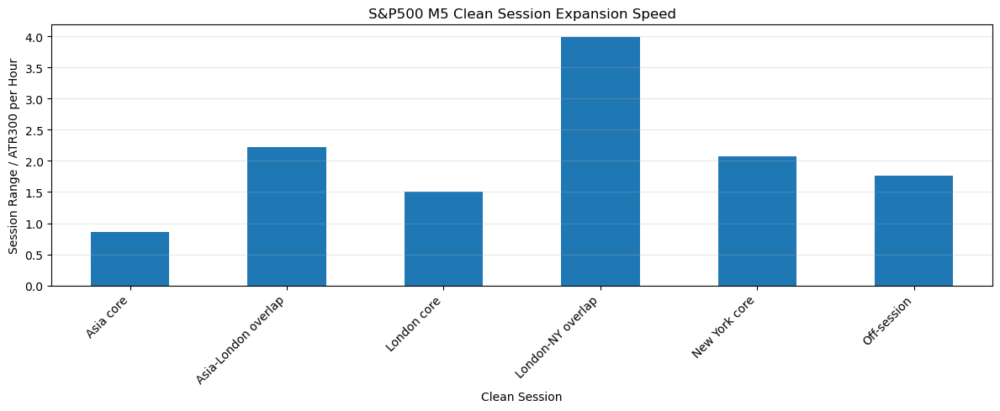

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


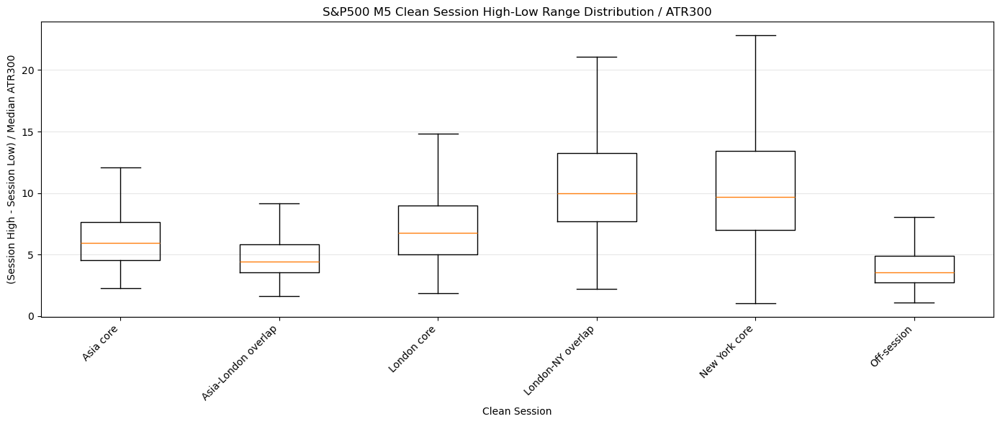

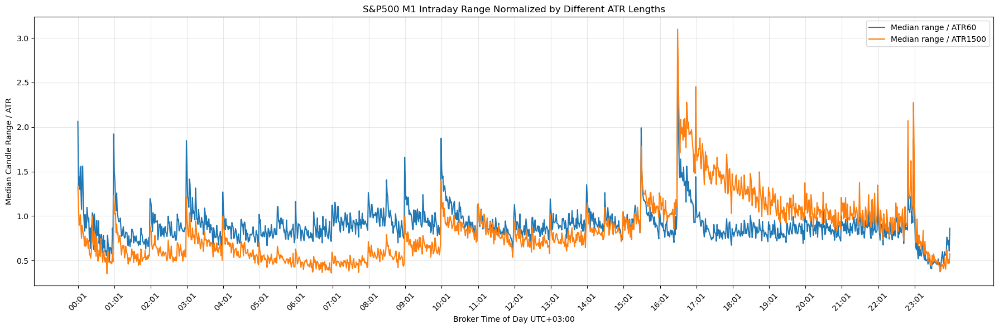

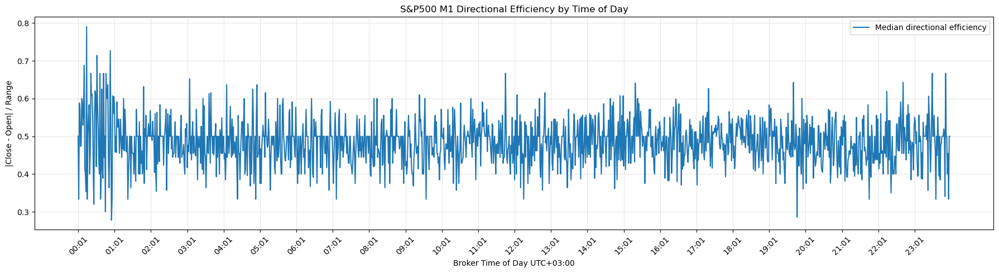

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,27300,0.565316,0.670566,0.808356,1.138218,0.247199,0.500000,0.500000,53.0,52.897692
Asia-London overlap,7799,0.856298,0.958810,1.172132,1.558955,0.384238,0.500000,0.500000,64.0,64.242723
London core,17529,0.852163,1.043888,1.220504,1.781804,0.383943,0.500000,0.500000,64.0,65.229562
London-NY overlap,9577,1.479549,1.716294,2.079341,2.837139,0.673017,0.490196,0.509804,90.0,89.621176
New York core,18545,0.950911,1.139686,1.386487,1.957518,0.406862,0.476190,0.523810,74.0,73.018549
Off-session,7749,0.602349,0.756106,0.910229,1.330460,0.268998,0.500000,0.500000,46.0,48.477223


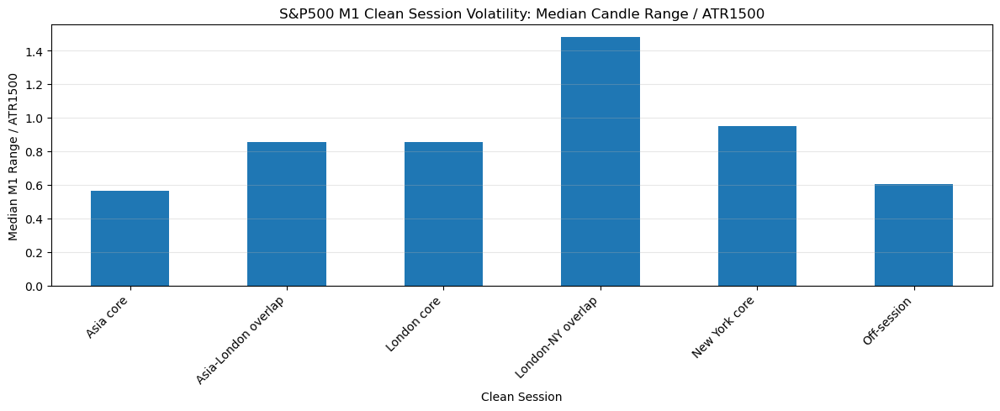

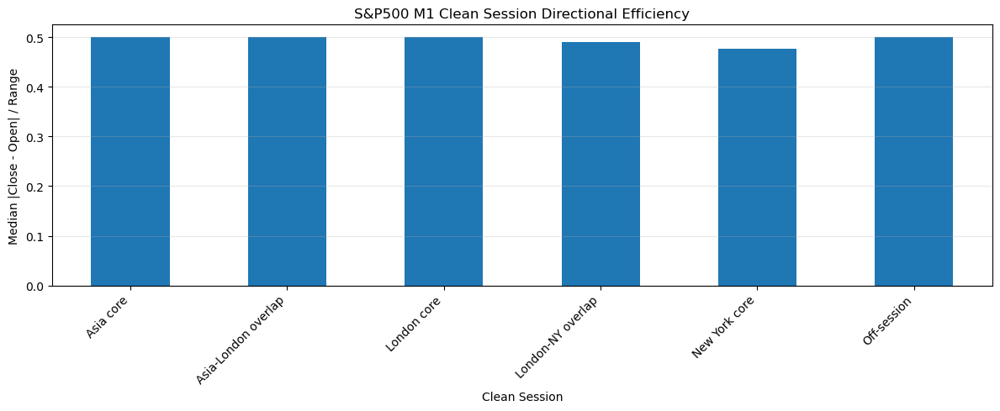

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,65,14.744960,16.747794,19.241479,29.462587,2.106423,2.392542,30.40,36.344615,7.000000
Asia-London overlap,65,10.247156,11.159073,12.031281,17.419939,5.123578,5.580172,19.60,24.684615,2.000000
London core,65,17.370326,19.913066,24.278116,29.516662,3.860072,4.429003,42.90,44.175385,4.500000
London-NY overlap,64,19.948868,23.183043,26.889445,35.972539,7.979547,9.302298,49.10,52.543750,2.500000
New York core,64,22.707794,24.906359,29.361448,44.081213,4.684626,5.137760,46.05,58.070313,5.000000
Off-session,65,8.612617,9.738545,10.518856,15.652476,4.342496,4.899995,17.80,21.749231,1.983333


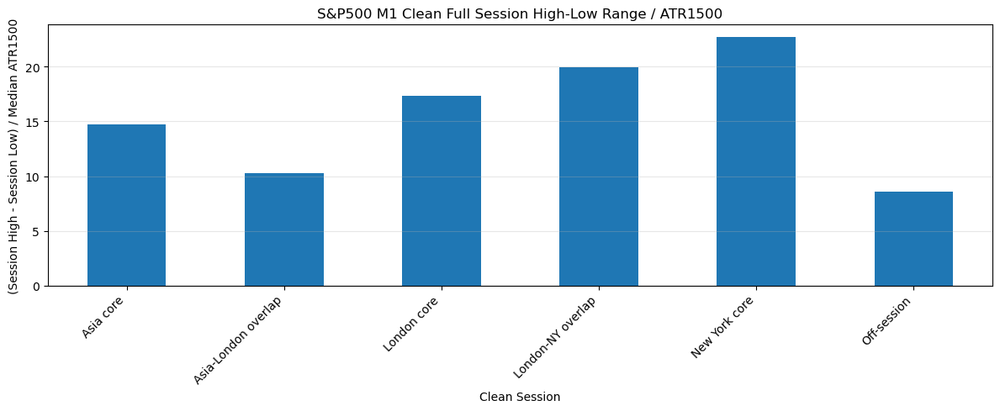

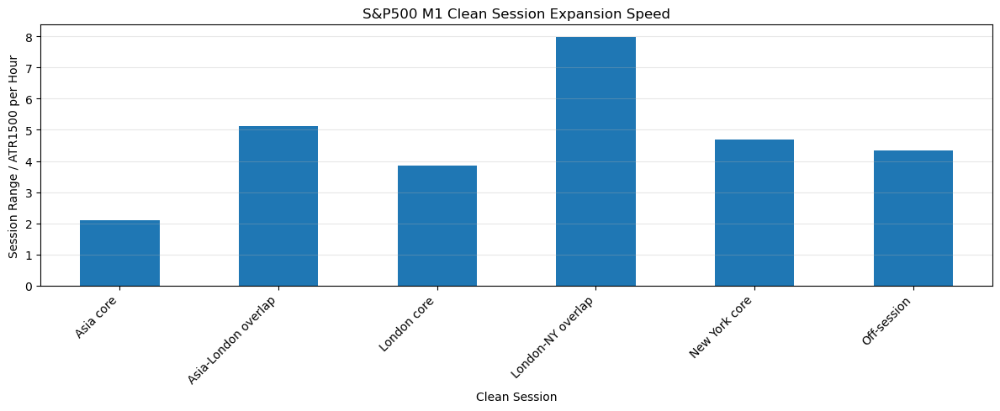

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


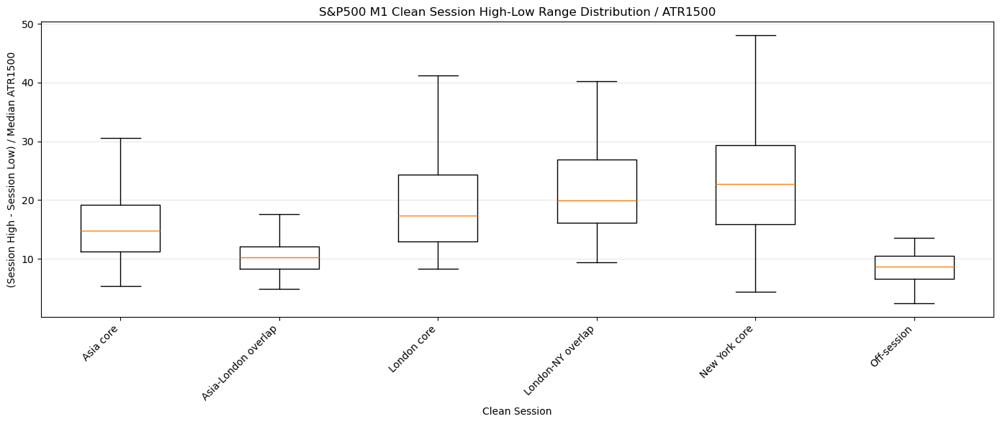

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
month_name,,,,,,,,,,,,,,,
January,214,44.60,52.933645,67.625,100.69,1.067307,1.309839,1.868482,0.357207,0.438626,0.561374,1.006782,0.975151,0.928536,0.872223
February,201,49.50,59.552239,81.900,116.90,1.300725,1.577356,2.399043,0.411353,0.461847,0.538153,0.873582,0.883002,1.009763,0.936918
March,219,68.70,80.868950,115.850,157.96,1.587702,1.800108,3.314862,0.604576,0.510756,0.489244,0.980676,1.031371,1.128795,1.221890
April,209,53.30,71.525359,88.700,128.80,1.296405,1.561316,2.242349,0.482204,0.511976,0.488024,0.855849,0.816057,0.819567,1.076239
May,216,50.65,55.595370,76.325,101.20,1.028523,1.282475,1.678146,0.404824,0.457567,0.542433,0.906836,0.890774,0.755954,0.955421
June,192,40.80,49.363542,66.525,93.75,0.931683,1.160297,1.601456,0.310572,0.447368,0.552632,0.905665,0.875335,0.763918,0.839259
July,199,36.70,43.529648,59.650,80.32,0.824356,0.999892,1.334119,0.345135,0.493151,0.506849,0.943372,0.917313,0.800000,0.734020
August,200,42.35,49.347000,62.650,91.45,0.968235,1.129628,1.718529,0.347329,0.501981,0.498019,0.889815,0.893785,0.912956,0.787867
September,192,44.00,51.188021,67.075,98.13,0.910895,1.093795,1.479160,0.318471,0.408002,0.591998,0.945959,0.937195,0.922808,0.809715


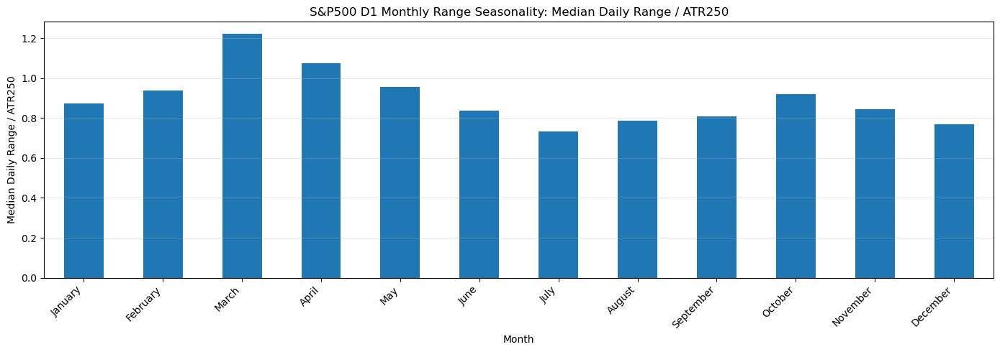

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:115: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


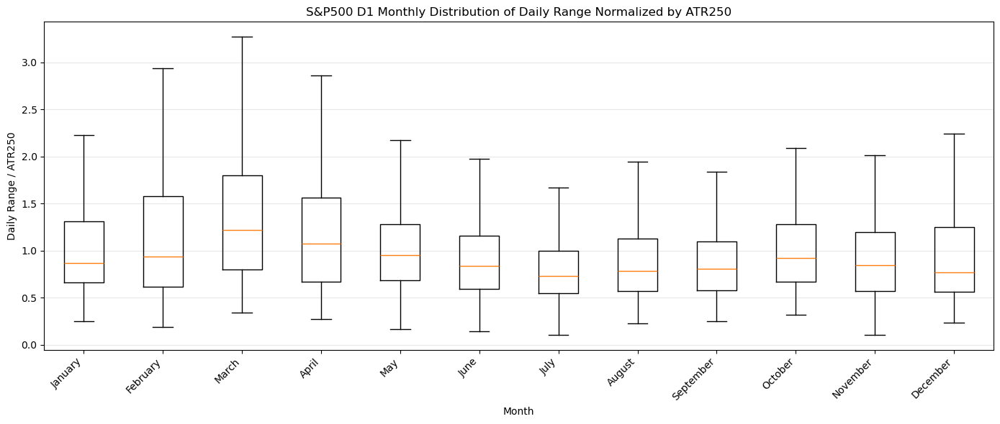

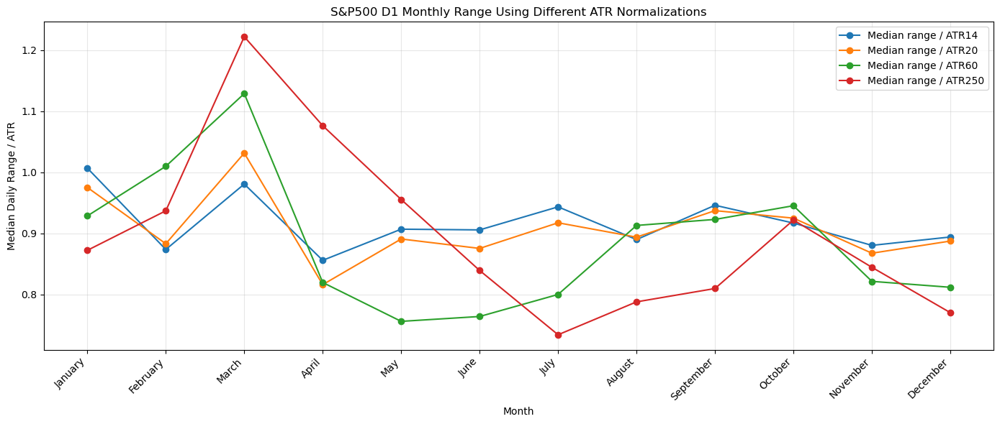

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
weekday,,,,,,,,,,,,,,,
Monday,484,42.9,53.989256,67.850,107.06,1.035961,1.194658,1.939131,0.357703,0.480096,0.519904,0.829180,0.829475,0.794729,0.806614
Tuesday,490,45.7,54.429592,75.450,97.52,1.053741,1.269294,1.808402,0.360684,0.455051,0.544949,0.888341,0.868804,0.864839,0.871853
Wednesday,488,48.3,57.570082,73.900,109.37,1.099824,1.303478,1.862148,0.388241,0.453649,0.546351,0.938795,0.914376,0.893376,0.886903
Thursday,490,49.1,59.041429,77.525,110.55,1.134026,1.387774,1.894739,0.411793,0.467125,0.532875,0.979475,0.956344,0.914906,0.929816
Friday,482,46.8,57.323859,74.275,114.68,1.094863,1.326323,1.882854,0.396531,0.472140,0.527860,0.946621,0.940845,0.900153,0.894104


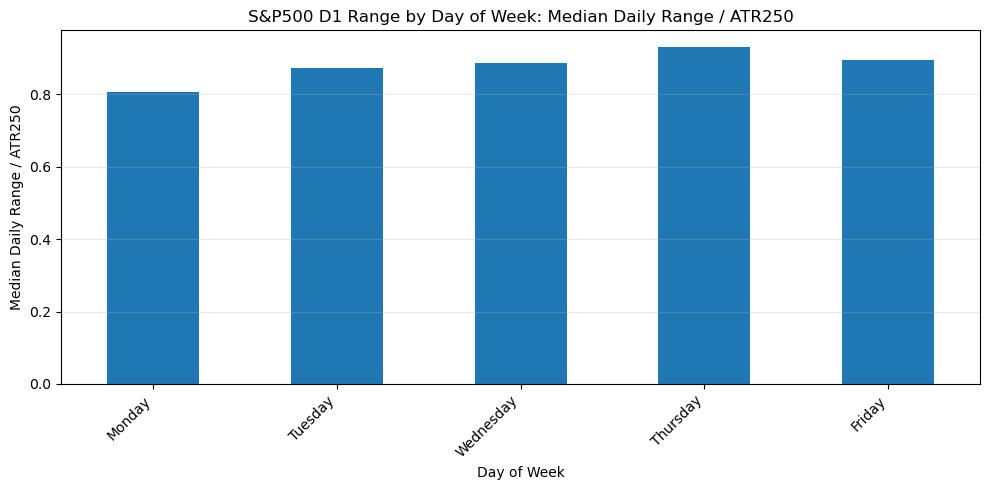

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:173: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


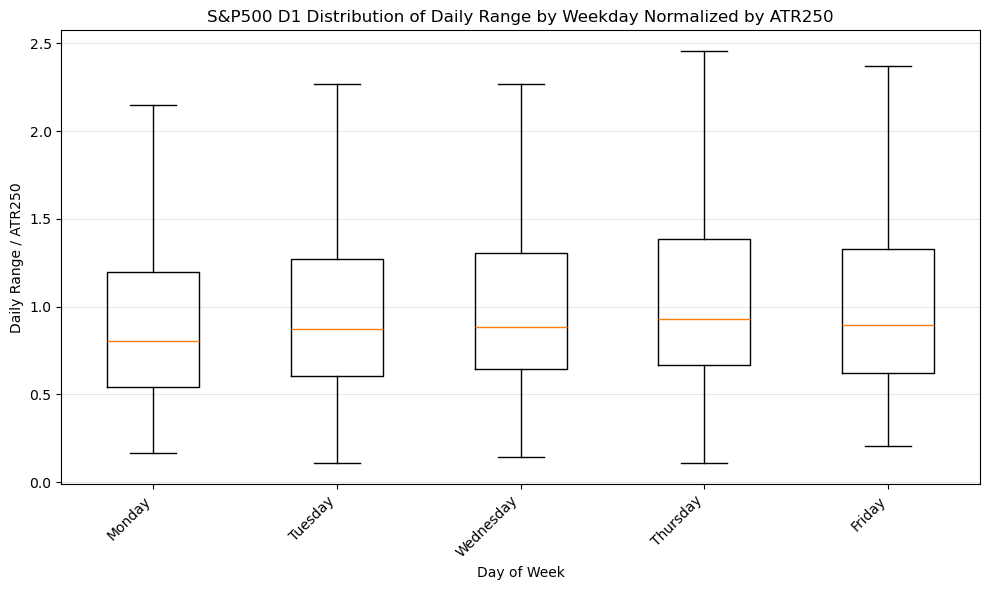

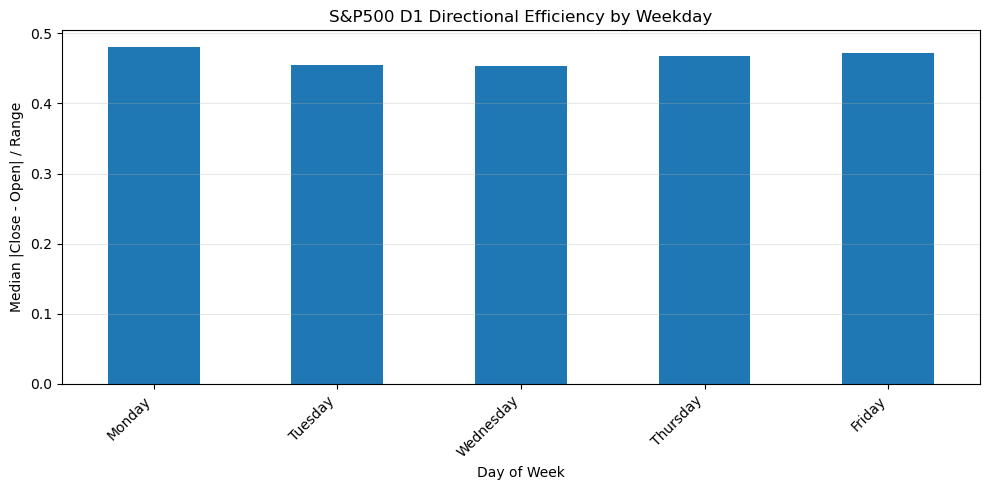

In [24]:
SP_m5 = analyze_asset_csv(r"mt5_data\SP500_M5_max_bars.csv", timeframe="M5", asset_name="S&P500")
SP_m1 = analyze_asset_csv(r"mt5_data\SP500_M1_max_bars.csv", timeframe="M1", asset_name="S&P500")
SP_d1 = analyze_asset_csv(r"mt5_data\SP500_D1_max_bars.csv", timeframe="D1", asset_name="S&P500")

## DowJones

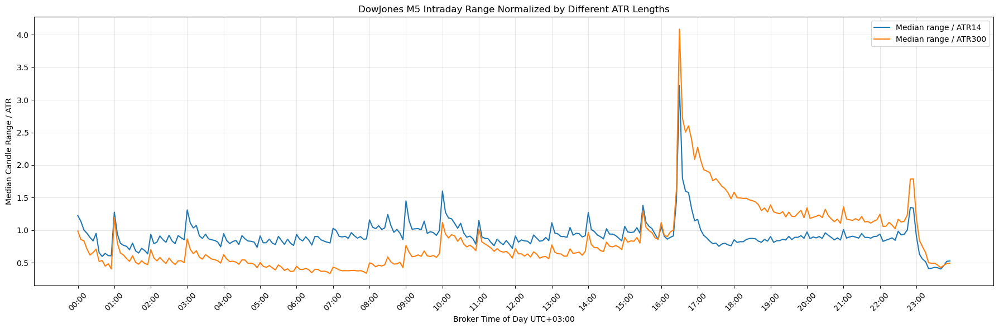

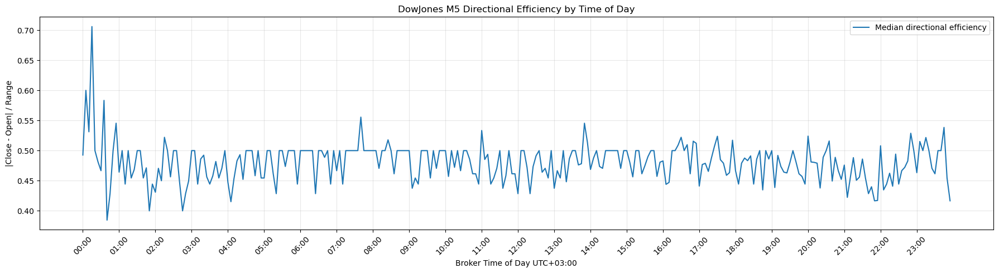

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,27657,0.485175,0.569012,0.689906,0.958020,0.213645,0.500000,0.500000,77.0,96.790975
Asia-London overlap,7896,0.784881,0.892538,1.071605,1.445215,0.349583,0.478261,0.521739,140.0,158.737969
London core,17765,0.755192,0.930987,1.079758,1.571616,0.337901,0.484848,0.515152,130.0,156.180017
London-NY overlap,9866,1.737267,2.011873,2.418025,3.301901,0.793820,0.484756,0.515244,364.0,365.708899
New York core,18603,1.125000,1.279492,1.563153,2.151414,0.463008,0.472222,0.527778,252.0,254.213245
Off-session,7912,0.564702,0.693110,0.820444,1.206682,0.242620,0.466667,0.533333,77.0,95.126390


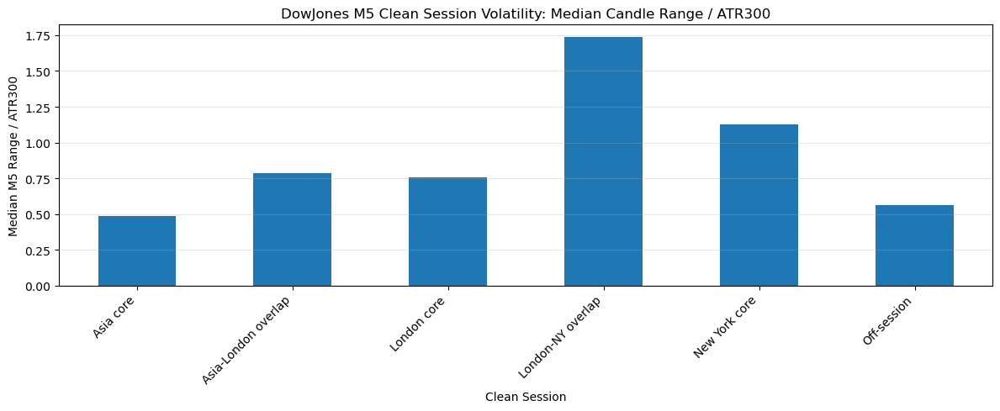

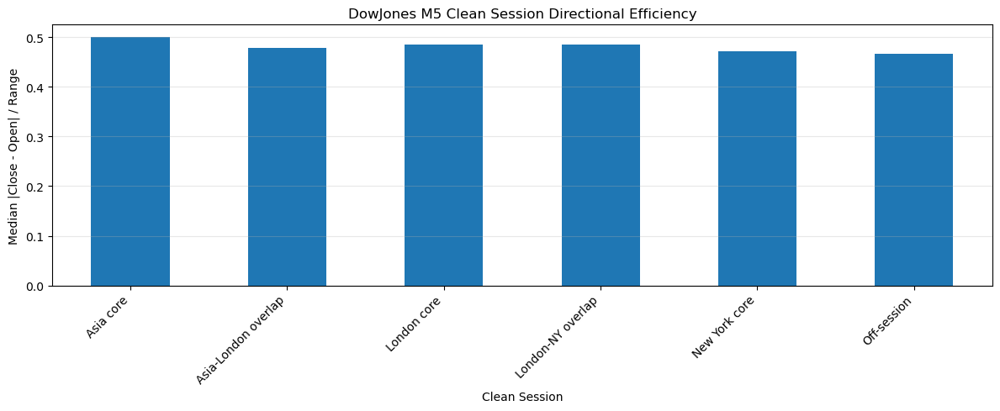

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,330,5.297887,5.877450,6.937443,9.743210,0.758037,0.844135,129.0,169.790909,7.0
Asia-London overlap,329,4.246492,4.759816,5.806163,7.054290,2.123246,2.379908,114.0,137.604863,2.0
London core,331,7.243289,8.383522,9.511737,14.514736,1.613892,1.894281,192.0,243.432024,4.5
London-NY overlap,329,11.327583,12.174464,14.871911,18.418596,4.531033,4.871060,335.0,368.693009,2.5
New York core,329,9.775967,10.930434,13.120534,17.730306,2.102062,2.347200,267.0,344.227964,5.0
Off-session,330,3.112744,3.755605,4.311514,5.926257,1.556372,1.879149,84.0,111.754545,2.0


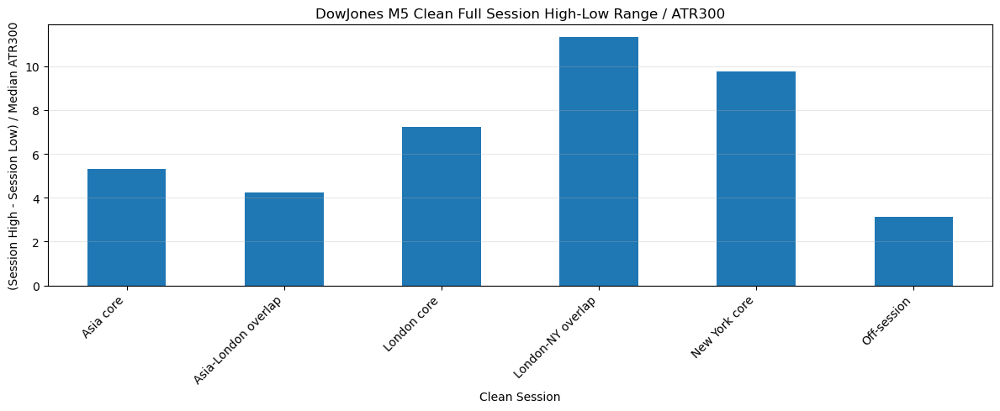

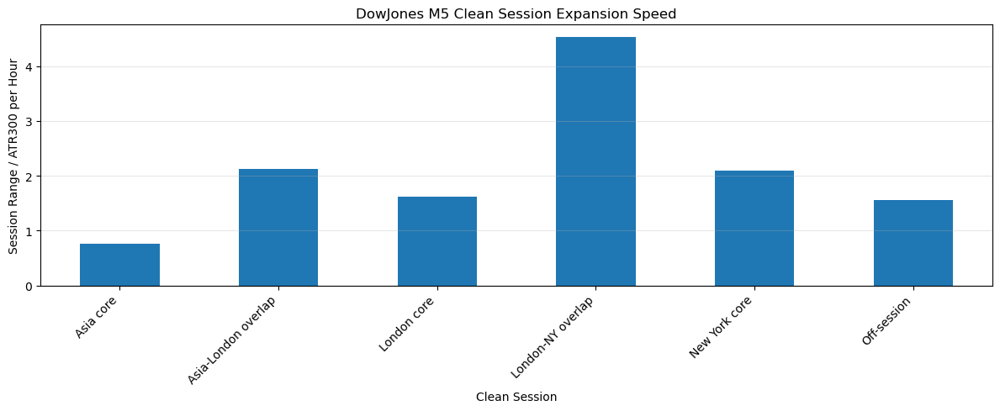

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


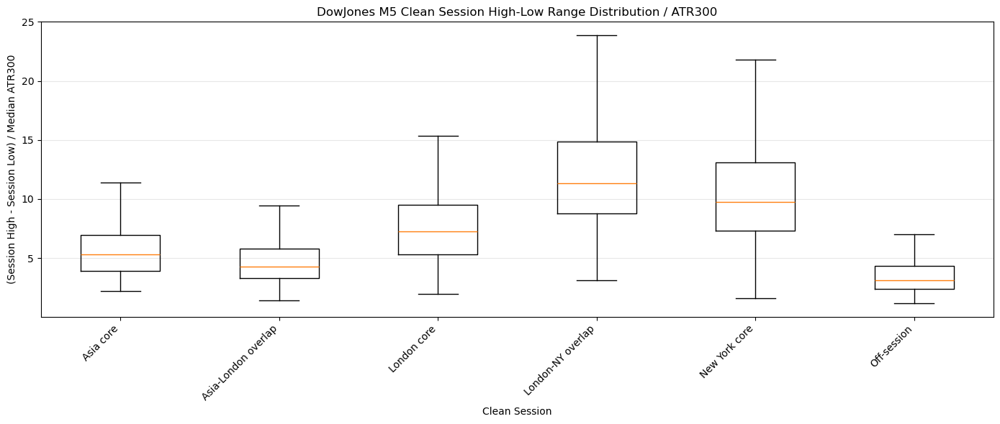

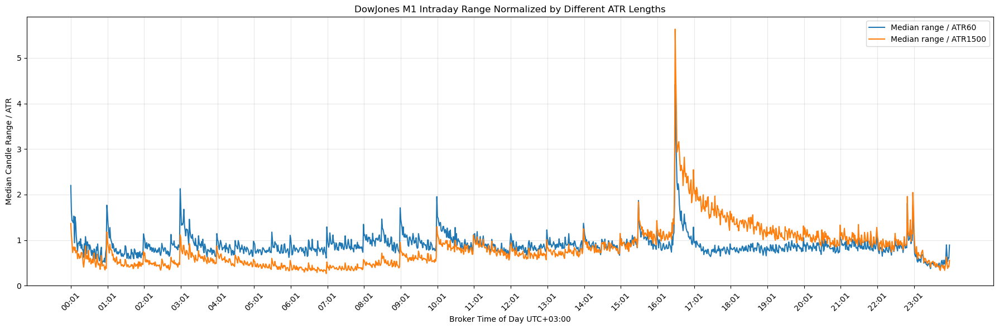

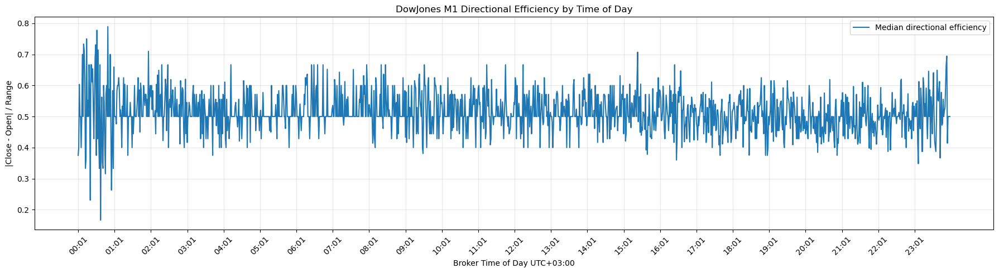

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,27260,0.489061,0.590978,0.724505,1.050008,0.224335,0.5,0.5,24.0,27.406346
Asia-London overlap,7798,0.822986,0.940971,1.155425,1.549466,0.391347,0.5,0.5,39.0,41.172608
London core,17446,0.844072,1.061512,1.240496,1.874888,0.405095,0.5,0.5,40.0,43.183939
London-NY overlap,9426,1.623834,1.950863,2.325039,3.288573,0.772550,0.5,0.5,77.0,77.751750
New York core,18806,0.957064,1.120217,1.364302,1.899632,0.419009,0.5,0.5,52.0,50.975699
Off-session,7669,0.495587,0.649592,0.786876,1.197208,0.234933,0.5,0.5,20.0,24.790585


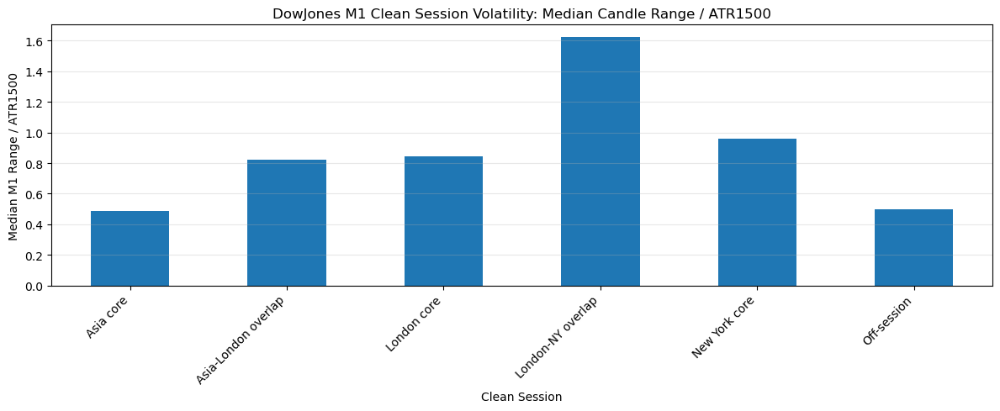

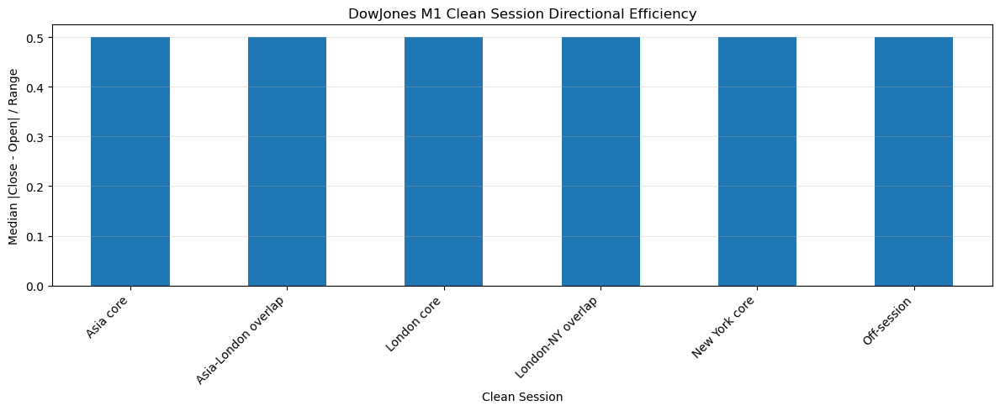

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,65,13.793103,15.502695,18.429051,26.535977,1.970443,2.214795,192.0,228.630769,7.000000
Asia-London overlap,65,10.612850,11.932926,15.016344,17.894237,5.306425,5.967078,145.0,173.446154,2.000000
London core,65,21.009772,23.743632,28.645248,35.248043,4.668838,5.325318,320.0,349.538462,4.500000
London-NY overlap,63,22.527023,26.888084,33.448513,40.447610,9.010809,10.776874,374.0,406.365079,2.500000
New York core,64,22.028074,25.072110,30.484671,38.731185,4.691922,5.128964,305.5,393.500000,5.000000
Off-session,65,7.511267,8.766113,10.032096,13.012901,3.761281,4.420201,108.0,131.938462,1.983333


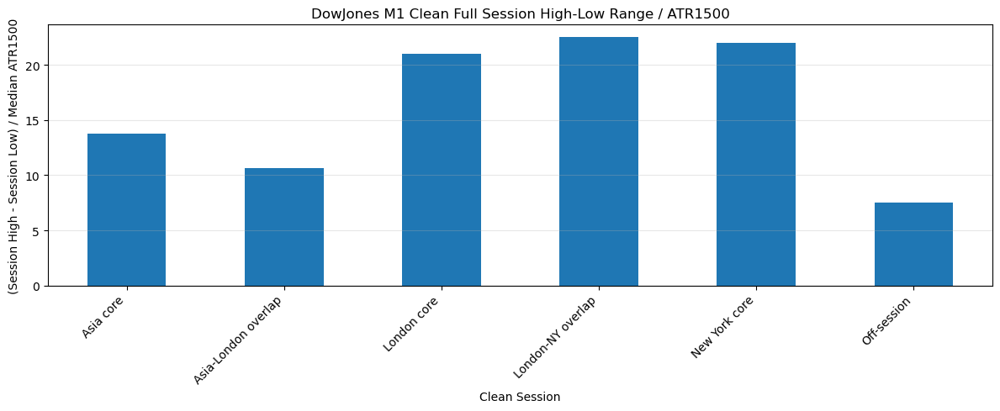

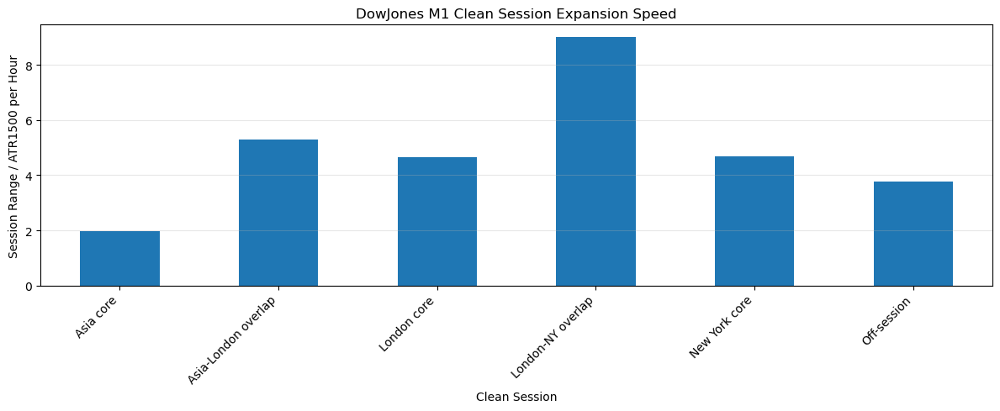

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


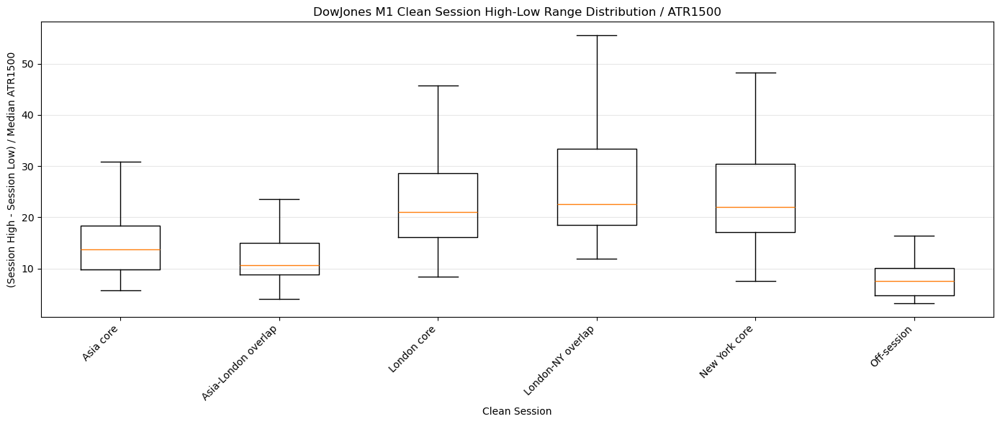

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
month_name,,,,,,,,,,,,,,,
January,214,355.5,401.822430,523.25,746.0,1.059010,1.276383,1.759818,0.405561,0.444771,0.555229,1.021430,1.024250,0.993439,0.946672
February,201,407.0,459.935323,591.00,809.0,1.321331,1.432292,2.487733,0.388140,0.429119,0.570881,0.869500,0.885517,1.004082,0.943928
March,219,486.0,622.305936,790.00,1259.6,1.563336,1.923423,3.227066,0.544306,0.492084,0.507916,0.970399,0.991150,1.090041,1.220636
April,209,414.0,534.009569,678.00,981.4,1.280963,1.615476,2.220109,0.444561,0.465812,0.534188,0.884211,0.856505,0.810300,1.082418
May,216,396.0,427.291667,564.25,746.0,1.022228,1.274827,1.669573,0.431239,0.509156,0.490844,0.853496,0.852885,0.763990,0.911789
June,192,333.5,404.458333,522.75,761.7,0.964748,1.196005,1.590108,0.340522,0.426164,0.573836,0.928800,0.902738,0.794993,0.849846
July,199,298.0,343.391960,473.00,626.2,0.832697,1.025876,1.291758,0.322958,0.484000,0.516000,0.901450,0.902391,0.811737,0.743552
August,200,343.0,371.290000,444.25,635.8,0.924949,1.009257,1.588512,0.349921,0.448335,0.551665,0.896679,0.884238,0.851773,0.775694
September,192,340.0,392.098958,501.00,727.8,0.907420,1.112093,1.501366,0.288662,0.393109,0.606891,0.981306,0.949828,0.909343,0.788695


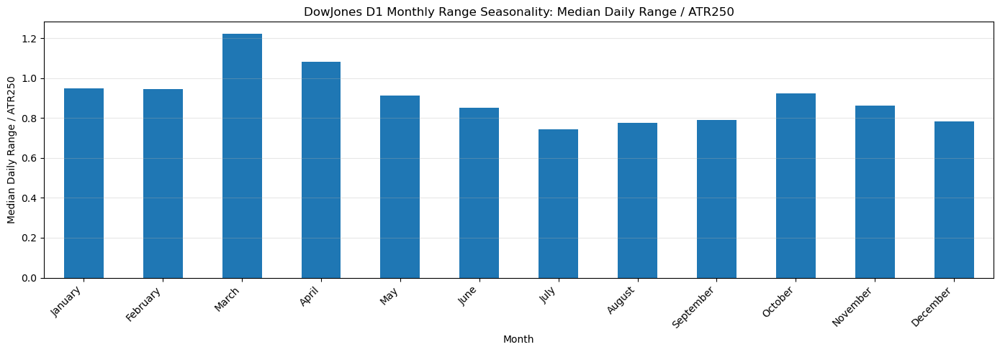

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:115: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


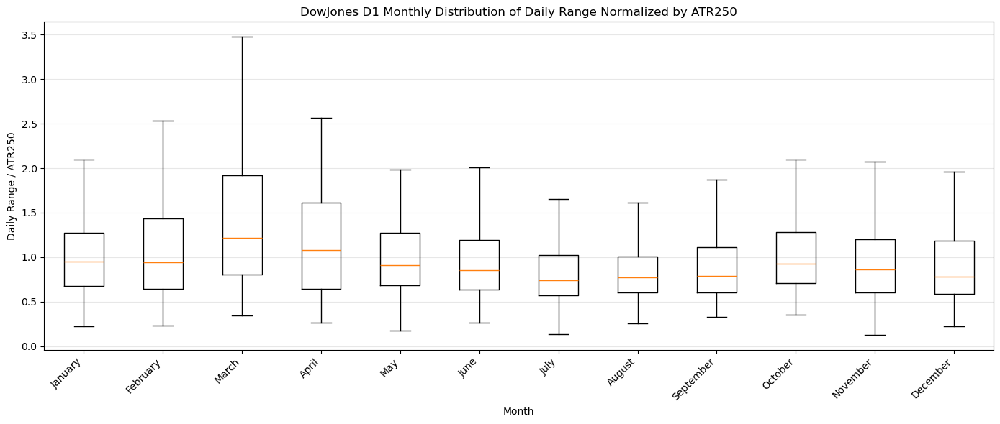

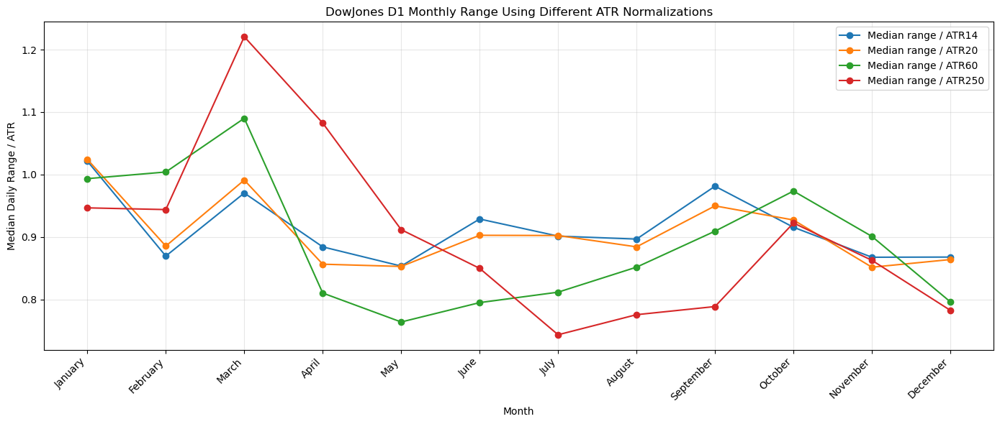

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
weekday,,,,,,,,,,,,,,,
Monday,484,347.0,424.349174,530.25,819.1,1.048045,1.237253,1.848280,0.355565,0.468200,0.531800,0.862938,0.860506,0.836843,0.825841
Tuesday,490,382.5,427.238776,538.00,742.4,1.072687,1.254239,1.785028,0.382877,0.469246,0.530754,0.921859,0.917839,0.905028,0.898507
Wednesday,488,353.0,434.479508,551.00,800.0,1.075077,1.271803,1.868200,0.353816,0.439089,0.560911,0.911677,0.890895,0.866906,0.856323
Thursday,490,398.5,450.404082,568.00,780.4,1.122922,1.330638,1.838278,0.407225,0.429212,0.570788,0.968908,0.957788,0.950008,0.938358
Friday,482,373.5,438.582988,563.50,816.6,1.078877,1.299967,1.806757,0.392457,0.463487,0.536513,0.917308,0.928761,0.903567,0.901654


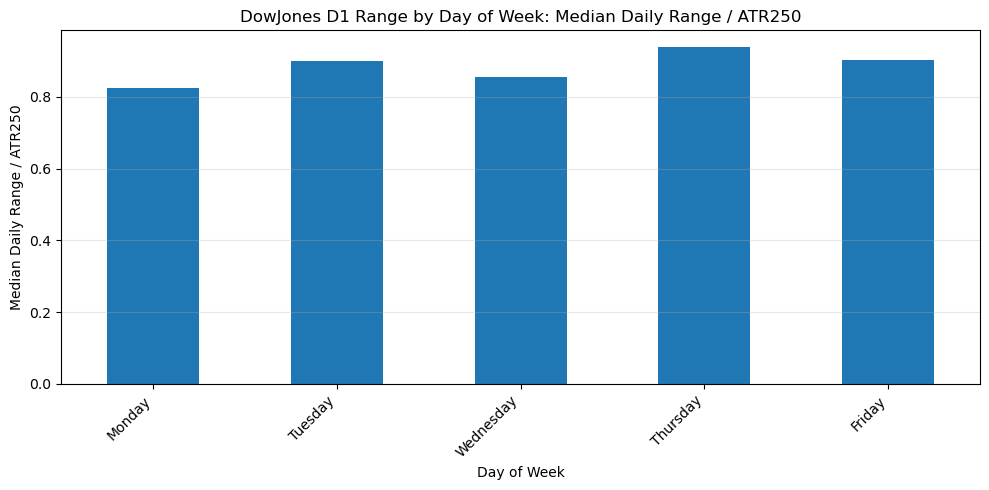

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:173: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


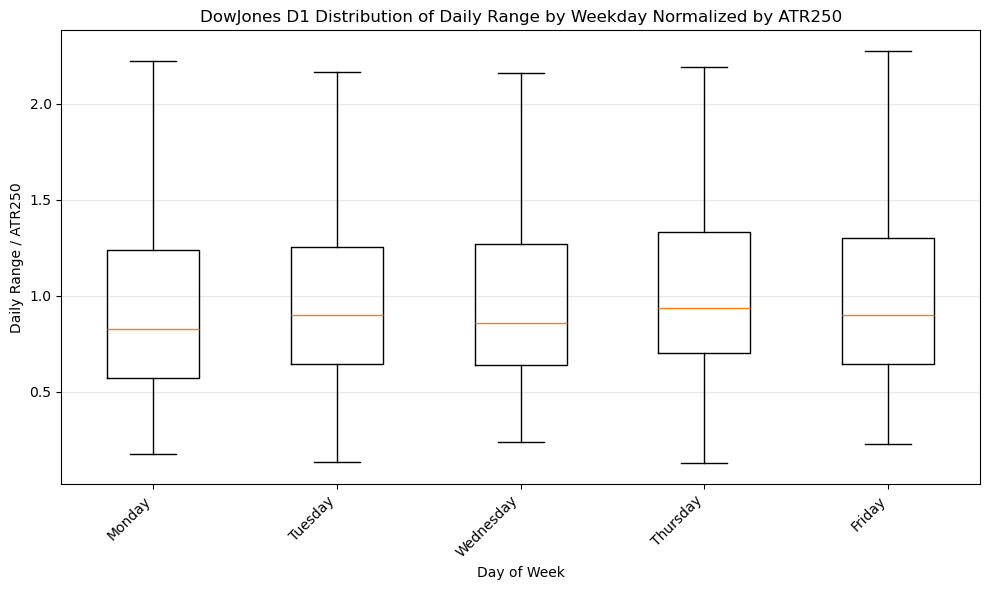

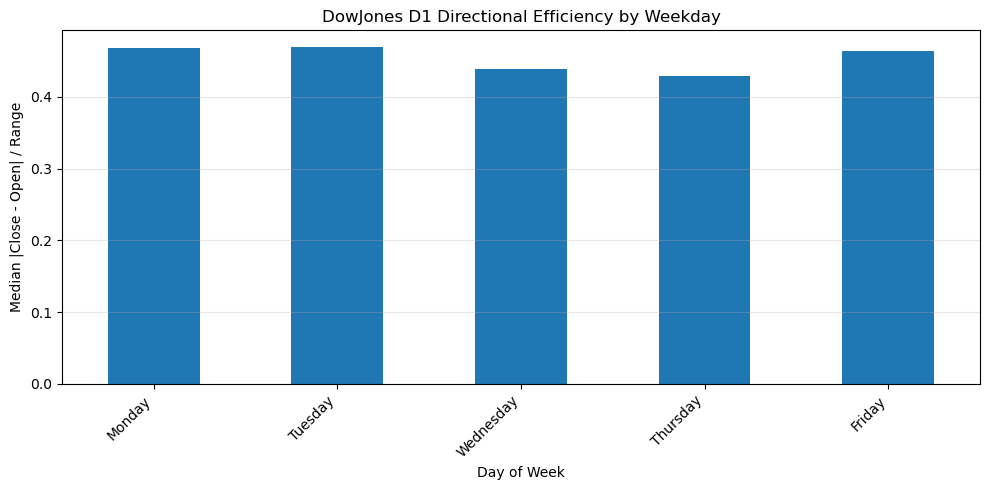

In [25]:
DowJones_m5 = analyze_asset_csv(r"mt5_data\DowJones30_M5_max_bars.csv", timeframe="M5", asset_name="DowJones")
DowJones_m1 = analyze_asset_csv(r"mt5_data\DowJones30_M1_max_bars.csv", timeframe="M1", asset_name="DowJones")
DowJones_d1 = analyze_asset_csv(r"mt5_data\DowJones30_D1_max_bars.csv", timeframe="D1", asset_name="DowJones")

## DAX30

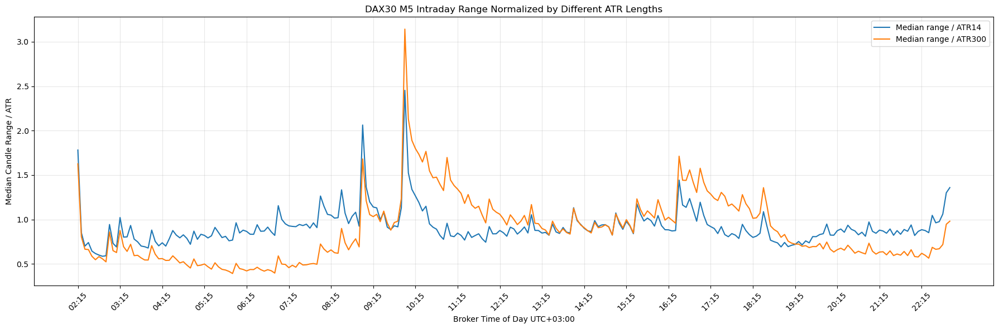

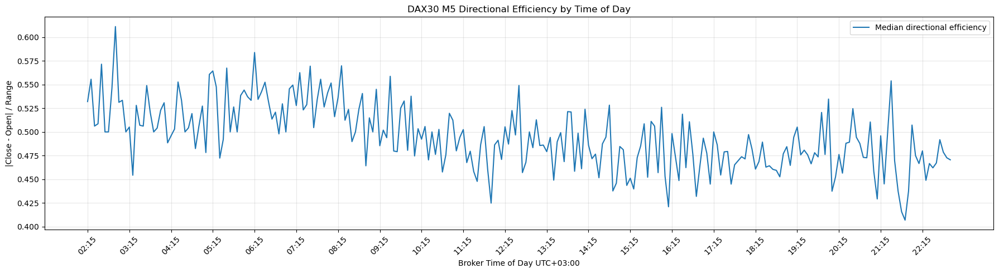

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,30439,0.595120,0.720590,0.903405,1.312074,0.275735,0.521739,0.478261,68.0,85.945169
Asia-London overlap,8880,1.444541,1.632672,1.948911,2.584587,0.662857,0.483271,0.516729,325.0,322.009459
London core,19962,0.978922,1.103979,1.294659,1.693008,0.451372,0.481818,0.518182,256.0,258.480313
London-NY overlap,11070,1.209988,1.350031,1.615800,2.113958,0.538742,0.472847,0.527153,362.0,351.648238
New York core,17685,0.673144,0.796907,0.944366,1.318669,0.294448,0.475410,0.524590,206.0,211.792140
Off-session,1646,0.646738,0.880224,1.011769,1.578757,0.310876,0.534407,0.465593,51.0,60.608748


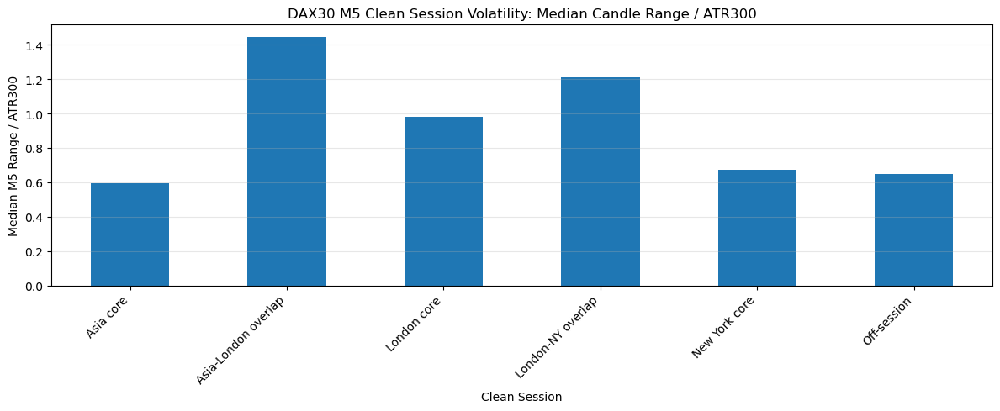

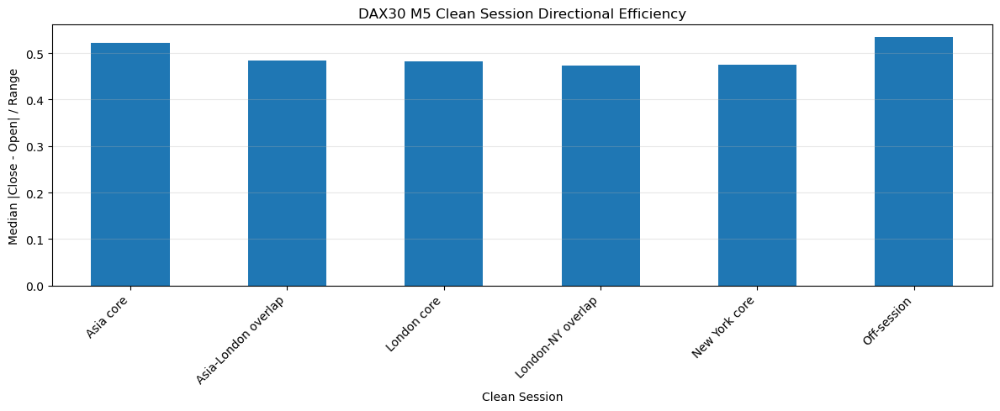

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,370,7.037261,7.697216,9.015203,12.106851,1.018104,1.123497,111.45,137.049189,6.75
Asia-London overlap,370,8.208278,8.691268,10.335368,12.398650,4.104139,4.345634,134.75,160.188649,2.00
London core,370,8.214332,9.002617,10.471911,13.076228,1.825407,2.003473,143.15,176.227297,4.50
London-NY overlap,369,7.408514,8.027246,9.441680,11.985238,2.963406,3.210898,133.80,154.896477,2.50
New York core,369,5.182602,6.051751,6.894518,10.262608,1.295650,1.514604,91.20,124.328455,4.00
Off-session,183,2.640126,3.344713,3.729694,5.256099,3.520168,4.459617,39.50,54.733333,0.75


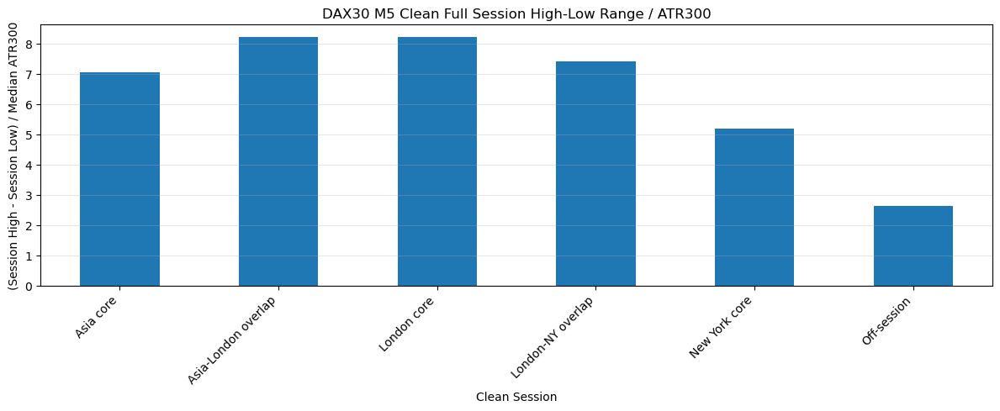

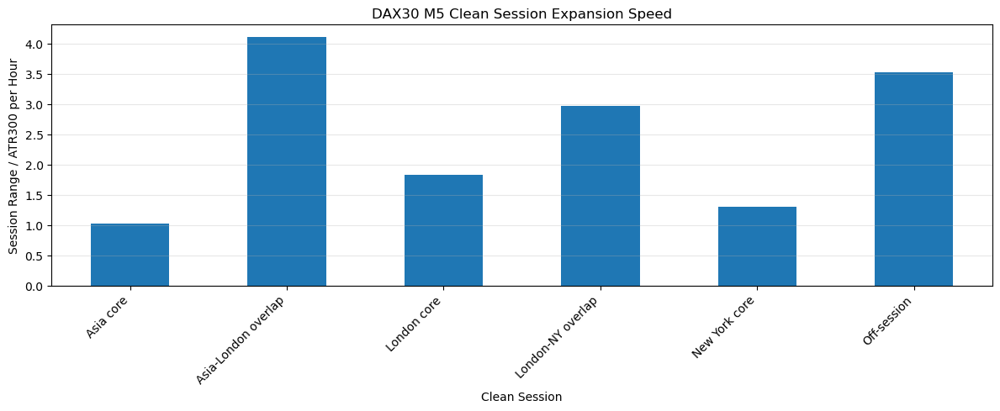

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


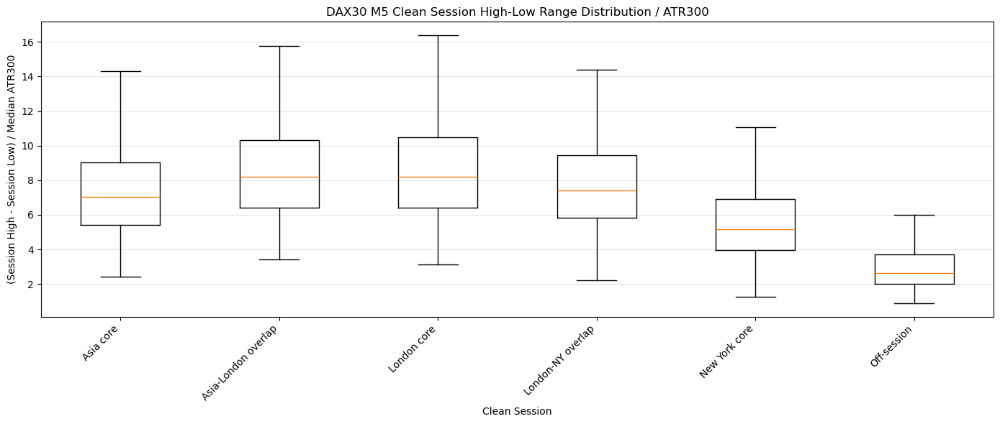

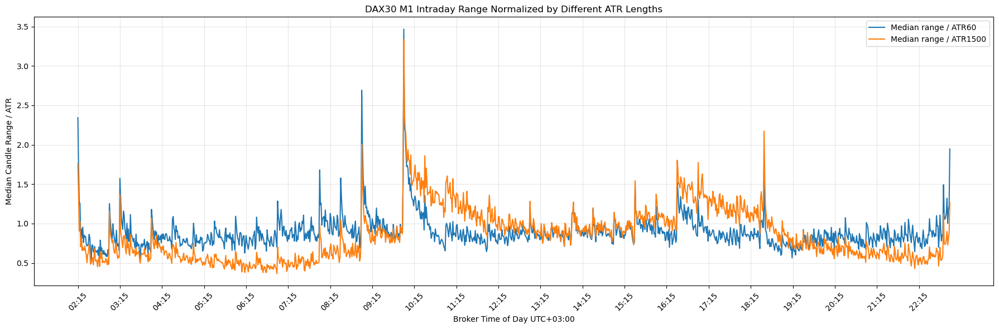

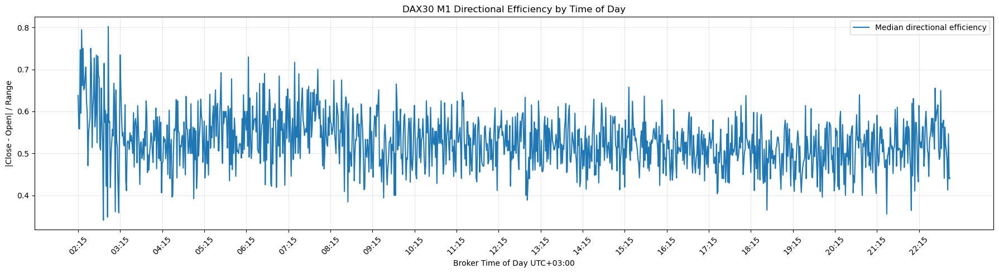

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,29859,0.617399,0.724782,0.924830,1.321030,0.285075,0.545455,0.454545,25.0,28.194782
Asia-London overlap,8760,1.340694,1.505068,1.807827,2.394562,0.660932,0.524002,0.475998,79.0,78.544749
London core,19718,0.971116,1.124999,1.332840,1.792624,0.471368,0.519066,0.480934,69.0,69.478852
London-NY overlap,10950,1.216027,1.380048,1.657919,2.219046,0.575287,0.505376,0.494624,87.0,85.866210
New York core,17450,0.656012,0.800942,0.953784,1.385222,0.307185,0.512713,0.487287,53.0,53.216905
Off-session,1597,0.609780,0.739446,0.942747,1.356800,0.300458,0.615385,0.384615,18.0,19.673763


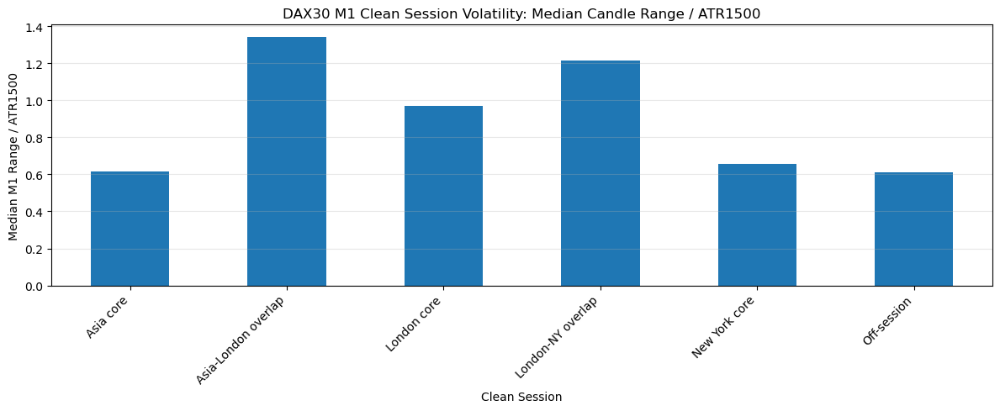

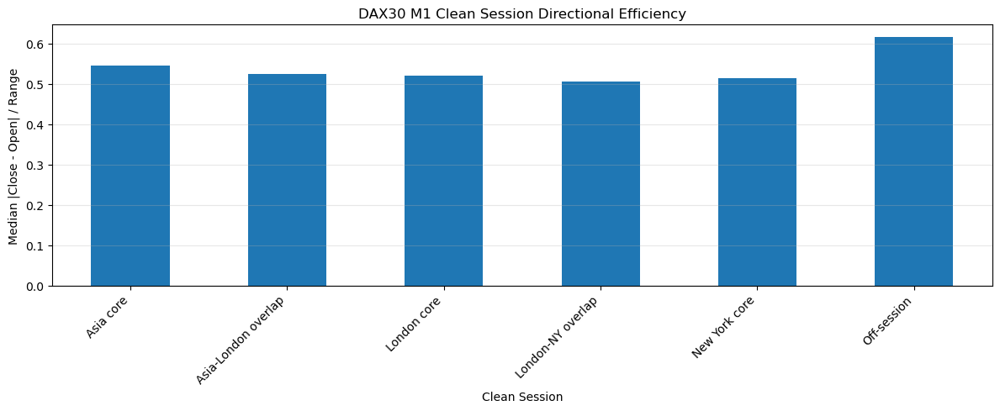

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,73,17.066623,18.984615,22.241026,30.613361,2.522280,2.780546,166.20,194.819178,6.75
Asia-London overlap,73,17.987792,19.359715,23.912533,27.190320,8.993896,9.679858,172.90,196.419178,2.00
London core,74,19.657693,21.979892,26.384157,31.815110,4.447269,4.983528,209.15,242.695946,4.50
London-NY overlap,73,17.180056,19.206368,23.097090,28.944386,6.872022,7.682547,196.80,206.865753,2.50
New York core,73,11.703315,14.954480,18.733738,25.166933,2.925829,3.740400,127.10,169.615068,4.00
Off-session,36,5.778077,6.488982,8.493025,9.747538,7.704102,8.703364,64.65,69.547222,0.75


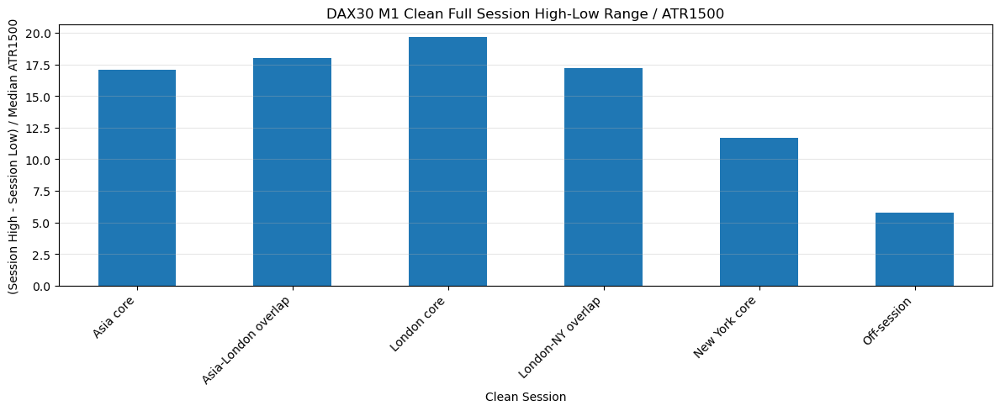

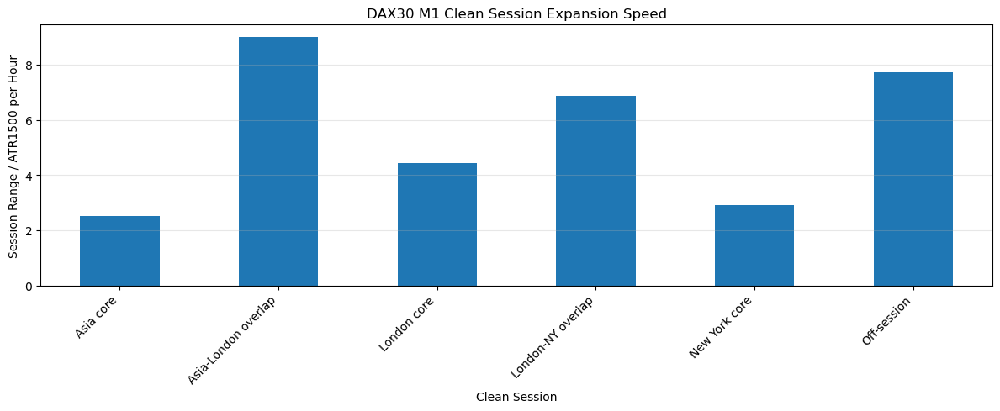

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


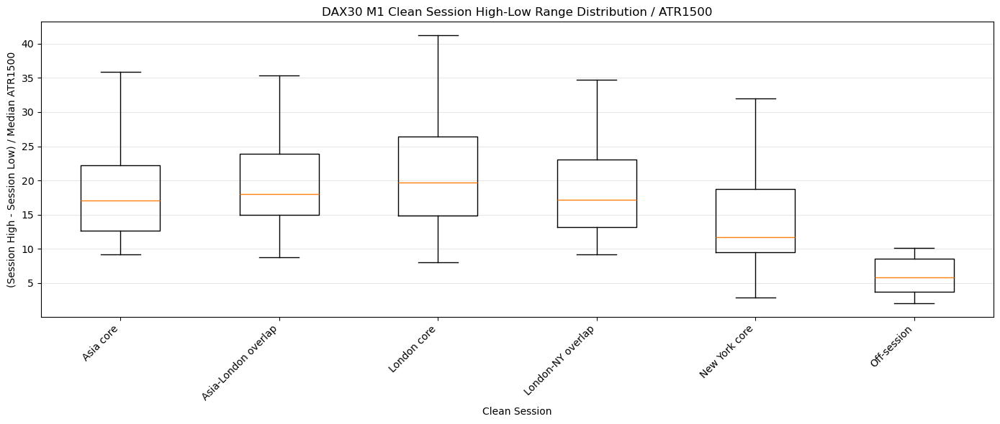

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
month_name,,,,,,,,,,,,,,,
January,87,196.80,213.532184,253.900,309.80,0.855982,1.036760,1.396530,0.339537,0.447415,0.552585,0.919736,0.913150,0.869851,0.763147
February,81,224.00,241.616049,316.700,371.70,0.935998,1.210533,1.466918,0.395455,0.517891,0.482109,0.977249,0.966301,1.038590,0.849461
March,86,329.90,392.363953,556.850,715.70,1.421675,1.797716,2.401622,0.553627,0.552917,0.447083,0.987758,1.008629,1.194870,1.222891
April,79,267.00,377.559494,384.500,695.28,1.428504,1.536378,2.097713,0.338730,0.432397,0.567603,0.861313,0.839424,0.928356,1.083714
May,79,234.50,278.856962,325.050,560.58,1.035874,1.273204,1.668669,0.500360,0.486926,0.513074,0.938261,0.873492,0.793938,0.939889
June,63,206.30,225.057143,279.150,326.36,0.951181,1.096587,1.322468,0.429511,0.494208,0.505792,0.936467,0.908854,0.841745,0.905508
July,88,237.50,248.082955,292.025,353.01,1.005741,1.270661,1.464245,0.449355,0.547018,0.452982,0.931881,0.942057,0.960009,0.938032
August,89,190.10,232.438202,262.100,352.32,0.959090,1.012932,1.583768,0.449784,0.505882,0.494118,0.877758,0.866376,0.834268,0.823813
September,86,221.45,251.940698,289.850,390.85,1.005897,1.197300,1.512121,0.435308,0.391660,0.608340,0.979695,0.974557,0.925464,0.936969


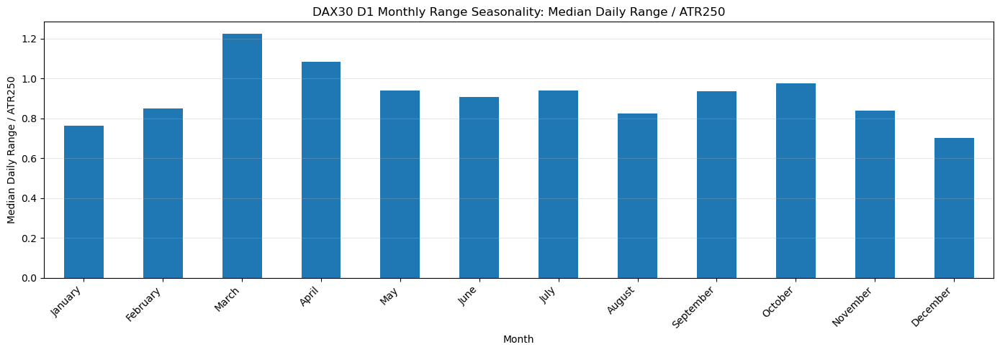

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:115: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


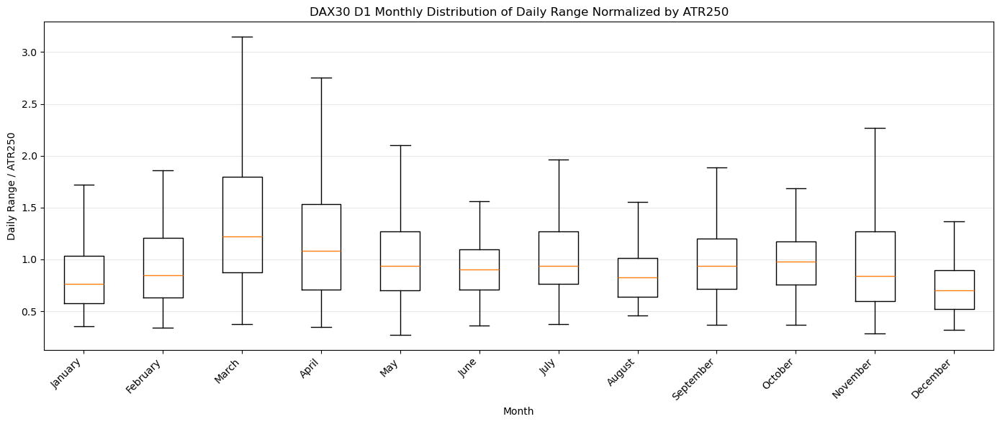

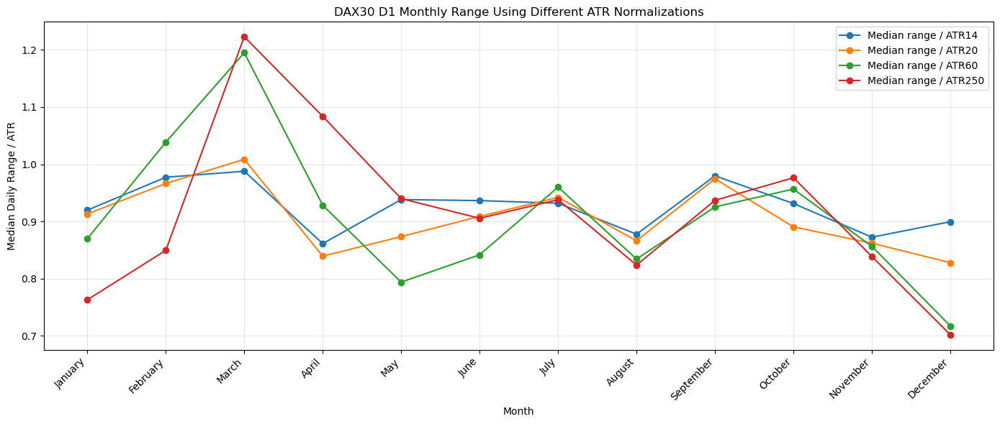

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
weekday,,,,,,,,,,,,,,,
Monday,195,203.00,256.944103,291.400,409.84,0.993427,1.148674,1.615687,0.323619,0.431212,0.568788,0.861313,0.850137,0.827814,0.823813
Tuesday,200,215.75,264.369500,318.975,460.46,1.028930,1.282079,1.648816,0.441709,0.474243,0.525757,0.906054,0.914907,0.891564,0.932962
Wednesday,198,230.10,262.750000,297.450,393.66,1.026557,1.189952,1.557931,0.424659,0.517146,0.482854,0.932476,0.913600,0.930098,0.906699
Thursday,199,233.50,270.921608,324.800,447.38,1.063220,1.340312,1.688209,0.438695,0.492110,0.507890,0.959236,0.971425,0.968176,0.932764
Friday,197,226.30,264.043147,303.000,429.78,1.034573,1.193924,1.597285,0.420835,0.491726,0.508274,0.938386,0.946402,0.918898,0.907235


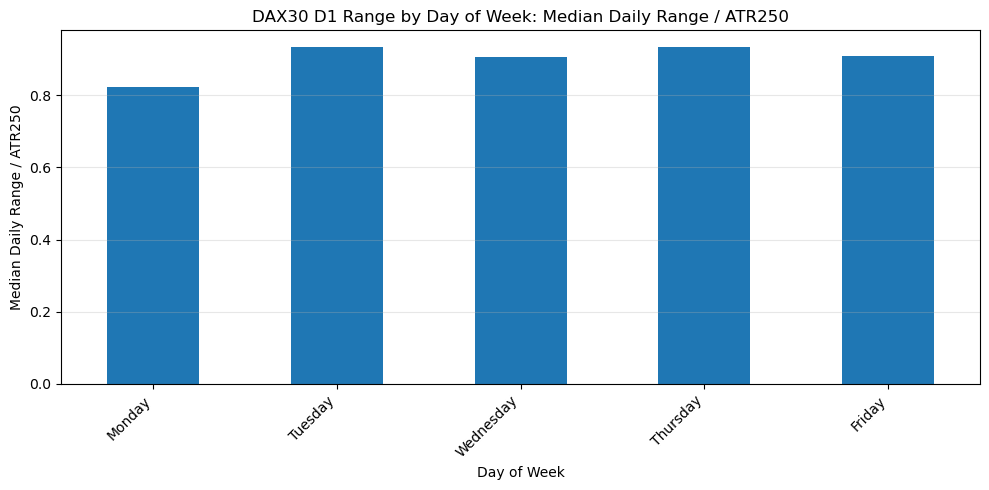

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:173: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


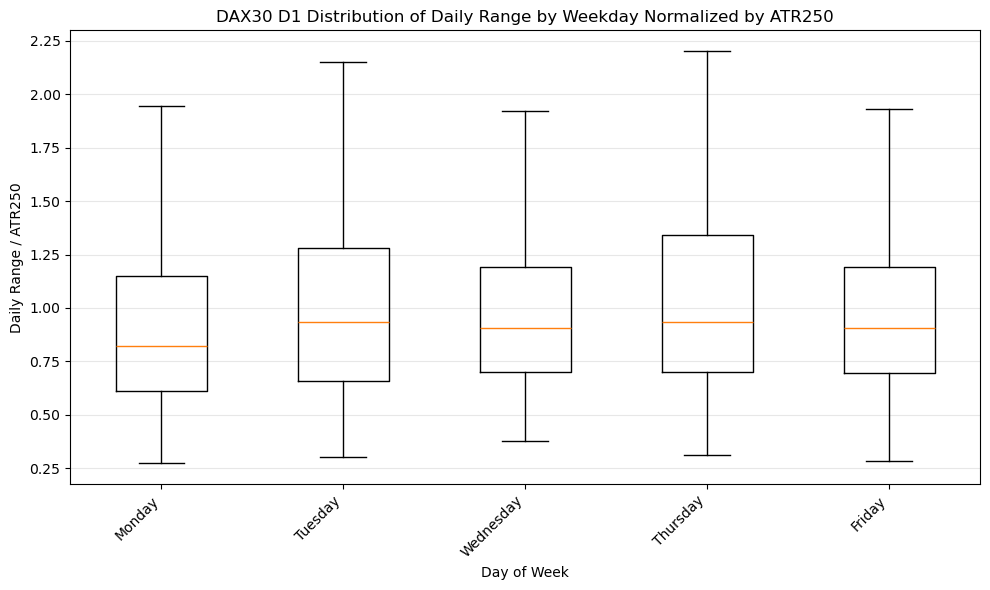

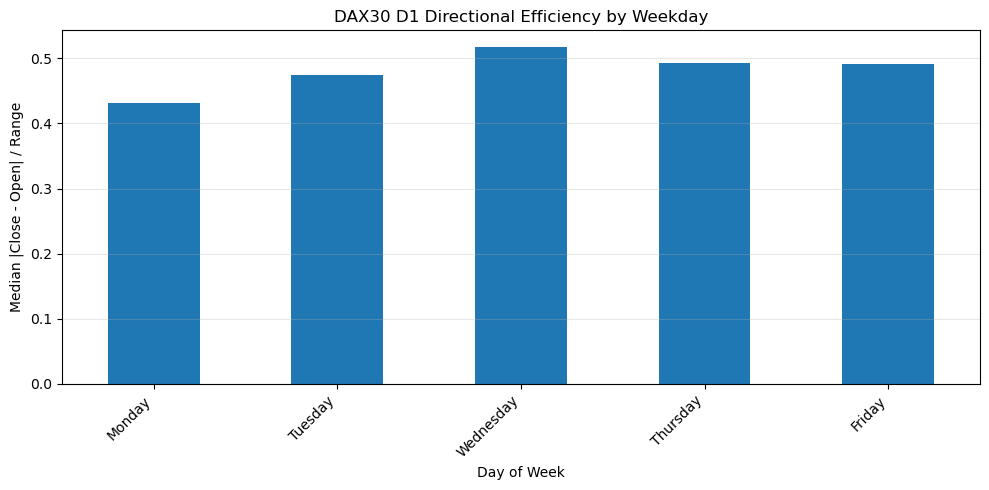

In [26]:
DAX30_m5 = analyze_asset_csv(r"mt5_data\DAX30_M5_max_bars.csv", timeframe="M5", asset_name="DAX30")
DAX30_m1 = analyze_asset_csv(r"mt5_data\DAX30_M1_max_bars.csv", timeframe="M1", asset_name="DAX30")
DAX30_d1 = analyze_asset_csv(r"mt5_data\DAX30_D1_max_bars.csv", timeframe="D1", asset_name="DAX30")

## XAUUSD

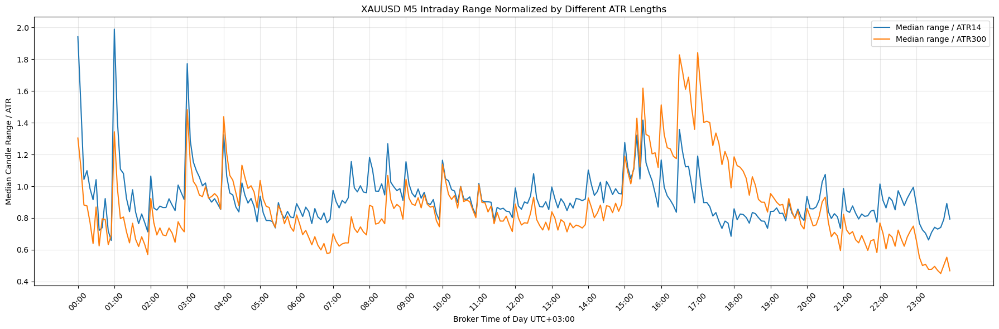

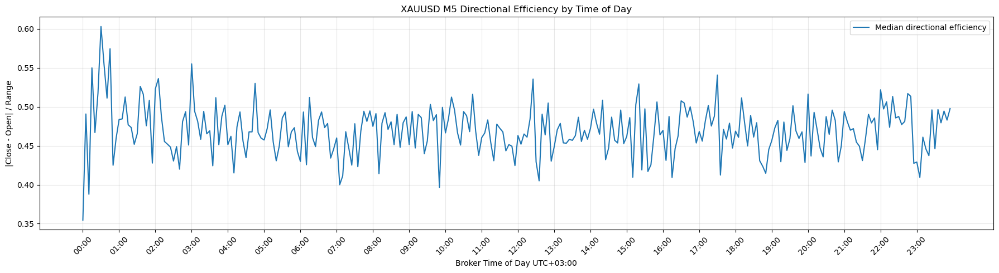

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,27468,0.840395,0.963819,1.168770,1.591676,0.365793,0.469136,0.530864,491.0,517.562910
Asia-London overlap,7848,0.876679,0.989158,1.180103,1.566301,0.388959,0.466667,0.533333,502.0,535.881881
London core,17611,0.917535,1.069642,1.286921,1.779877,0.400018,0.463442,0.536558,542.0,567.664074
London-NY overlap,9780,1.237780,1.415518,1.720583,2.321316,0.545206,0.471278,0.528722,667.0,703.816462
New York core,19146,0.702128,0.828535,0.986512,1.372606,0.307830,0.471523,0.528477,482.0,490.946725
Off-session,7848,0.739667,0.920165,1.085223,1.611818,0.323743,0.473400,0.526600,324.0,360.659786


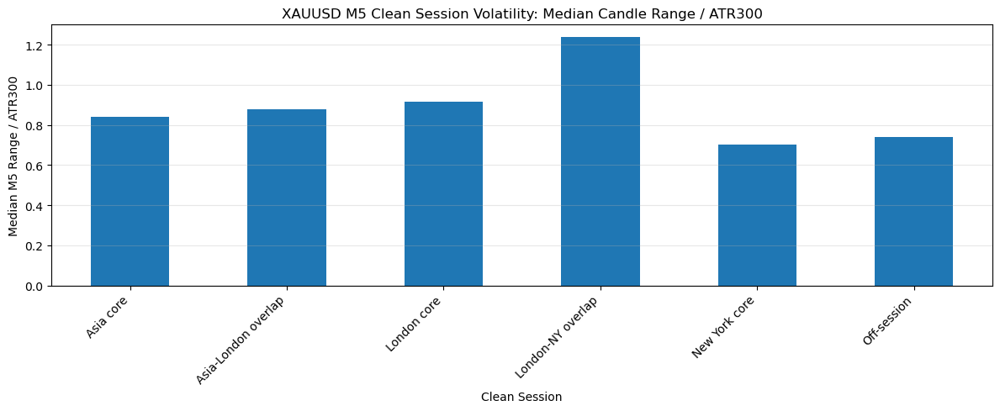

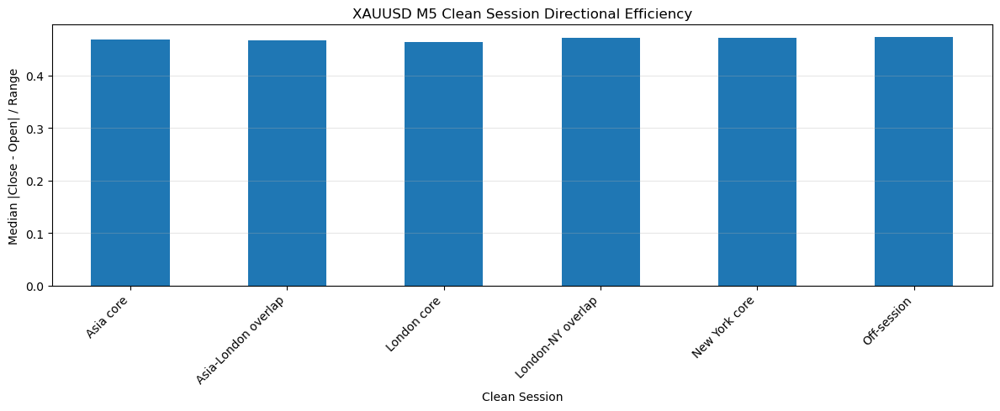

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,327,9.374489,10.231145,12.043280,15.421693,1.339213,1.461592,35.180,47.151957,7.0
Asia-London overlap,327,4.572496,5.178600,6.221111,8.307225,2.286248,2.589300,16.990,22.991896,2.0
London core,327,7.623739,8.586518,10.016203,13.339174,1.694419,1.918361,28.930,37.276300,4.5
London-NY overlap,326,7.473462,8.484309,9.713879,12.495791,2.989385,3.393724,30.390,39.587914,2.5
New York core,326,6.273552,7.515484,8.601796,13.022103,1.280190,1.537244,24.165,35.498497,5.0
Off-session,327,4.131424,5.073033,5.926795,9.278575,2.065712,2.536516,16.480,24.616269,2.0


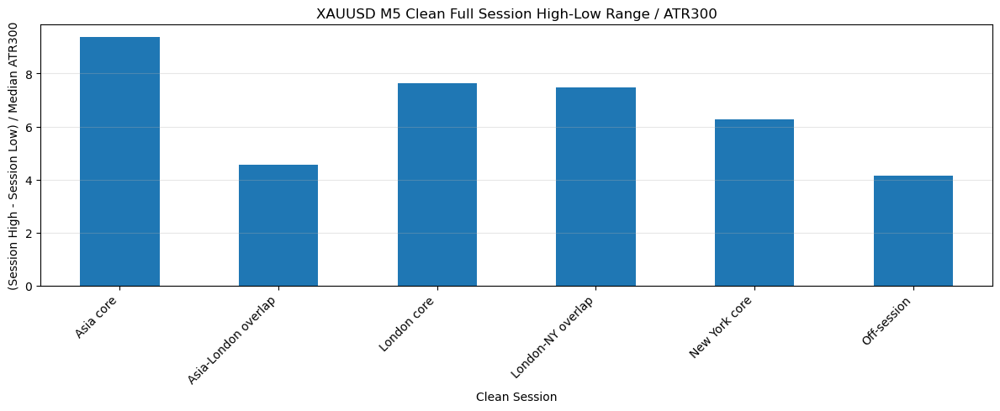

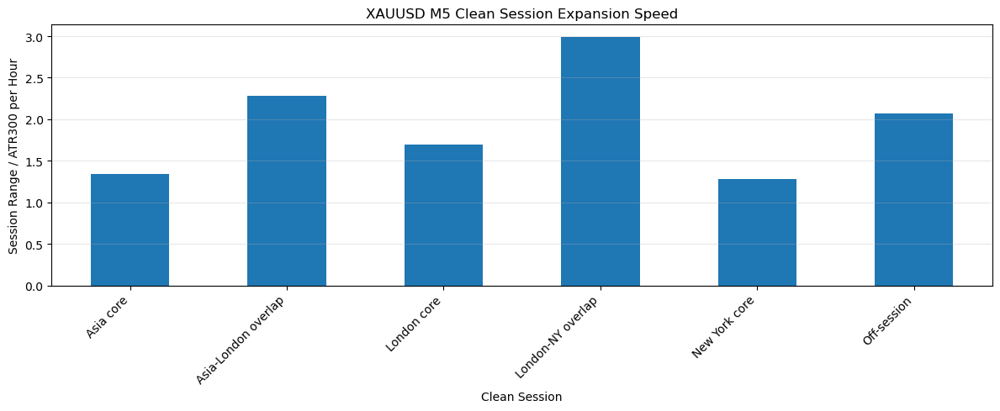

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


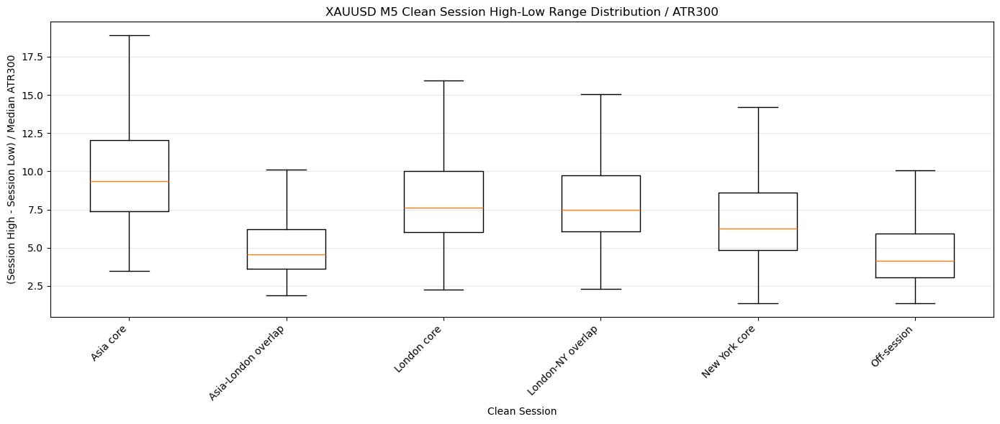

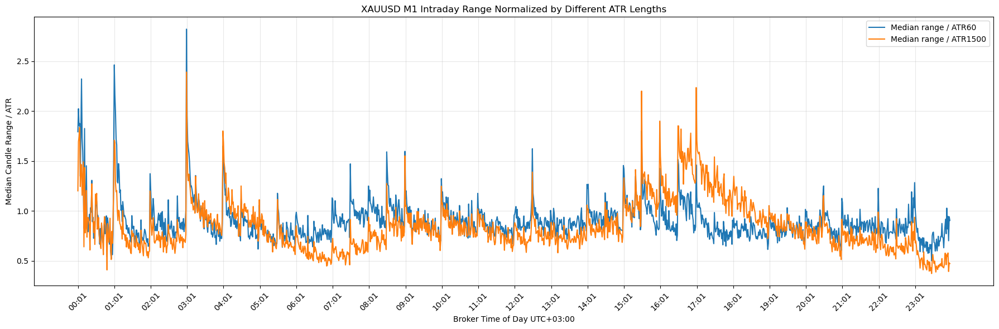

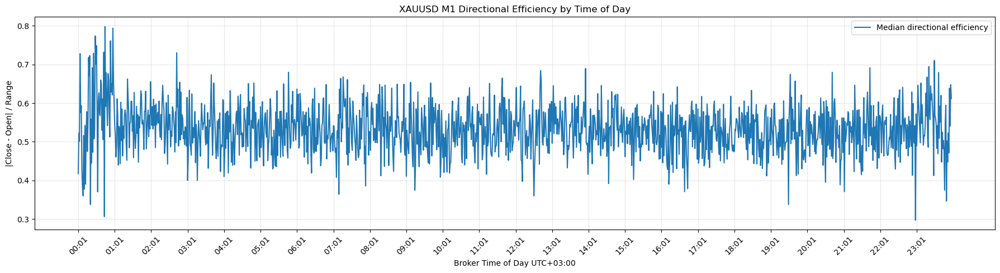

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,27084,0.781749,0.932688,1.148281,1.637173,0.375113,0.532731,0.467269,85.0,84.773667
Asia-London overlap,7800,0.825467,0.942637,1.148445,1.563233,0.397520,0.529068,0.470932,88.0,88.959872
London core,17315,0.890038,1.074007,1.297567,1.888820,0.433068,0.531915,0.468085,92.0,93.633786
London-NY overlap,9600,1.205304,1.393768,1.691033,2.353649,0.580945,0.521406,0.478594,117.0,116.894792
New York core,19063,0.708117,0.851077,1.031351,1.473342,0.341827,0.528926,0.471074,90.0,88.656927
Off-session,7638,0.739669,0.963124,1.159792,1.814994,0.365414,0.552433,0.447567,63.0,67.700183


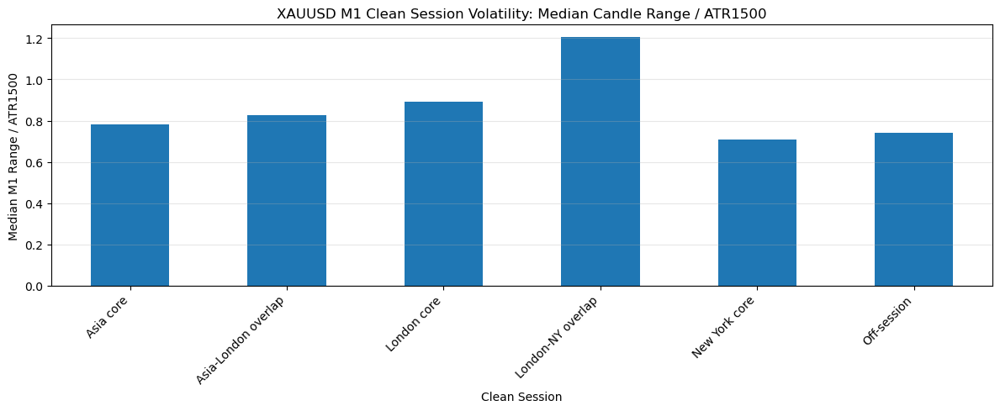

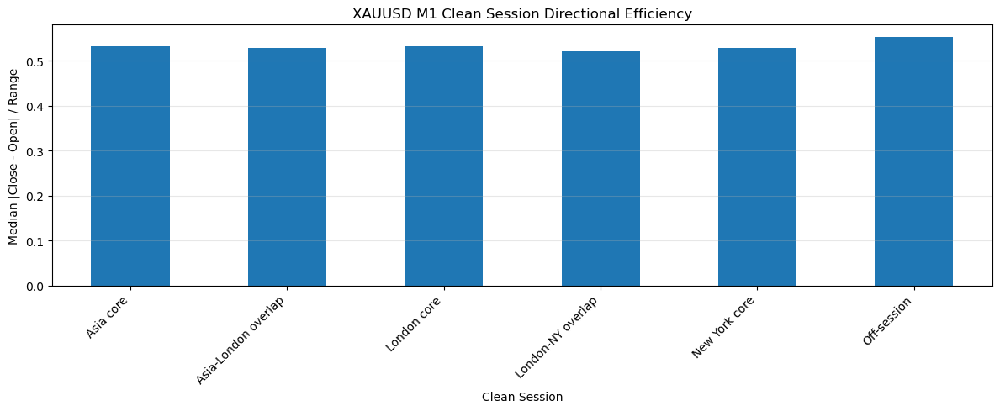

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,65,22.400277,24.809154,29.306004,38.854555,3.200040,3.556591,60.16,71.916615,7.000000
Asia-London overlap,65,9.849968,10.909755,13.196044,15.957543,4.924984,5.454878,27.09,31.563231,2.000000
London core,65,17.150218,21.158943,24.323332,33.660130,3.850451,4.825000,46.66,61.638154,4.500000
London-NY overlap,64,17.723055,18.742096,22.013702,26.551182,7.089222,7.496838,50.53,55.899531,2.500000
New York core,64,15.379645,20.618664,22.601922,39.155613,3.091462,4.156344,43.20,62.289375,4.983333
Off-session,64,10.020485,12.510942,13.875890,25.387699,5.040517,6.287324,27.55,37.688594,1.983333


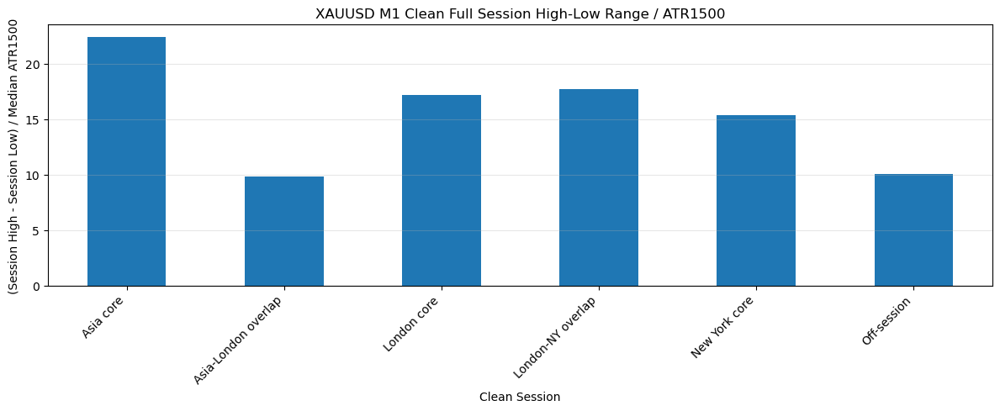

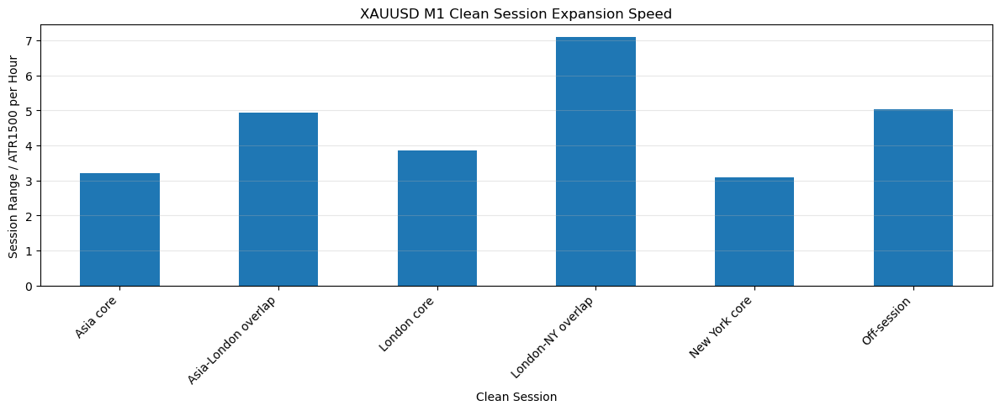

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


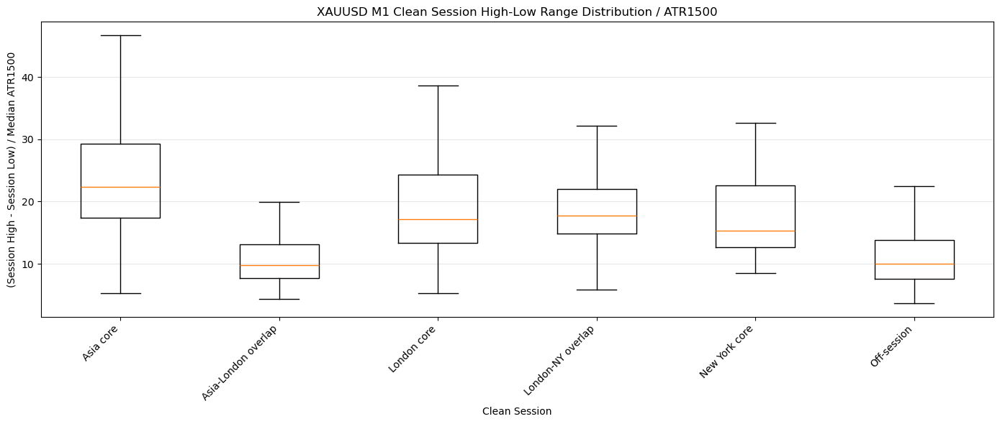

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
month_name,,,,,,,,,,,,,,,
January,320,19.175,29.082062,27.5550,39.319,1.033105,1.189309,1.523894,0.350205,0.448269,0.551731,0.947544,0.937358,0.896615,0.879248
February,303,19.440,32.440594,30.2800,54.750,1.121376,1.278684,1.842463,0.395390,0.427566,0.572434,0.930879,0.933010,0.969177,0.926604
March,327,21.930,36.318349,37.8100,63.054,1.256033,1.500060,2.126736,0.437222,0.467405,0.532595,0.923018,0.921084,0.971570,1.023501
April,311,21.500,33.132669,35.9750,81.800,1.184979,1.393714,1.903421,0.413077,0.459511,0.540489,0.896845,0.897321,0.873865,0.977843
May,326,21.110,28.191380,32.5225,52.540,1.037758,1.261673,1.688267,0.353485,0.403755,0.596245,0.911980,0.901338,0.862334,0.930627
June,292,18.750,23.190788,28.1650,42.648,0.995339,1.159654,1.635752,0.351232,0.443353,0.556647,0.897220,0.900445,0.834501,0.862840
July,308,19.060,22.102857,27.4400,39.489,0.975809,1.224671,1.552248,0.341004,0.425033,0.574967,0.960672,0.948428,0.861024,0.883792
August,308,18.340,22.715747,27.6300,40.852,1.003854,1.176005,1.725900,0.340564,0.415768,0.584232,0.877644,0.876741,0.859299,0.833154
September,293,18.910,23.051092,28.5900,43.576,0.978700,1.176063,1.521421,0.364390,0.437805,0.562195,0.974195,0.952765,0.943006,0.922985


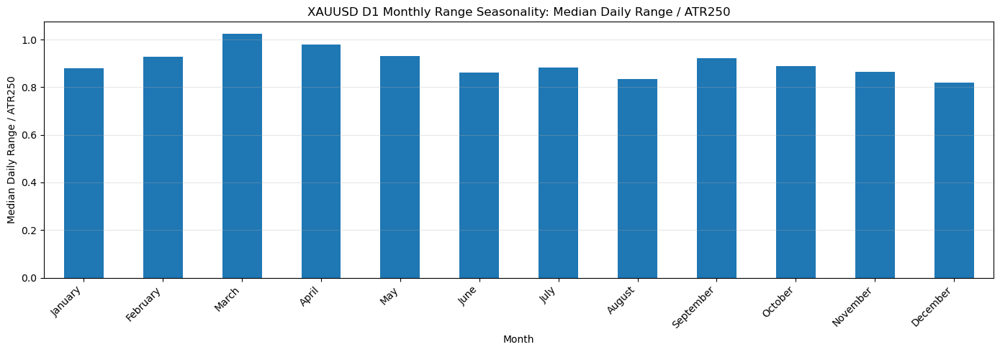

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:115: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


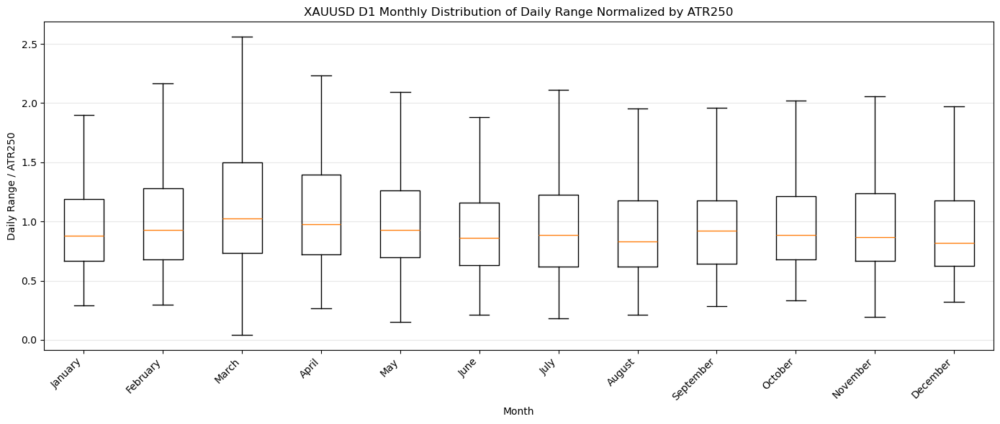

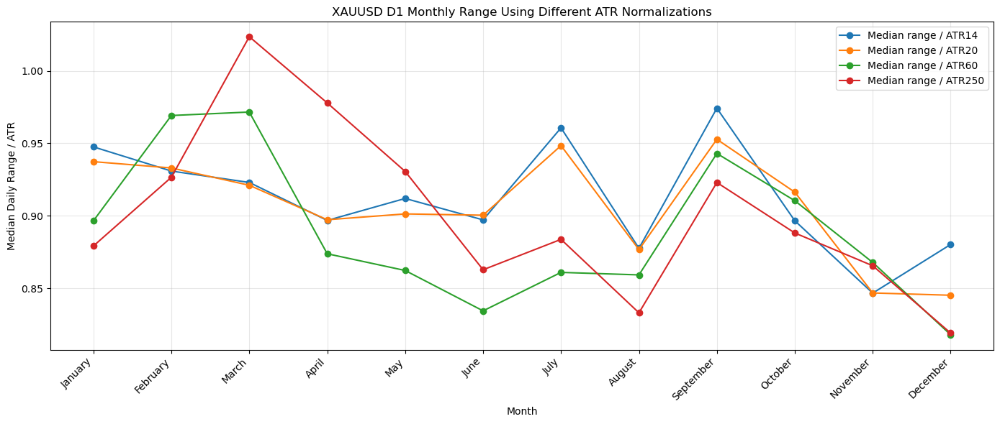

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
weekday,,,,,,,,,,,,,,,
Monday,741,17.180,26.600850,27.0200,48.850,0.999855,1.153803,1.718104,0.324439,0.425446,0.574554,0.831876,0.819277,0.817245,0.822900
Tuesday,744,19.335,26.892231,29.1200,46.127,1.030124,1.232715,1.598601,0.383040,0.445051,0.554949,0.905949,0.891995,0.878880,0.884226
Wednesday,742,19.865,26.529838,29.1950,46.311,1.044410,1.251566,1.715893,0.376203,0.446619,0.553381,0.916947,0.907037,0.882657,0.895891
Thursday,742,20.270,27.737884,30.9150,46.908,1.075230,1.271980,1.755509,0.384261,0.440512,0.559488,0.946945,0.932144,0.916416,0.929936
Friday,726,20.725,28.678223,31.4625,50.435,1.108491,1.318276,1.803726,0.409091,0.448859,0.551141,0.961869,0.962045,0.936240,0.957640


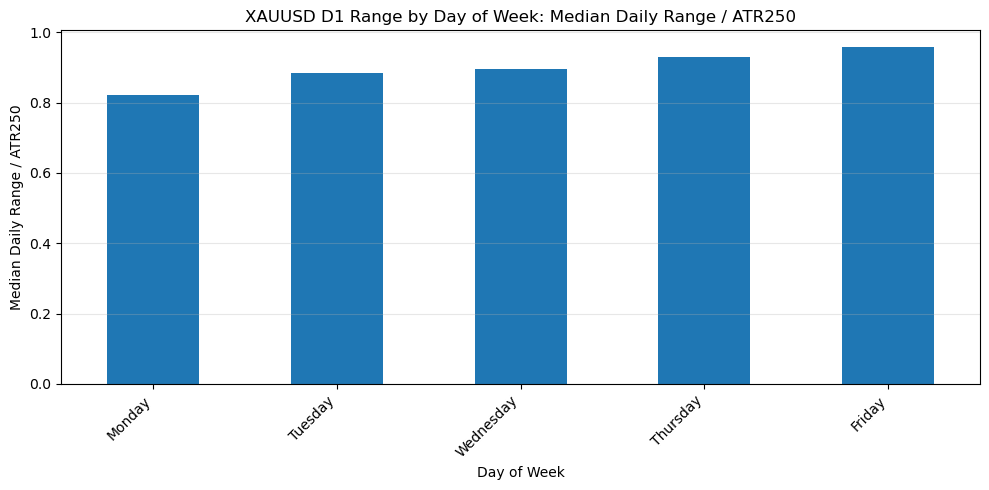

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:173: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


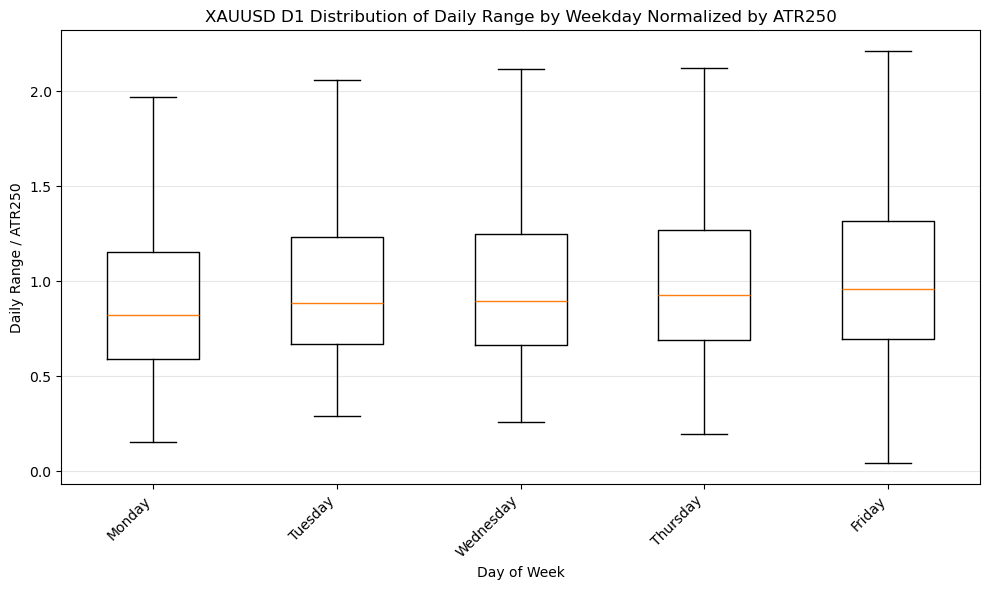

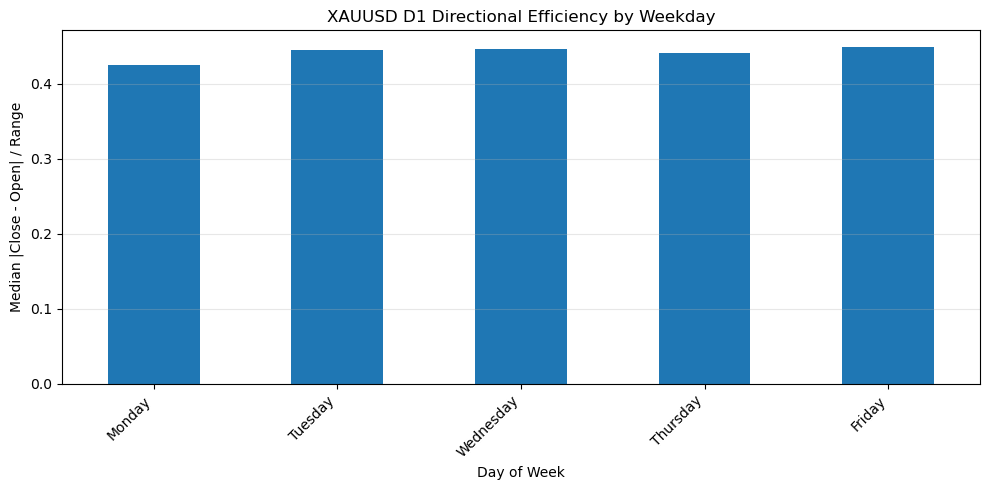

In [27]:
XAUUSD_m5 = analyze_asset_csv(r"mt5_data\XAUUSDzero_M5_max_bars.csv", timeframe="M5", asset_name="XAUUSD")
XAUUSD_m1 = analyze_asset_csv(r"mt5_data\XAUUSDzero_M1_max_bars.csv", timeframe="M1", asset_name="XAUUSD")
XAUUSD_d1 = analyze_asset_csv(r"mt5_data\XAUUSDzero_D1_max_bars.csv", timeframe="D1", asset_name="XAUUSD")

## AUDUSD

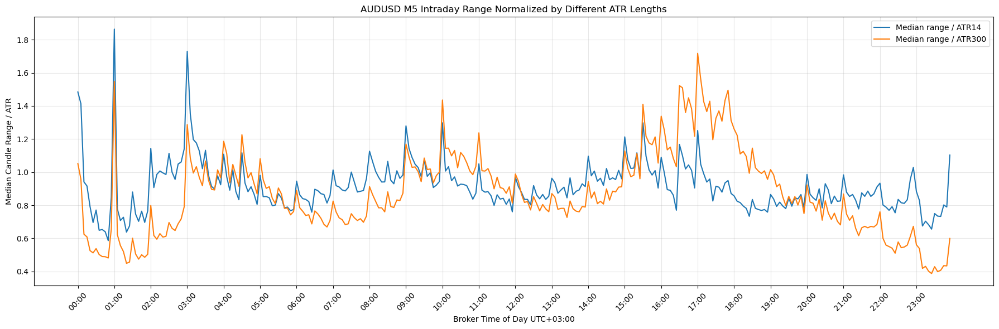

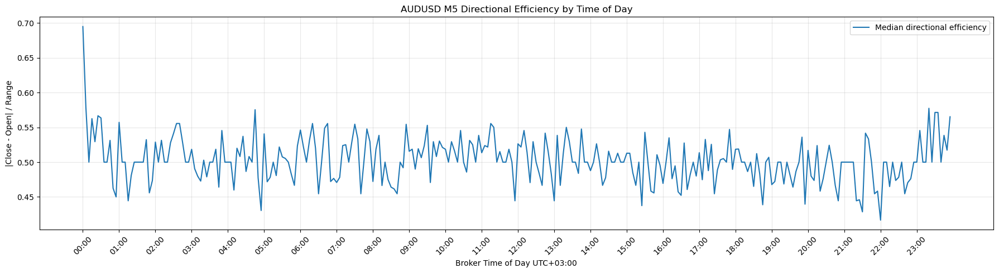

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,26208,0.877889,0.993270,1.197348,1.600416,0.408536,0.500000,0.500000,112.0,126.672886
Asia-London overlap,7511,1.022913,1.131486,1.351262,1.761315,0.490820,0.515152,0.484848,132.0,147.919451
London core,16895,0.912625,1.058614,1.232065,1.683076,0.424601,0.500000,0.500000,123.0,144.872566
London-NY overlap,9360,1.250124,1.415290,1.704678,2.251207,0.579286,0.500000,0.500000,188.0,205.460897
New York core,22140,0.664027,0.803000,0.960629,1.386221,0.292860,0.500000,0.500000,90.0,105.357182
Off-session,7488,0.606658,0.774071,0.918586,1.367352,0.286927,0.500000,0.500000,68.0,85.830796


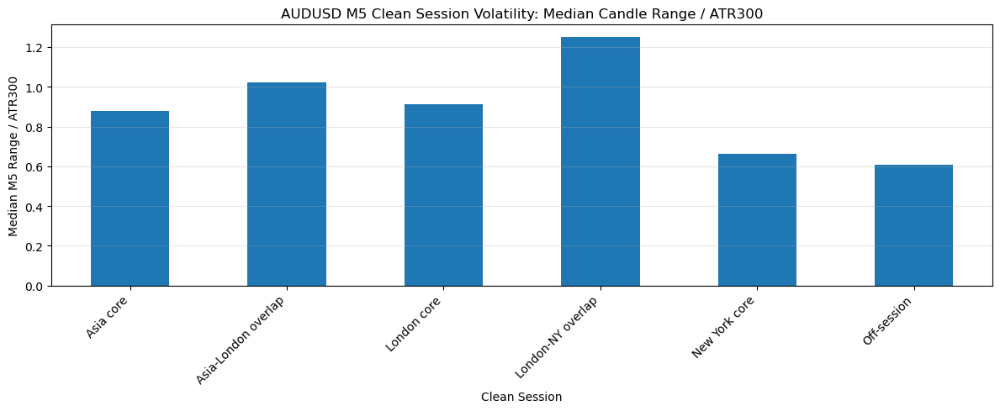

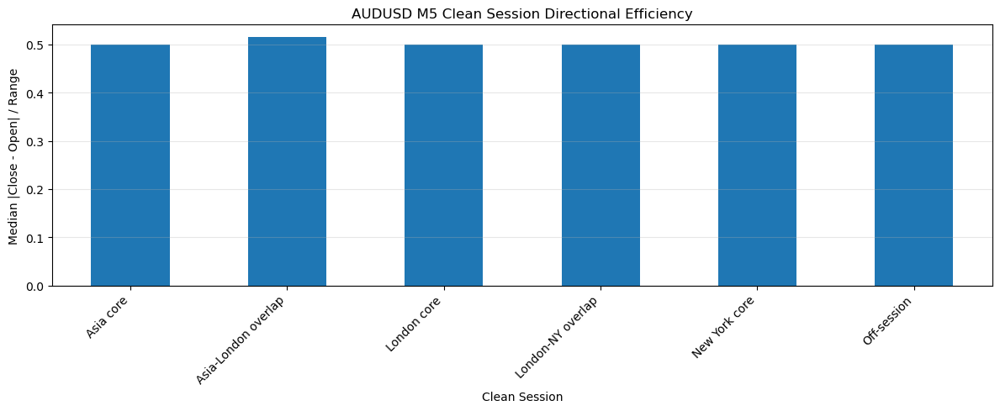

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,312,9.745908,10.335745,11.900075,15.347422,1.392273,1.476535,0.002665,0.003183,7.0
Asia-London overlap,313,5.509361,6.021111,7.292090,8.957976,2.754680,3.010830,0.001560,0.001860,2.0
London core,313,7.762253,8.705386,10.384930,12.932198,1.724945,1.935230,0.002280,0.002668,4.5
London-NY overlap,312,7.520703,8.511676,10.004927,12.941456,3.008281,3.404671,0.002280,0.002703,2.5
New York core,313,13.527549,14.666548,18.764187,24.169275,2.268041,2.482155,0.003800,0.004536,6.0
Off-session,312,3.819376,4.483316,5.254039,7.304435,1.909688,2.241658,0.001060,0.001378,2.0


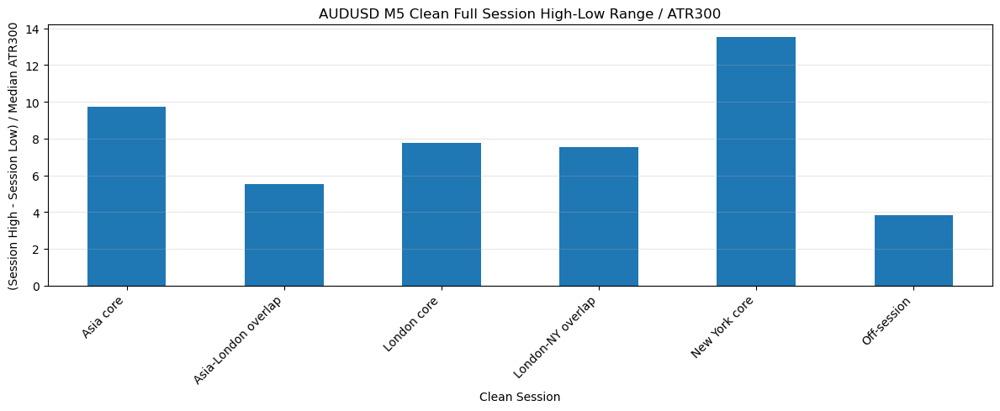

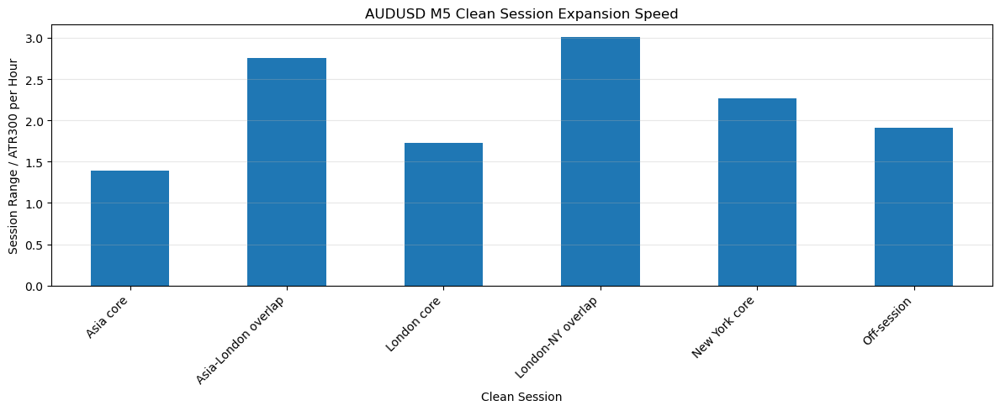

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


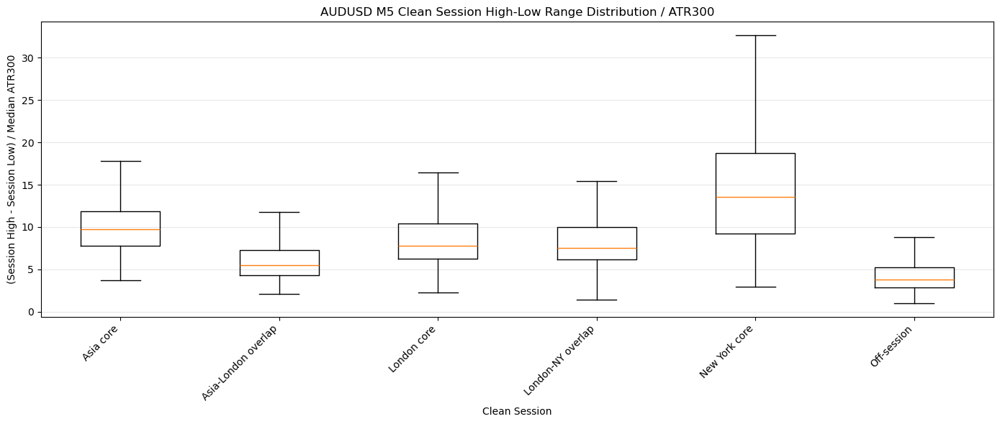

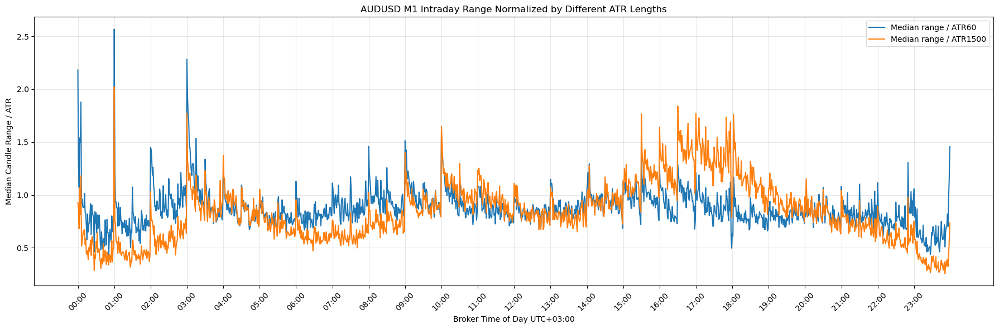

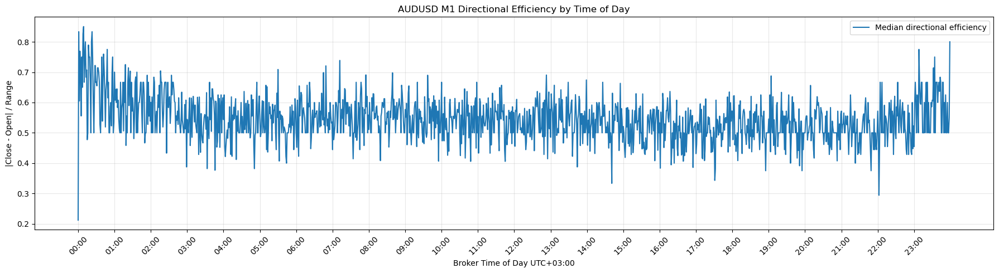

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,26033,0.768729,0.891116,1.100675,1.537800,0.376778,0.545455,0.454545,29.0,31.611954
Asia-London overlap,7438,1.004484,1.119386,1.368149,1.818435,0.505622,0.541667,0.458333,39.0,41.013982
London core,16740,0.953122,1.128934,1.346872,1.897304,0.464436,0.533333,0.466667,39.0,42.225627
London-NY overlap,9280,1.275040,1.478365,1.775218,2.422863,0.606615,0.500000,0.500000,56.0,57.386530
New York core,21141,0.667854,0.830312,1.014199,1.510974,0.305904,0.538462,0.461538,28.0,30.532283
Off-session,7357,0.528417,0.719692,0.872499,1.408434,0.263481,0.583333,0.416667,16.0,21.579176


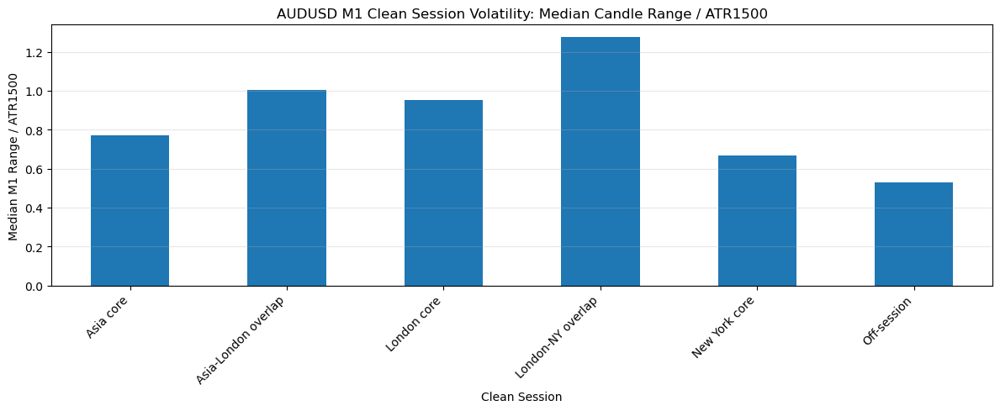

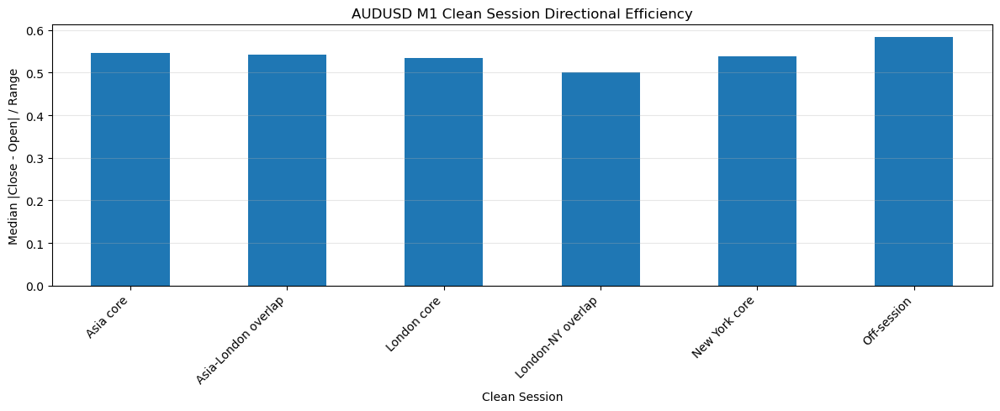

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,62,21.332167,22.956596,27.947131,35.600297,3.047452,3.279707,0.003085,0.003513,7.000000
Asia-London overlap,62,12.602210,14.517973,18.312839,21.066650,6.301105,7.260087,0.002070,0.002301,2.000000
London core,62,18.717152,21.369619,25.103523,30.812099,4.159367,4.748804,0.002890,0.003347,4.500000
London-NY overlap,62,17.863798,19.683890,24.258466,29.910434,7.145519,7.898732,0.002825,0.003119,2.500000
New York core,63,35.625074,35.476481,45.542386,58.034050,5.970683,6.188811,0.004930,0.005464,5.916667
Off-session,62,8.396649,11.031919,13.378194,18.534633,4.215849,5.524086,0.001180,0.001723,2.000000


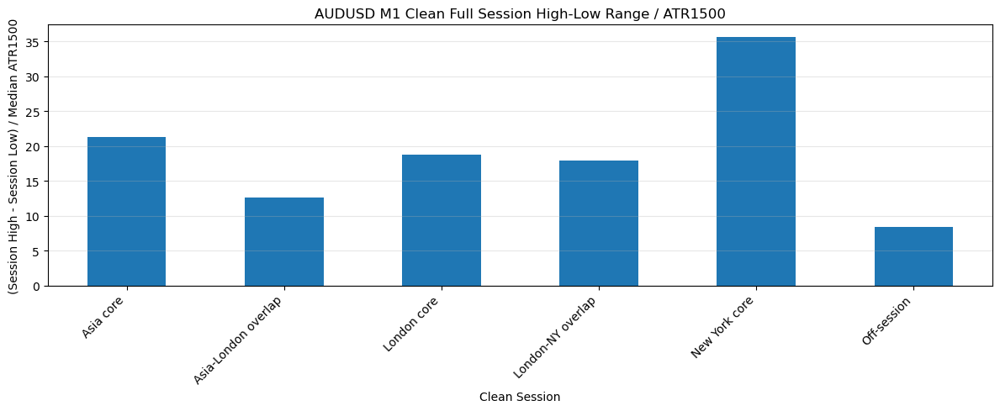

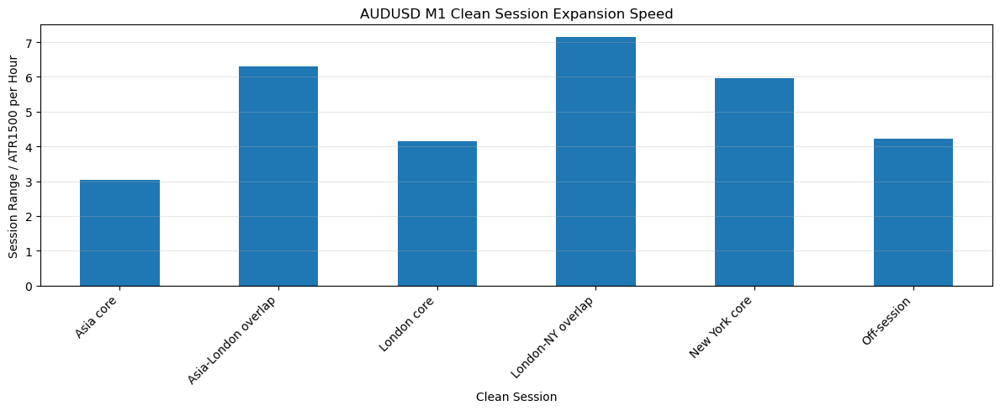

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


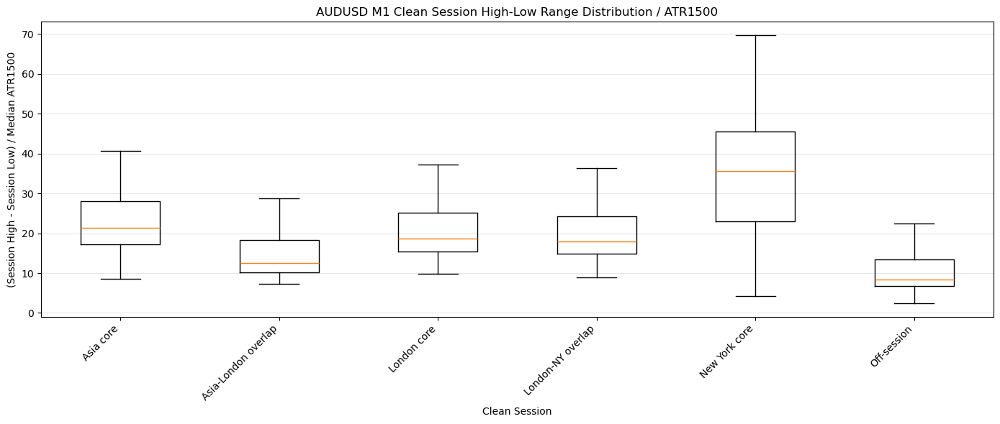

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
month_name,,,,,,,,,,,,,,,
January,692,0.007000,0.008056,0.010125,0.01370,1.018820,1.201666,1.515159,0.399228,0.452055,0.547945,1.007644,1.014722,0.971848,0.921315
February,646,0.006800,0.007719,0.009200,0.01235,0.978212,1.147171,1.475579,0.361030,0.439626,0.560374,0.909617,0.889520,0.942338,0.911982
March,707,0.007000,0.008167,0.009700,0.01360,1.064265,1.221274,1.643099,0.404163,0.482234,0.517766,0.918707,0.922156,0.915033,0.885493
April,701,0.007000,0.007674,0.009200,0.01210,0.992485,1.179626,1.528750,0.386972,0.466851,0.533149,0.937746,0.918367,0.896921,0.892737
May,724,0.006910,0.008061,0.009800,0.01290,1.026480,1.203291,1.646602,0.393685,0.451117,0.548883,0.936790,0.945192,0.947783,0.932293
June,685,0.007100,0.008343,0.010400,0.01476,1.035952,1.245258,1.633984,0.393565,0.445946,0.554054,0.943820,0.934657,0.933449,0.932966
July,708,0.006915,0.007764,0.009500,0.01223,0.990790,1.171618,1.469177,0.403898,0.467222,0.532778,0.931909,0.929440,0.894888,0.908705
August,709,0.006800,0.007859,0.009500,0.01240,0.998678,1.188607,1.542316,0.359156,0.431818,0.568182,0.904977,0.895713,0.889163,0.888163
September,686,0.007000,0.008039,0.009600,0.01310,0.995824,1.188293,1.559955,0.374878,0.446809,0.553191,0.954093,0.958060,0.918146,0.919713


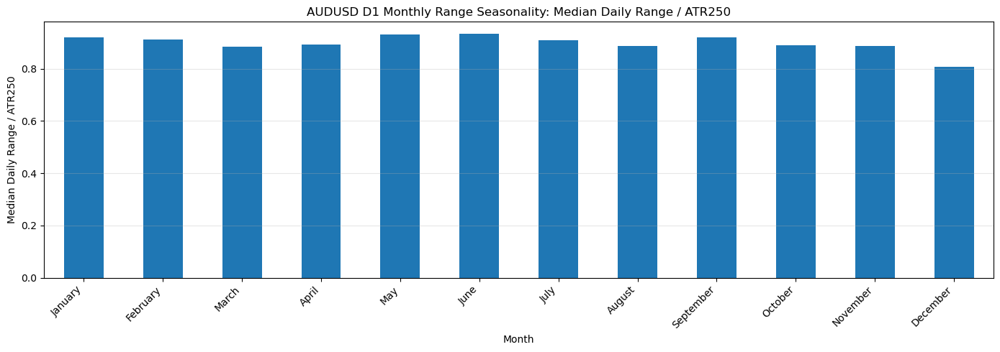

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:115: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


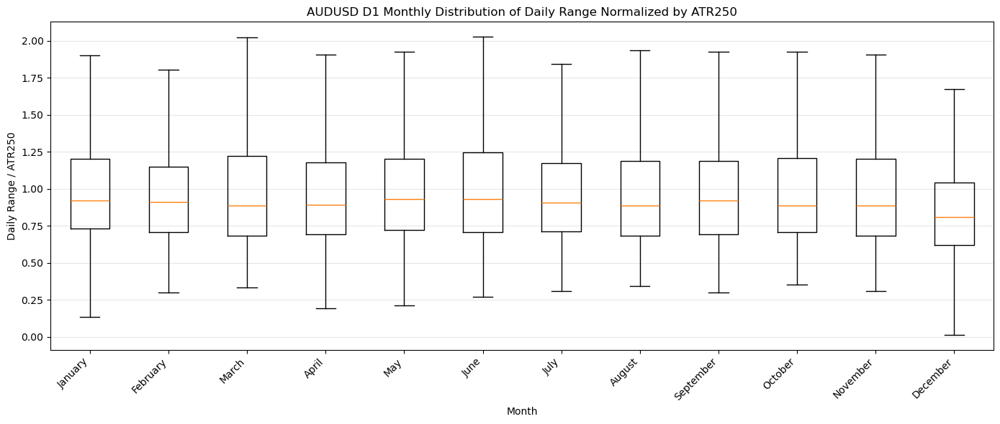

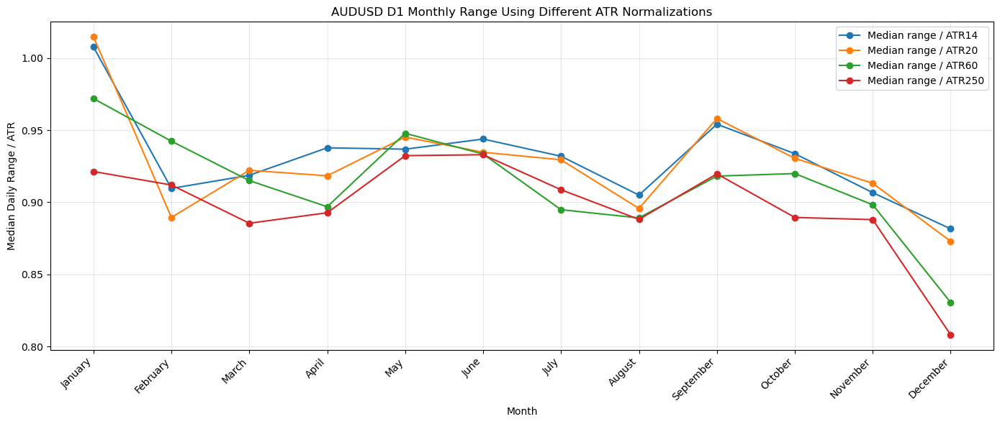

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
weekday,,,,,,,,,,,,,,,
Monday,1669,0.0061,0.007211,0.0085,0.012200,0.904951,1.068148,1.434442,0.327697,0.439252,0.560748,0.834437,0.827740,0.818302,0.802384
Tuesday,1671,0.0070,0.008135,0.0097,0.013700,1.015032,1.189988,1.542800,0.409809,0.462963,0.537037,0.952000,0.942623,0.932498,0.916638
Wednesday,1670,0.0071,0.008379,0.0100,0.013800,1.051373,1.251077,1.637027,0.397151,0.450000,0.550000,0.972501,0.978505,0.960548,0.941919
Thursday,1668,0.0072,0.008351,0.0101,0.013700,1.049529,1.236213,1.574506,0.400952,0.447133,0.552867,0.972468,0.964664,0.947348,0.936882
Friday,1667,0.0069,0.007882,0.0095,0.012782,0.993642,1.168337,1.520844,0.368973,0.452055,0.547945,0.919966,0.926916,0.910105,0.895091


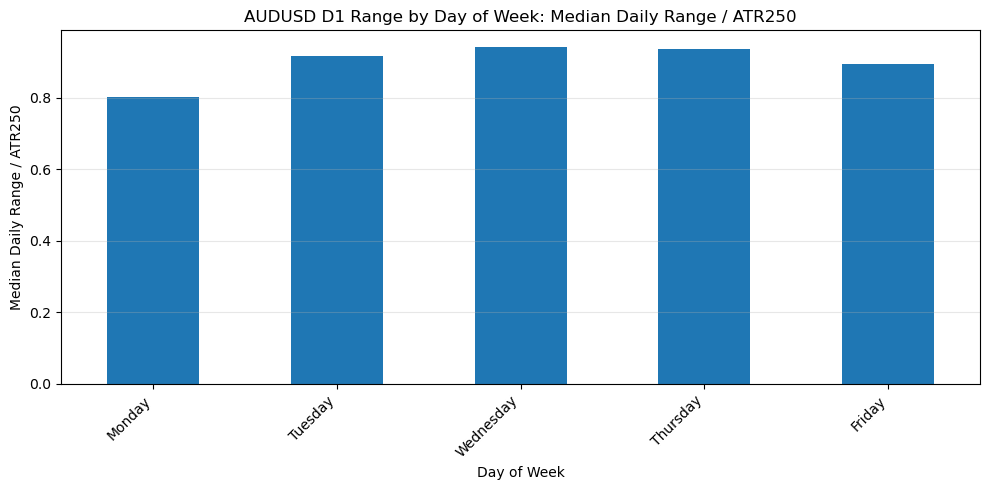

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:173: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


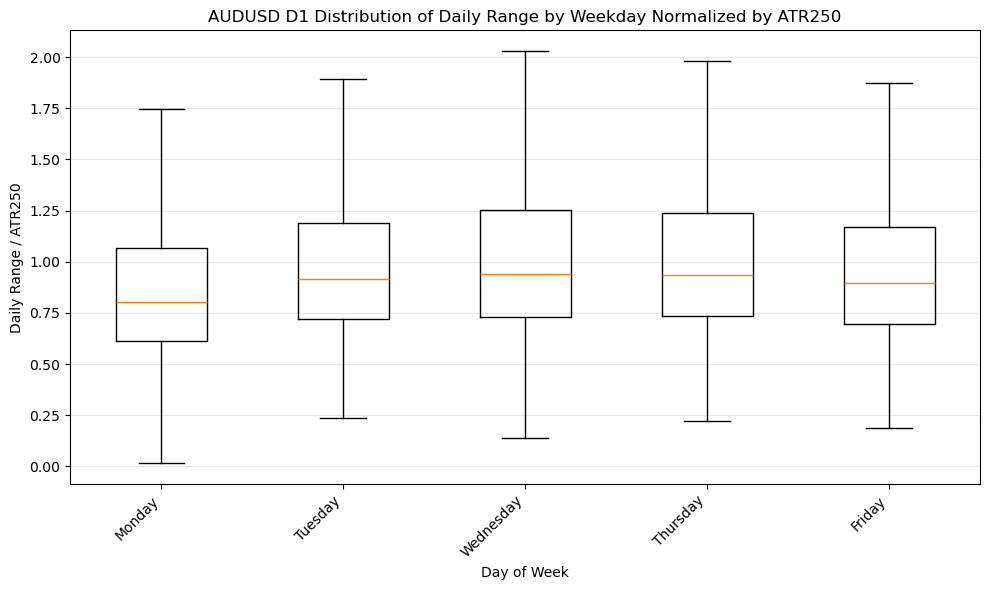

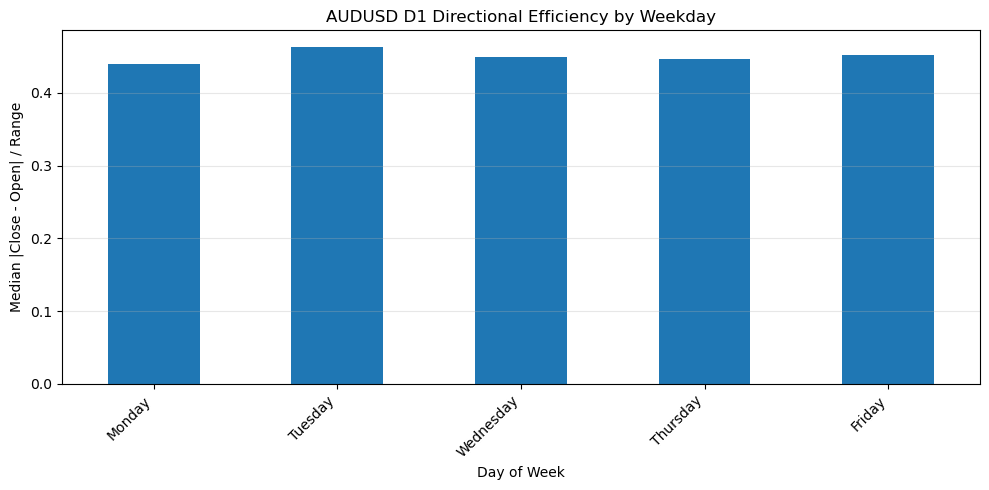

In [28]:
AUDUSD_m5 = analyze_asset_csv(r"mt5_data\AUDUSDzero_M5_max_bars.csv", timeframe="M5", asset_name="AUDUSD")
AUDUSD_m1 = analyze_asset_csv(r"mt5_data\AUDUSDzero_M1_max_bars.csv", timeframe="M1", asset_name="AUDUSD")
AUDUSD_d1 = analyze_asset_csv(r"mt5_data\AUDUSDzero_D1_max_bars.csv", timeframe="D1", asset_name="AUDUSD")

## BRENT

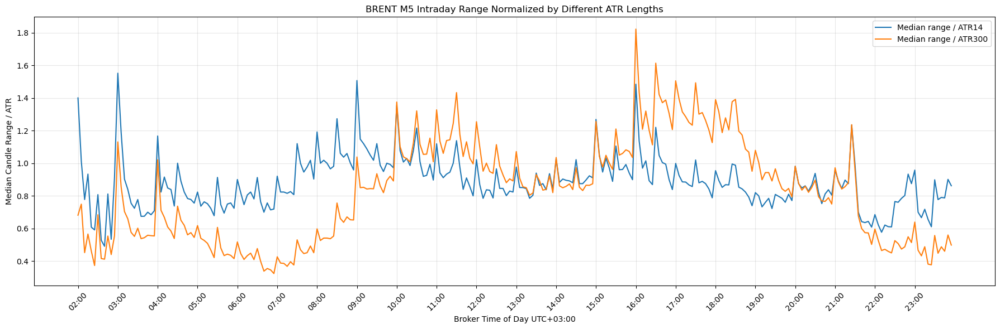

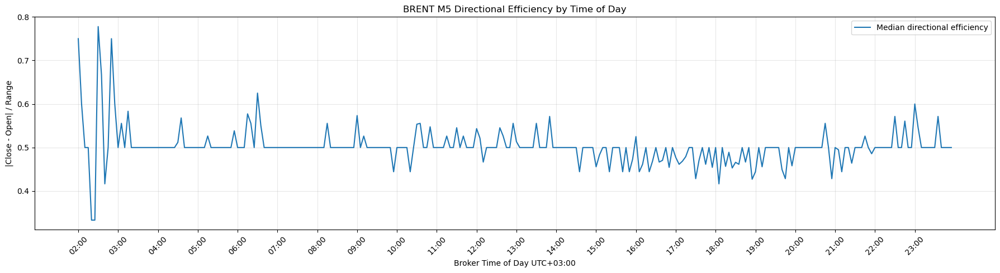

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,30700,0.570374,0.686827,0.853312,1.219512,0.269906,0.500000,0.500000,25.0,41.009414
Asia-London overlap,8856,1.121874,1.246993,1.521743,1.991911,0.533167,0.500000,0.500000,58.0,77.281956
London core,19913,0.980909,1.138193,1.354547,1.855080,0.455005,0.500000,0.500000,55.0,78.635012
London-NY overlap,11040,1.277955,1.460174,1.731292,2.349442,0.566349,0.470588,0.529412,99.0,121.084149
New York core,18804,0.733855,0.883665,1.067194,1.522843,0.324939,0.500000,0.500000,48.0,68.291746
Off-session,179,0.535714,0.563880,0.684932,0.940973,0.274474,0.500000,0.500000,13.0,14.949721


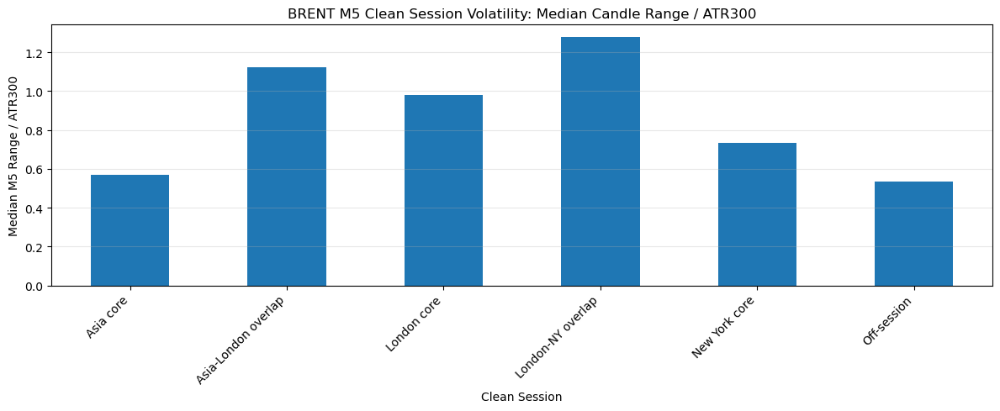

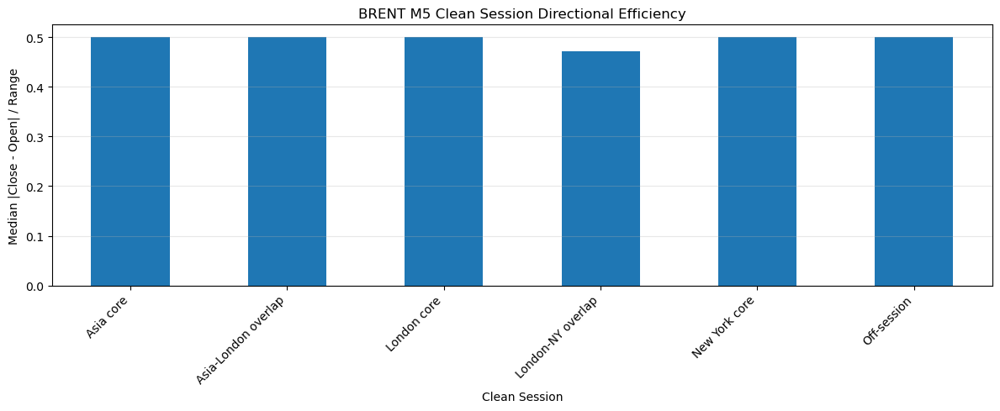

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,369,6.911884,7.533812,8.614025,11.176420,0.987412,1.079885,0.59,1.045285,7.0
Asia-London overlap,369,6.214933,6.749173,7.698113,10.137332,3.107467,3.374587,0.56,0.864607,2.0
London core,369,8.496423,9.805719,11.223278,14.825789,1.888094,2.180716,0.87,1.325095,4.5
London-NY overlap,368,7.641966,8.617640,10.490115,13.146823,3.056786,3.447056,0.81,1.150000,2.5
New York core,368,6.399203,7.382903,8.736150,11.715297,1.497281,1.759212,0.64,1.126603,4.0
Off-session,15,2.253219,2.344175,2.681259,3.938553,2.253219,2.344175,0.16,0.169333,1.0


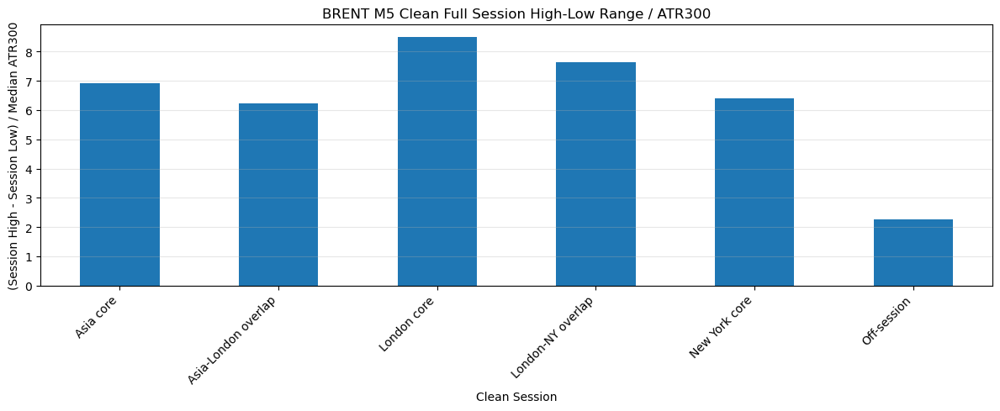

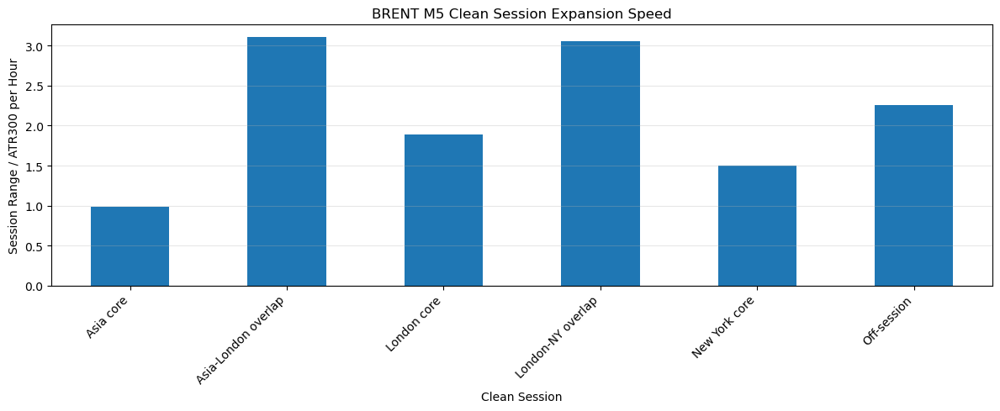

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


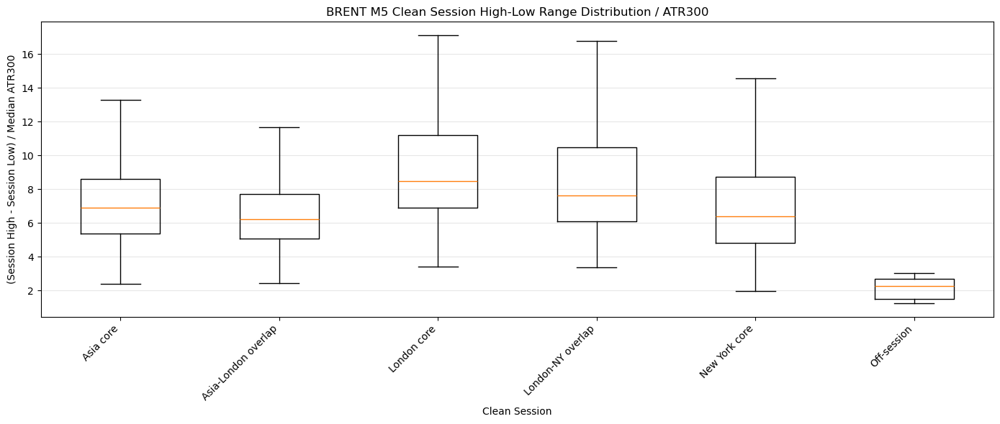

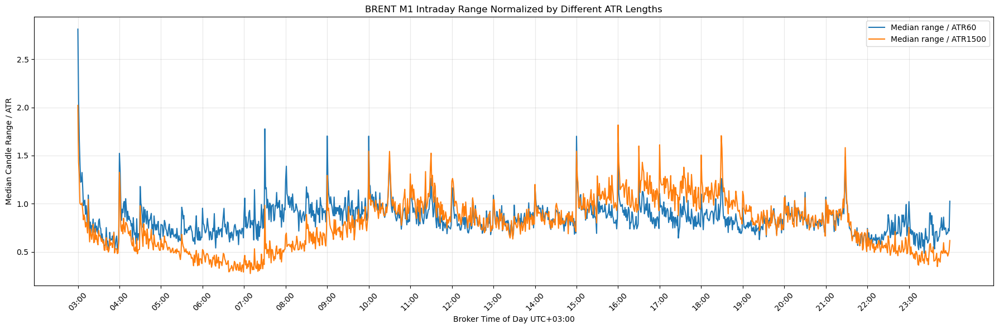

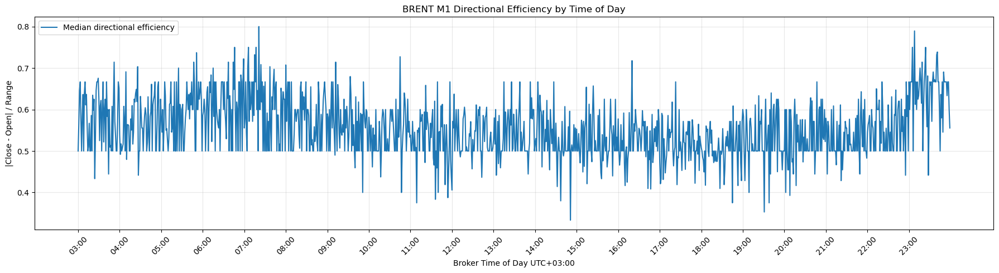

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,28451,0.565794,0.741020,0.911875,1.381767,0.283779,0.583333,0.416667,14.0,18.781871
Asia-London overlap,8551,0.994075,1.154231,1.411278,1.963085,0.495295,0.533333,0.466667,27.0,29.105953
London core,19411,0.923219,1.123673,1.330267,1.903122,0.460506,0.518519,0.481481,26.0,29.837000
London-NY overlap,10782,1.117493,1.309106,1.579680,2.178823,0.528883,0.500000,0.500000,39.0,40.340011
New York core,20068,0.722384,0.936013,1.100965,1.685265,0.348181,0.545455,0.454545,23.0,26.188210
Off-session,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


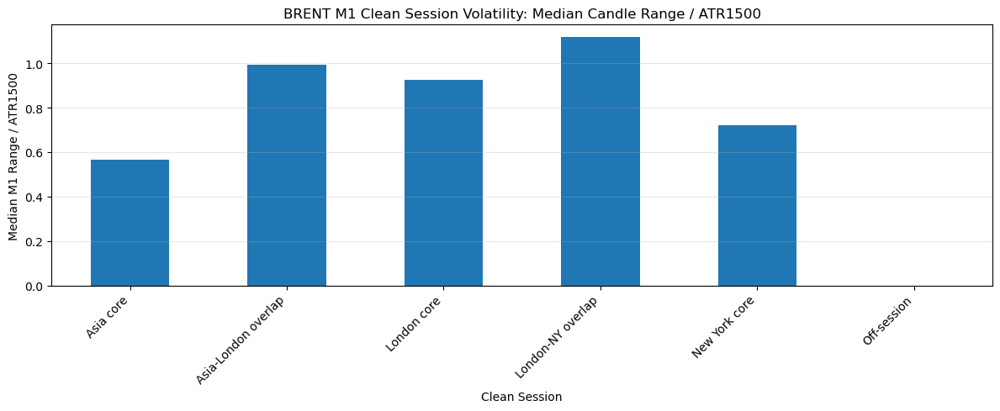

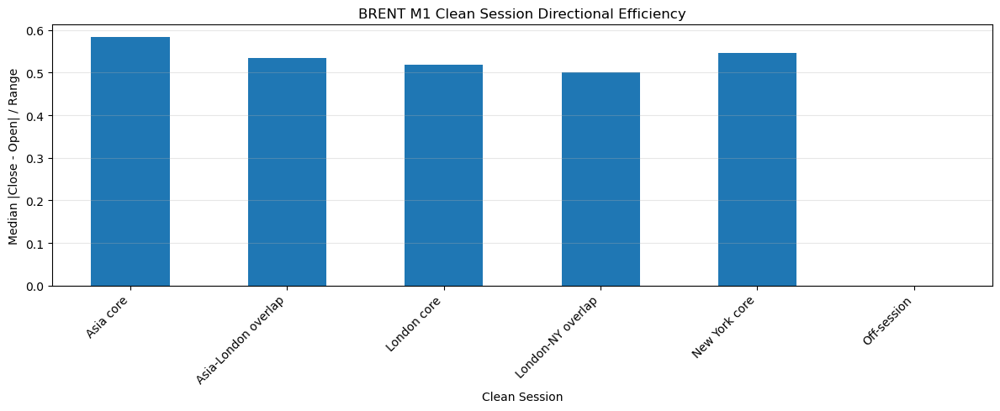

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,71,18.125771,20.919514,23.310173,32.425941,2.691946,3.027105,2.340,2.636761,7.000000
Asia-London overlap,72,15.038707,15.722052,18.072291,22.274897,7.573270,7.988447,1.740,1.915972,2.000000
London core,72,20.072776,24.281790,27.012309,35.262380,4.460617,5.398042,2.375,2.989167,4.500000
London-NY overlap,72,15.846120,18.568782,22.278070,29.579733,6.338448,7.442964,2.080,2.254722,2.500000
New York core,71,17.064958,19.949732,24.436878,34.355885,3.525685,4.170645,2.070,2.731127,4.983333
Off-session,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


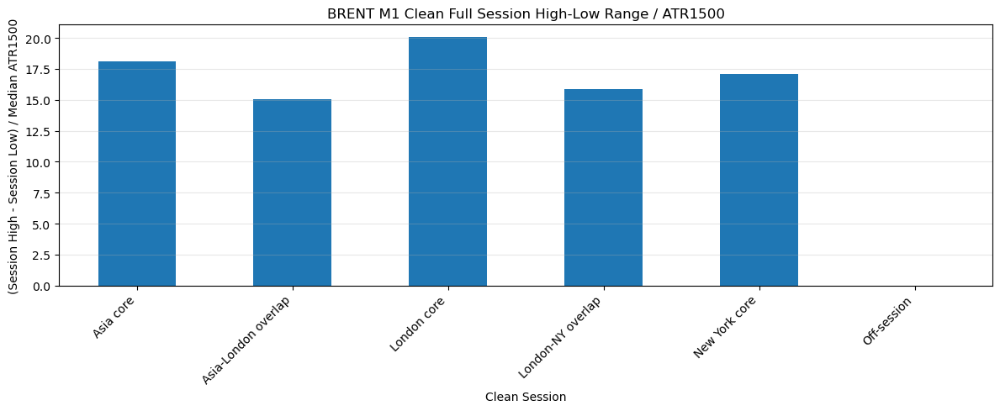

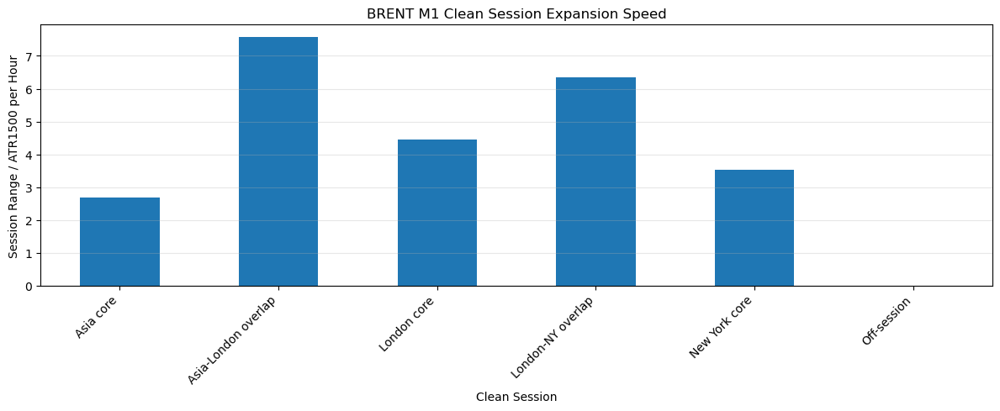

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


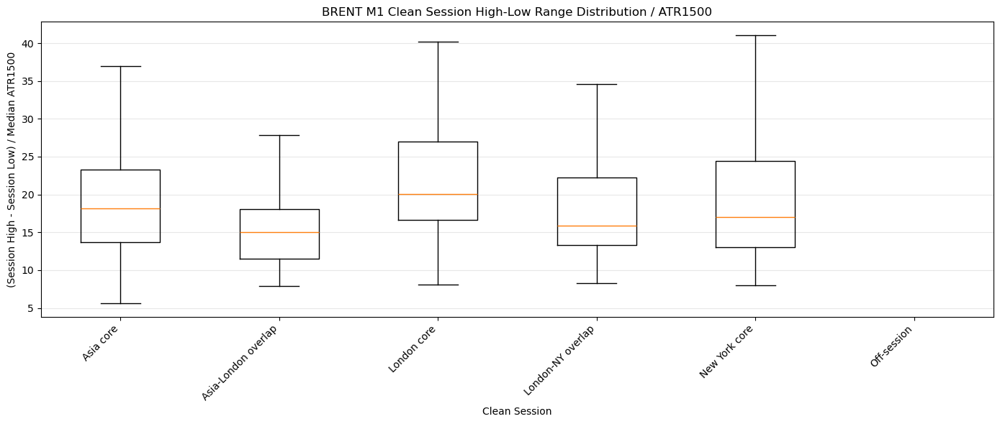

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
month_name,,,,,,,,,,,,,,,
January,213,1.640,1.793662,2.2000,2.866,0.905686,1.076852,1.353598,0.377017,0.472222,0.527778,0.940048,0.922509,0.862280,0.841296
February,201,1.600,1.851443,2.3200,2.930,0.947786,1.220355,1.524964,0.384979,0.483871,0.516129,0.931709,0.954373,0.874601,0.822496
March,219,1.950,3.354064,3.9100,6.904,1.574792,1.841074,3.172933,0.479499,0.494382,0.505618,0.940409,0.961221,1.126314,1.032142
April,206,1.850,2.663641,3.1625,5.510,1.225076,1.545680,2.135851,0.408705,0.442202,0.557798,0.825927,0.834589,0.864492,0.984111
May,216,1.860,2.358796,2.7550,3.970,1.085001,1.281712,1.745653,0.419586,0.492595,0.507405,0.928337,0.913983,0.887784,0.987356
June,192,1.750,2.137656,2.4550,3.785,1.016448,1.233376,1.534981,0.377381,0.442364,0.557636,0.919455,0.926292,0.875072,0.898572
July,199,1.550,1.993618,2.2500,3.604,0.950895,1.109751,1.541894,0.352487,0.460526,0.539474,0.874346,0.846241,0.786217,0.808221
August,200,1.705,1.931650,2.3025,3.386,0.915626,1.132156,1.467709,0.396121,0.493237,0.506763,0.899984,0.876363,0.860010,0.845638
September,190,1.705,1.921737,2.2500,3.115,0.909795,1.070242,1.340997,0.346483,0.428733,0.571267,0.955627,0.950384,0.909158,0.861637


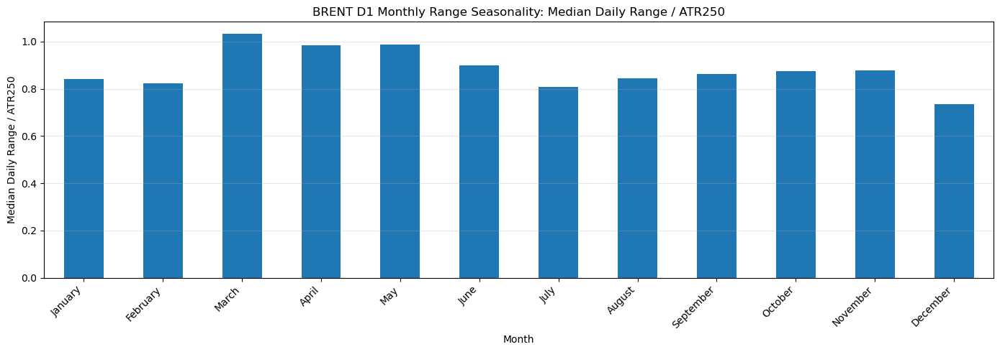

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:115: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


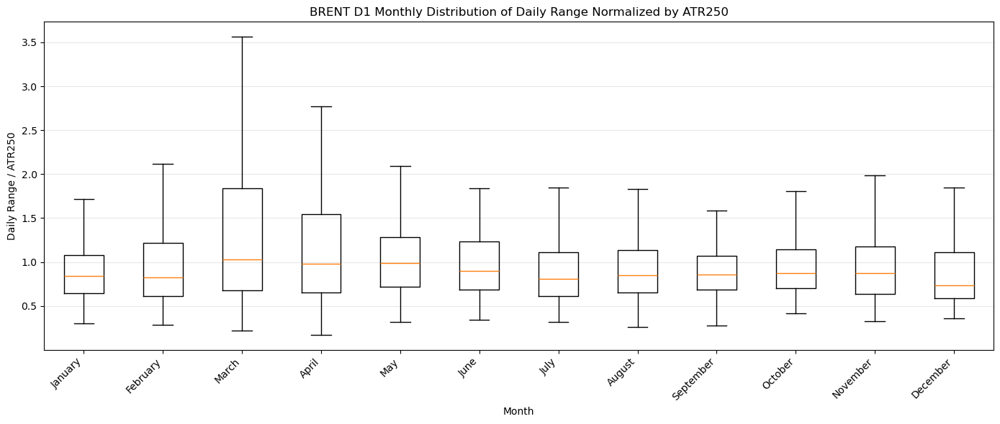

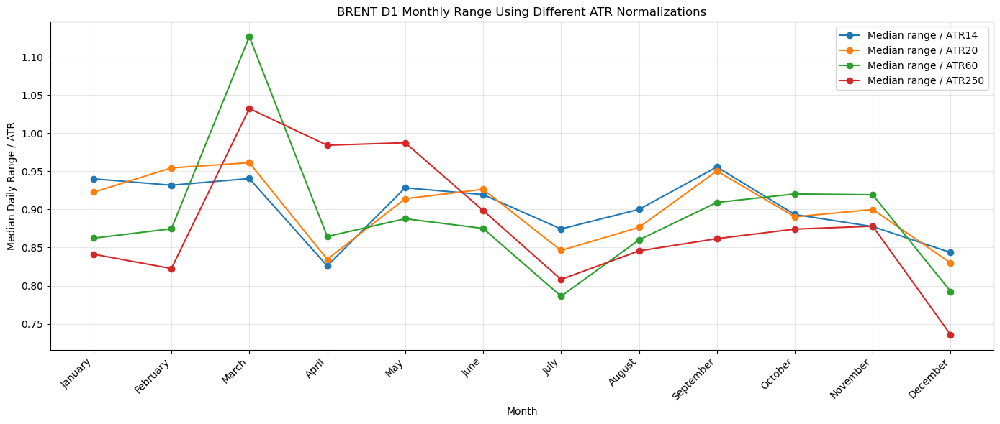

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
weekday,,,,,,,,,,,,,,,
Monday,483,1.66,2.134348,2.3800,3.702,1.026833,1.201773,1.585956,0.342070,0.447368,0.552632,0.851064,0.846356,0.856318,0.848755
Tuesday,488,1.69,2.164016,2.4200,3.853,1.036223,1.182805,1.708054,0.399302,0.470532,0.529468,0.908417,0.903057,0.873796,0.872364
Wednesday,488,1.85,2.290533,2.6025,3.829,1.097939,1.314577,1.791659,0.463935,0.500000,0.500000,0.962768,0.957987,0.946379,0.920444
Thursday,489,1.74,2.152065,2.4800,3.700,1.029464,1.214006,1.665724,0.355177,0.438202,0.561798,0.903964,0.908237,0.875974,0.855569
Friday,477,1.71,2.082348,2.3900,3.630,1.003007,1.167964,1.547635,0.377665,0.472441,0.527559,0.872562,0.864057,0.859107,0.850449


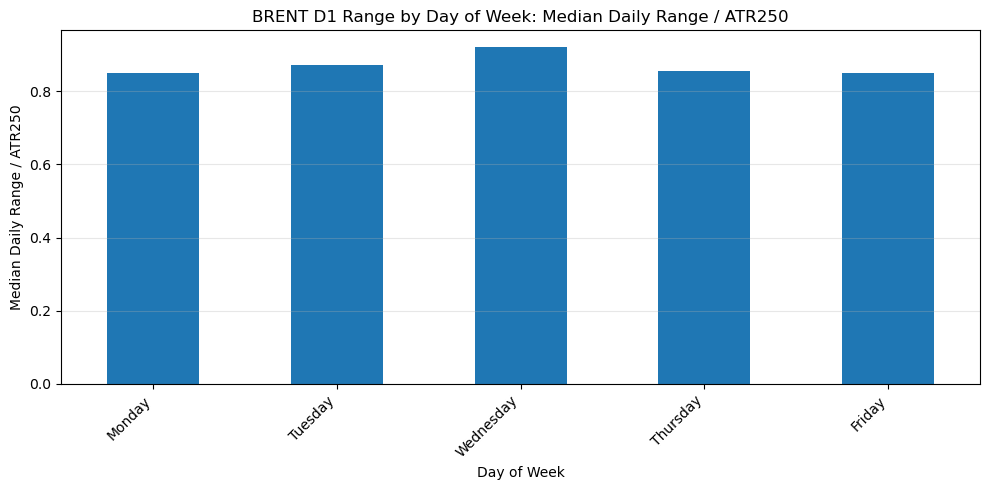

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:173: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


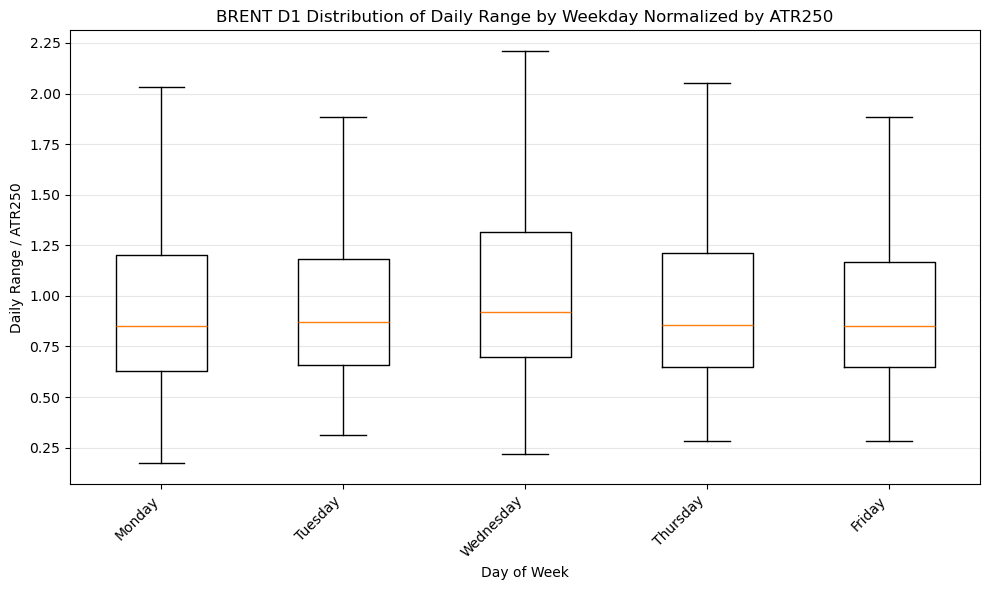

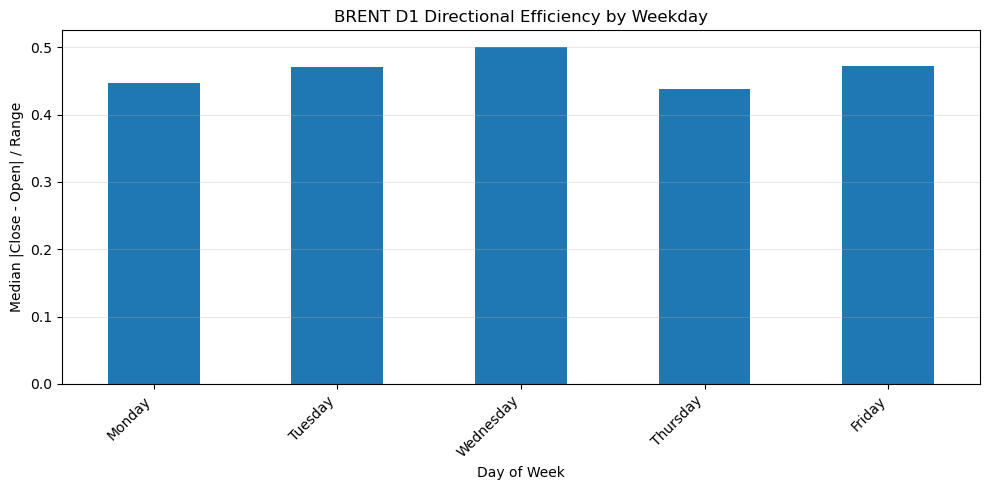

In [29]:
BRENT_m5 = analyze_asset_csv(r"mt5_data\BRENT_M5_max_bars.csv", timeframe="M5", asset_name="BRENT")
BRENT_m1 = analyze_asset_csv(r"mt5_data\BRENT_M1_max_bars.csv", timeframe="M1", asset_name="BRENT")
BRENT_d1 = analyze_asset_csv(r"mt5_data\BRENT_D1_max_bars.csv", timeframe="D1", asset_name="BRENT")

## BTCUSD

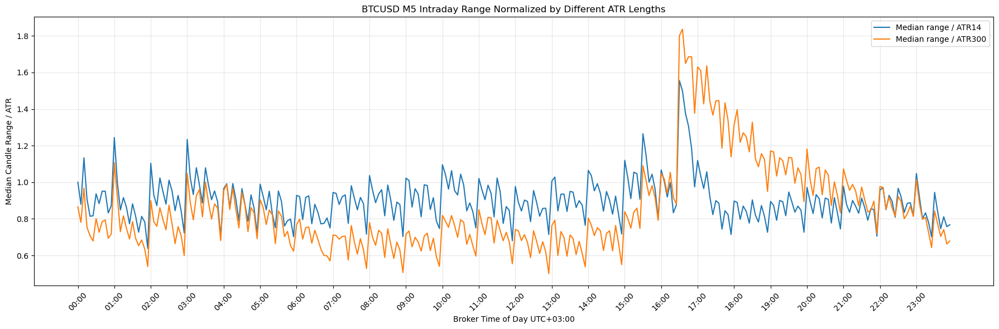

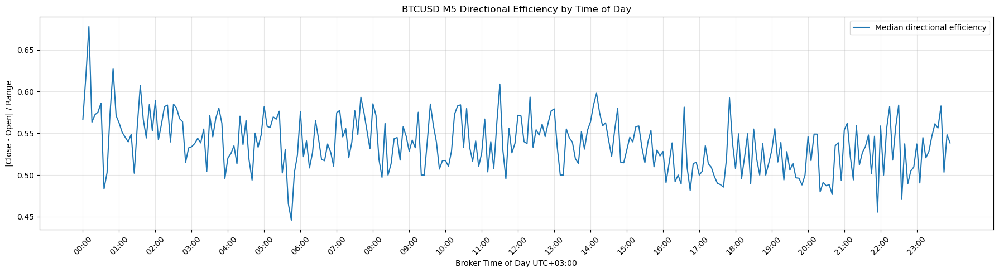

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,26183,0.733541,0.905725,1.099612,1.620409,0.357847,0.540541,0.459459,210.0,210.790971
Asia-London overlap,7480,0.730755,0.872491,1.069050,1.515461,0.362012,0.540472,0.459528,210.0,209.602674
London core,16831,0.746651,0.905558,1.109180,1.635117,0.362757,0.541667,0.458333,214.0,215.003862
London-NY overlap,9330,1.362418,1.548298,1.942151,2.662322,0.617191,0.514323,0.485677,282.0,293.860986
New York core,22416,0.901244,1.069961,1.312299,1.861010,0.432018,0.530896,0.469104,225.0,233.089847
Off-session,7446,0.750721,1.007788,1.164536,1.845256,0.385866,0.557334,0.442666,211.0,213.261214


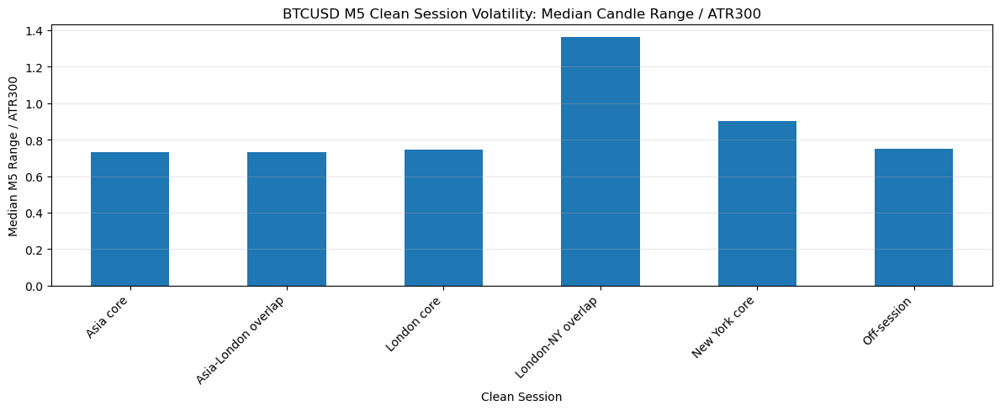

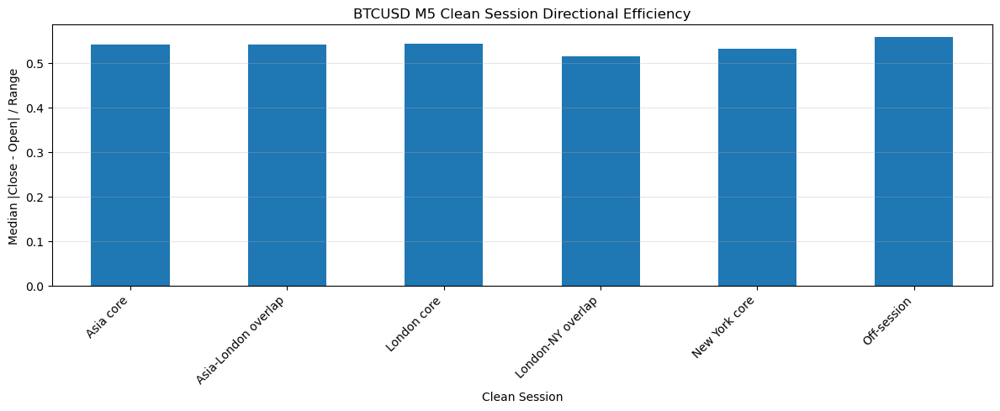

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,312,8.736323,10.352262,12.212536,17.340775,1.248046,1.480268,1167.0,1393.730769,7.0
Asia-London overlap,312,4.527271,5.163387,6.019034,8.491673,2.263635,2.582278,605.5,693.532051,2.0
London core,312,6.957498,8.050354,10.097522,13.521510,1.546111,1.790794,943.5,1094.711538,4.5
London-NY overlap,311,8.645785,9.763723,12.034693,16.166290,3.458314,3.905489,1242.0,1441.395498,2.5
New York core,313,15.237077,16.643059,21.216935,26.604804,2.545587,2.787430,2142.0,2437.897764,6.0
Off-session,311,4.196120,6.049800,6.808091,11.275021,2.098060,3.026525,609.0,772.006431,2.0


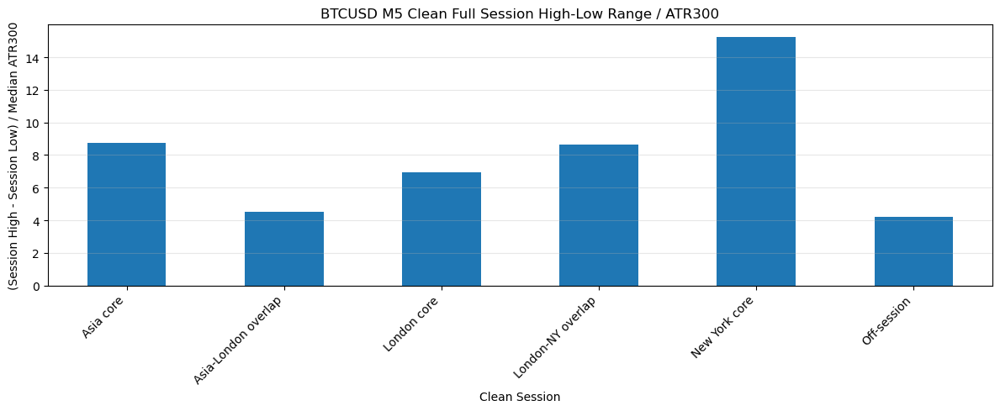

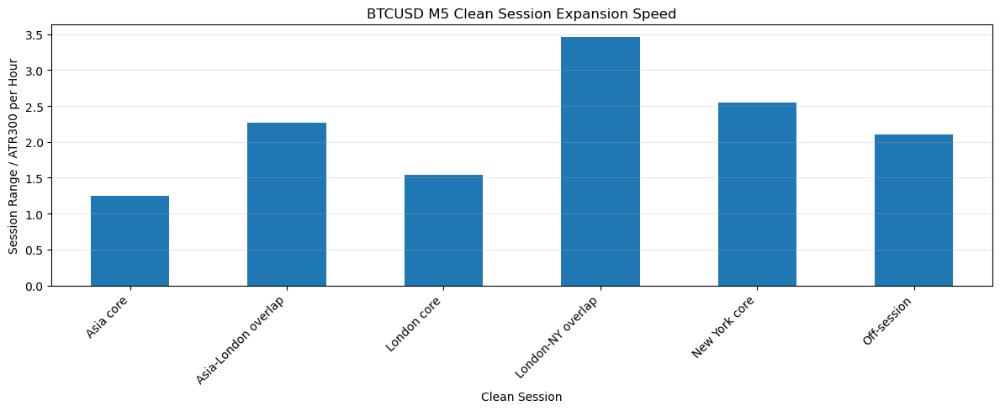

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


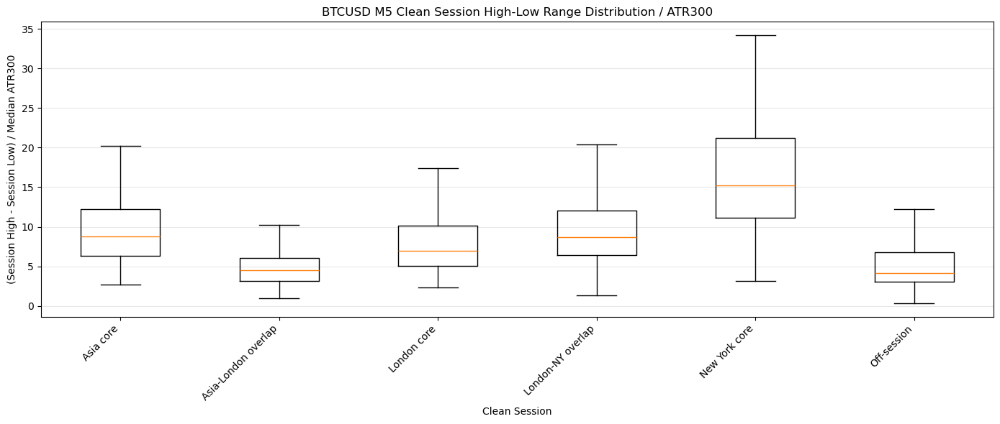

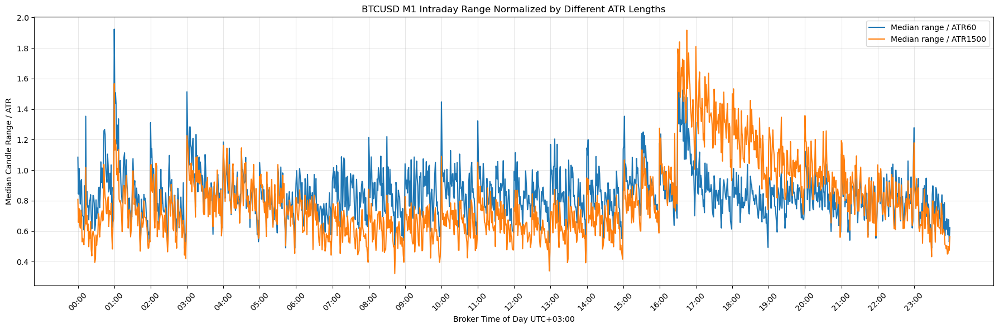

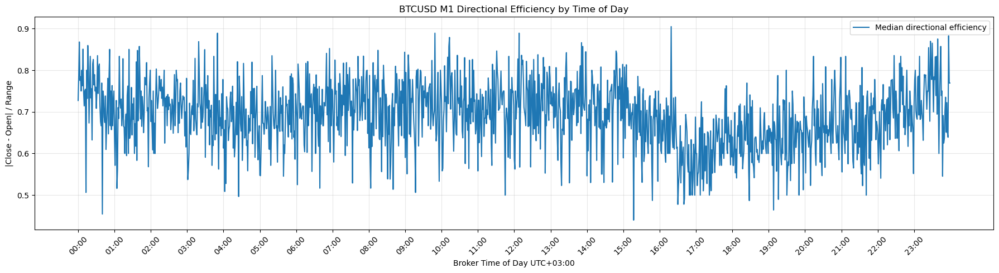

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,25874,0.696496,0.915620,1.140598,1.776014,0.418132,0.700000,0.300000,41.0,39.812746
Asia-London overlap,7402,0.661205,0.805449,1.044495,1.534393,0.397614,0.714286,0.285714,41.0,39.642394
London core,16644,0.693892,0.909890,1.153119,1.792194,0.417021,0.705882,0.294118,41.0,40.406453
London-NY overlap,9137,1.289082,1.516464,1.916715,2.698057,0.673971,0.611940,0.388060,49.0,48.605779
New York core,21886,0.821521,1.023246,1.286433,1.921931,0.483244,0.690476,0.309524,43.0,41.424015
Off-session,7287,0.731513,1.163003,1.347178,2.472841,0.447195,0.708333,0.291667,42.0,41.189516


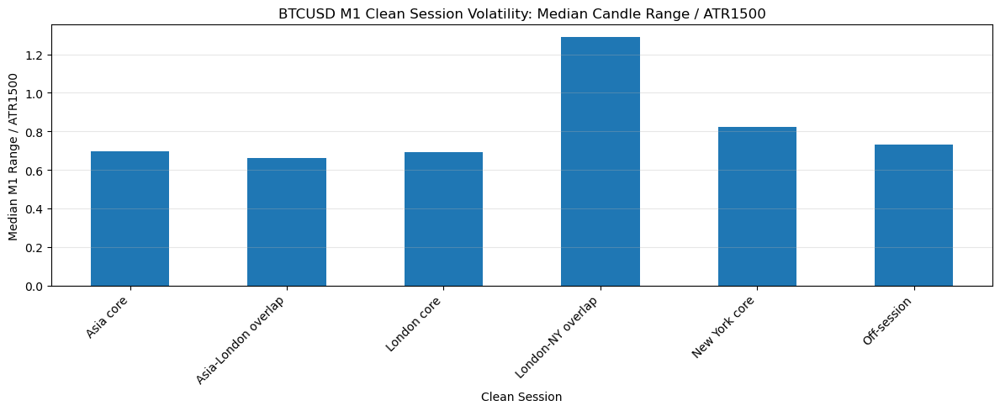

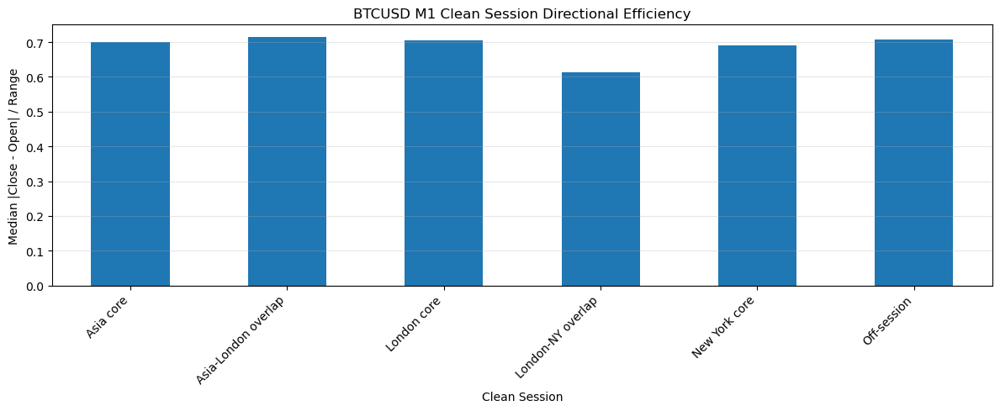

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,62,24.219515,28.377193,32.370584,52.939854,3.468005,4.066912,881.5,1018.854839,7.0
Asia-London overlap,62,12.305112,12.654584,16.370602,18.127691,6.152556,6.329618,487.0,485.096774,2.0
London core,62,20.155843,23.154258,27.417232,38.967344,4.488464,5.164300,784.5,875.661290,4.5
London-NY overlap,61,22.090897,25.433476,30.141455,42.356367,8.836359,10.173390,918.0,985.344262,2.5
New York core,62,40.603299,43.690775,56.837954,71.242931,6.786419,7.405854,1527.5,1679.774194,6.0
Off-session,61,11.675960,20.254534,20.872504,48.939309,5.837980,10.130460,501.0,682.475410,2.0


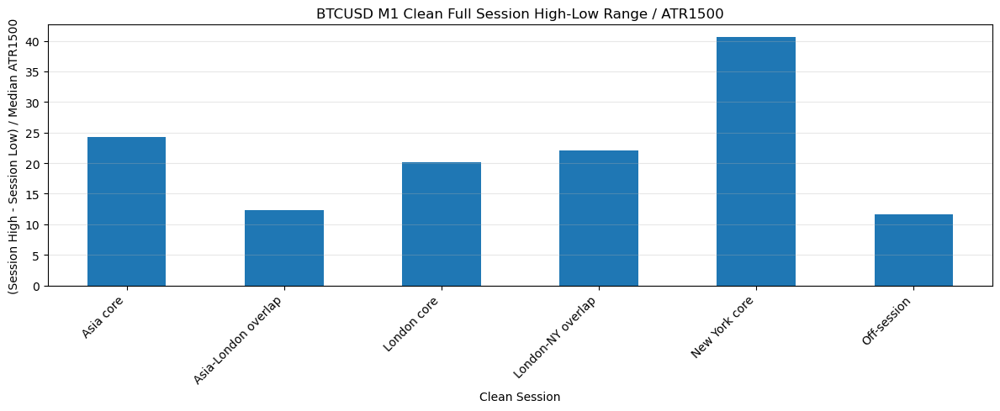

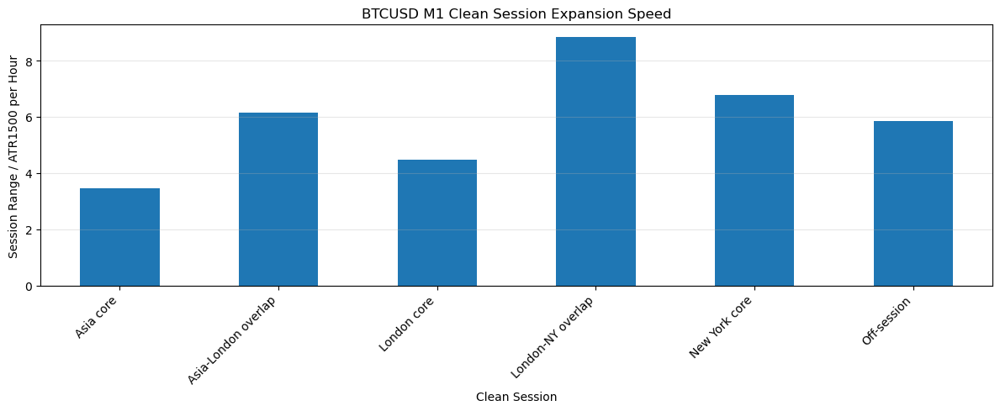

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


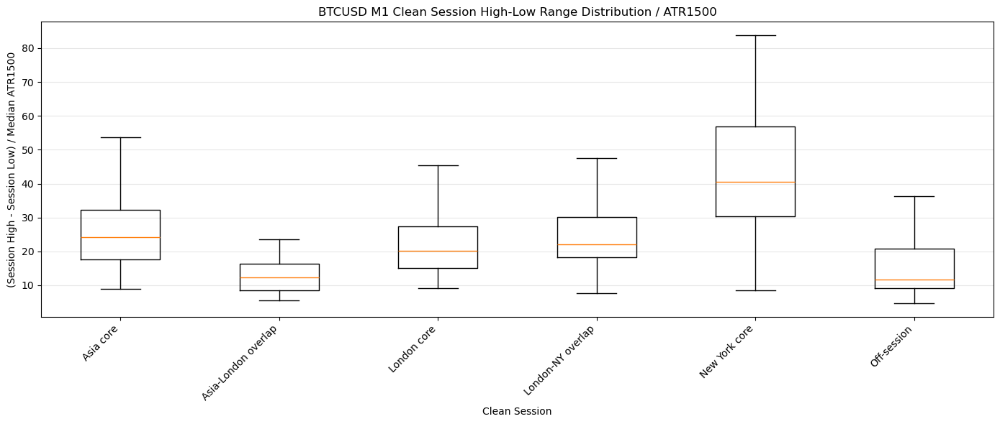

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
month_name,,,,,,,,,,,,,,,
January,309,425.0,1411.799353,2305.00,3950.6,1.856390,2.310272,4.054300,0.467602,0.428571,0.571429,0.997479,1.020037,1.009524,1.157715
February,282,605.5,1467.663121,2262.25,4007.2,1.521527,1.890379,3.037348,0.413669,0.422845,0.577155,0.945231,0.936748,0.906111,1.068214
March,310,615.5,1509.209677,2579.50,4117.8,1.869217,2.047277,3.546520,0.458972,0.419207,0.580793,0.929715,0.942150,0.913274,1.147723
April,301,462.0,1244.481728,2084.00,3540.0,1.885098,1.513568,2.697863,0.374353,0.446897,0.553103,0.971127,0.934066,0.819931,0.898567
May,304,490.0,1257.226974,2030.25,3387.4,1.263276,1.501961,2.454465,0.392945,0.449262,0.550738,0.956605,0.933370,0.905529,0.958286
June,278,336.0,992.399281,1731.25,2694.9,1.243574,1.452965,2.306205,0.364825,0.463846,0.536154,0.891646,0.905500,0.871434,0.904507
July,295,419.0,928.196610,1452.50,2634.4,1.128413,1.274956,2.198105,0.305368,0.411765,0.588235,0.976744,0.921828,0.886477,0.801625
August,299,390.0,951.454849,1229.00,2954.4,1.191233,1.325109,2.159768,0.326194,0.438840,0.561160,0.927395,0.917431,0.909540,0.822490
September,281,387.0,896.466192,1317.00,2584.0,0.904300,1.117503,1.703660,0.244865,0.386957,0.613043,0.954614,0.933661,0.844410,0.706882


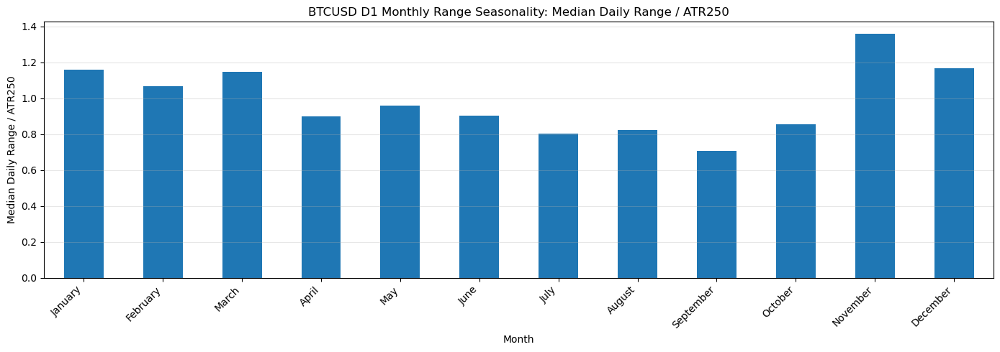

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:115: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


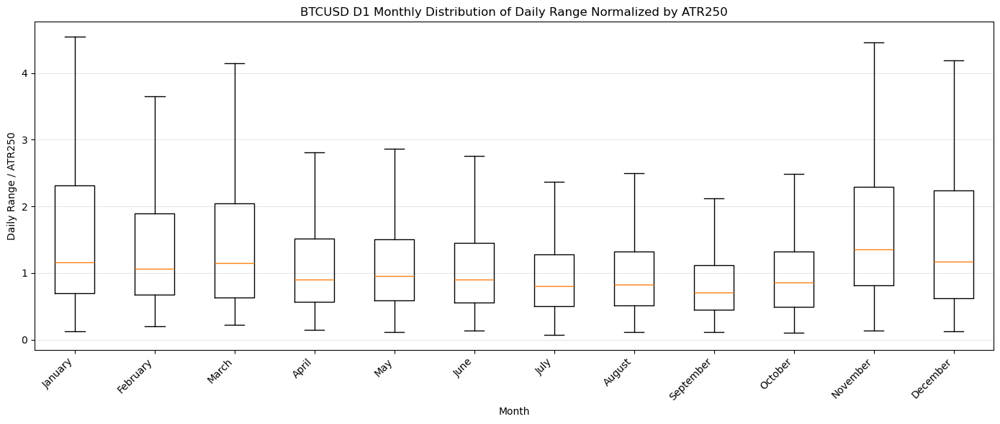

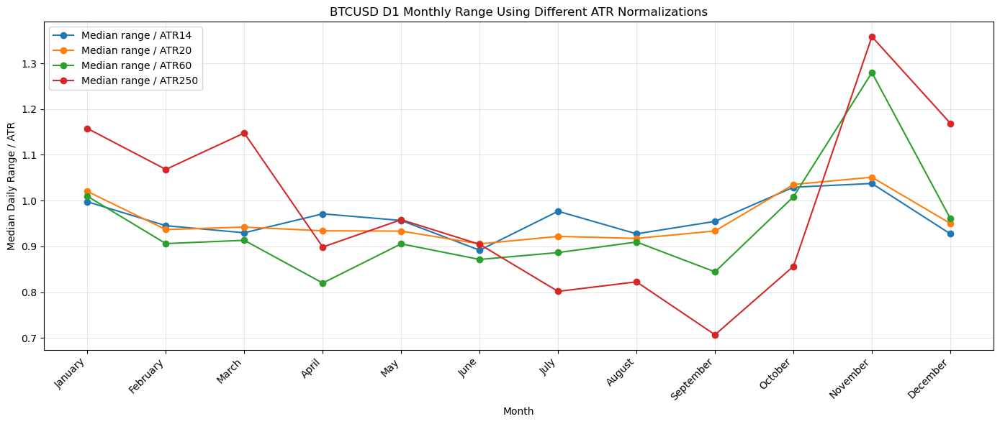

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
weekday,,,,,,,,,,,,,,,
Monday,706,450.0,1283.923513,2145.0,3717.5,1.453361,1.677037,2.806457,0.387854,0.440905,0.559095,0.984317,0.975971,0.975809,0.985701
Tuesday,704,421.0,1168.852273,1924.0,3324.4,1.453845,1.592199,2.743007,0.374410,0.427396,0.572604,0.923512,0.918655,0.902407,0.925726
Wednesday,701,467.0,1203.747504,1951.0,3444.0,1.526092,1.638019,2.824933,0.383199,0.446602,0.553398,0.966598,0.973541,0.964935,0.961571
Thursday,709,425.0,1143.612130,1809.0,3300.2,1.537954,1.642977,3.019658,0.374662,0.441860,0.558140,0.965891,0.957540,0.930233,0.937096
Friday,706,410.0,1203.379603,1786.5,3701.5,1.465845,1.697895,2.905602,0.364825,0.403220,0.596780,0.961521,0.940104,0.910183,0.963189


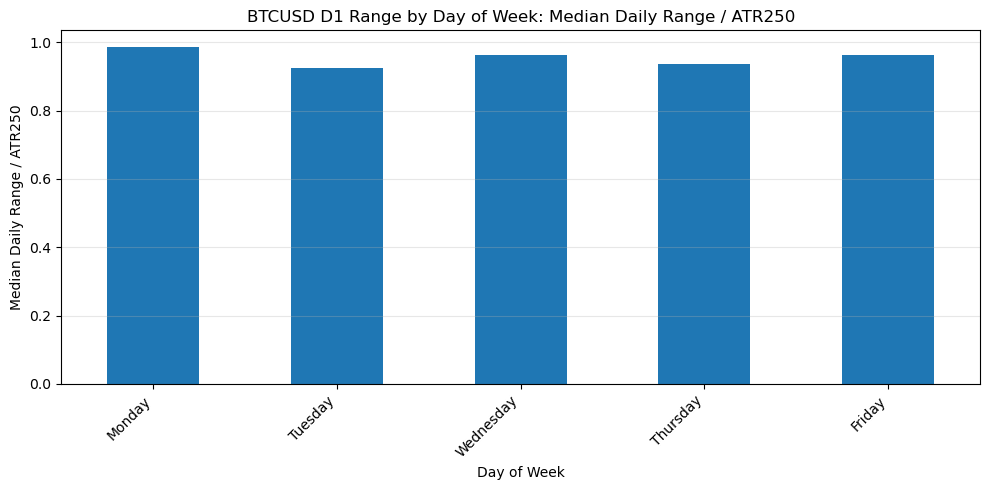

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:173: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


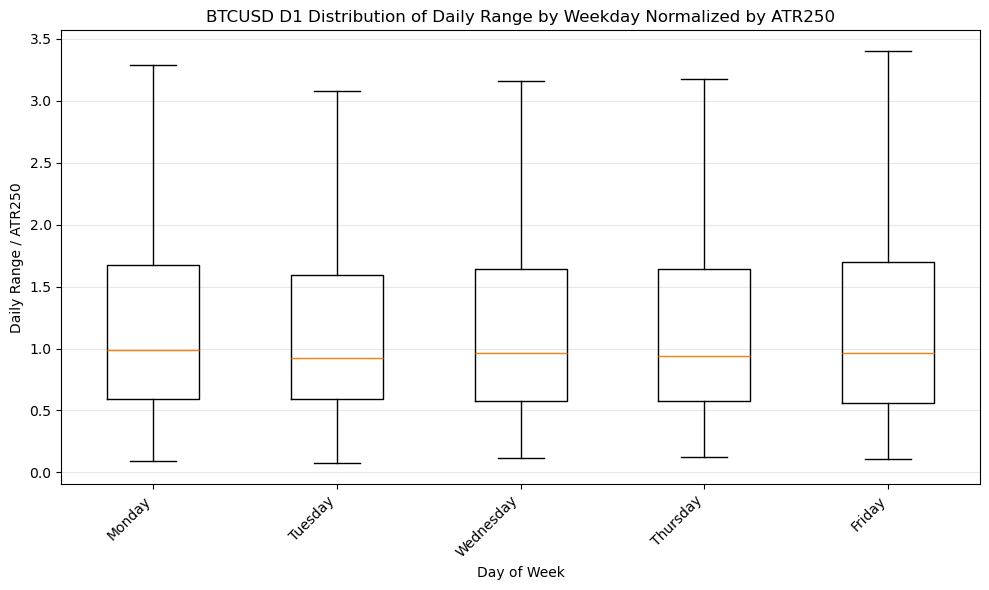

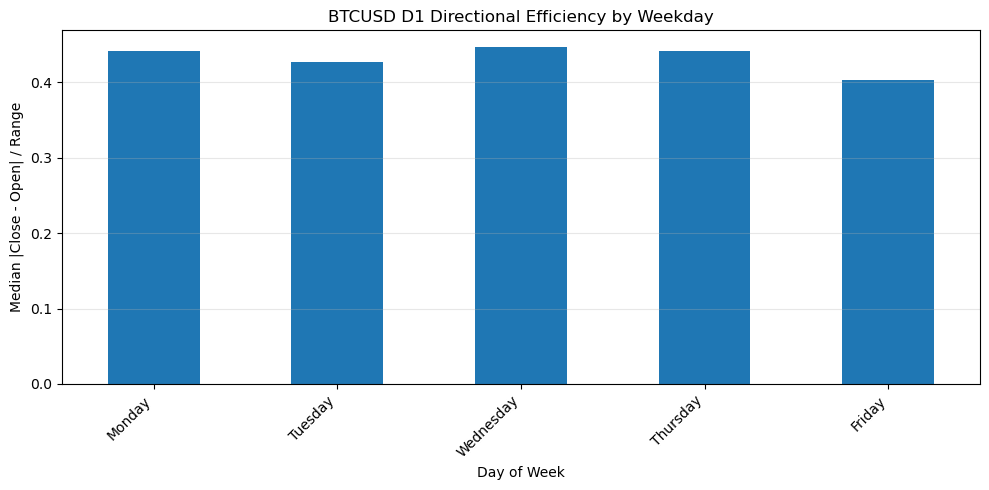

In [30]:
BTCUSD_m5 = analyze_asset_csv(r"mt5_data\BTCUSD_M5_max_bars.csv", timeframe="M5", asset_name="BTCUSD")
BTCUSD_m1 = analyze_asset_csv(r"mt5_data\BTCUSD_M1_max_bars.csv", timeframe="M1", asset_name="BTCUSD")
BTCUSD_d1 = analyze_asset_csv(r"mt5_data\BTCUSD_D1_max_bars.csv", timeframe="D1", asset_name="BTCUSD")

## FTSE100

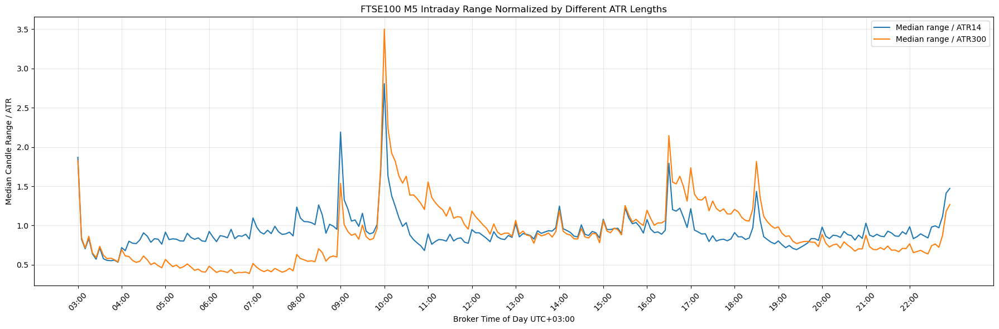

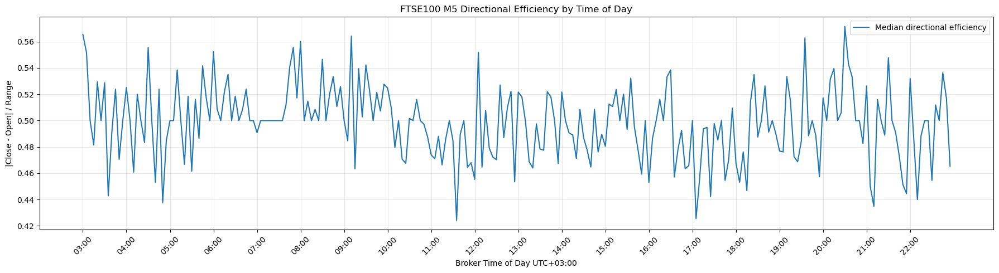

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,31502,0.565108,0.692230,0.834413,1.215183,0.263191,0.500000,0.500000,62.0,79.455527
Asia-London overlap,9024,1.372130,1.571324,1.852449,2.521096,0.626105,0.486486,0.513514,156.0,175.708666
London core,20214,0.953952,1.059216,1.249687,1.616654,0.441958,0.494118,0.505882,110.0,128.863956
London-NY overlap,11130,1.280798,1.414302,1.696680,2.195647,0.582538,0.483184,0.516816,185.0,202.750314
New York core,17794,0.760805,0.869498,1.044850,1.426553,0.351014,0.500000,0.500000,95.0,112.698831
Off-session,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


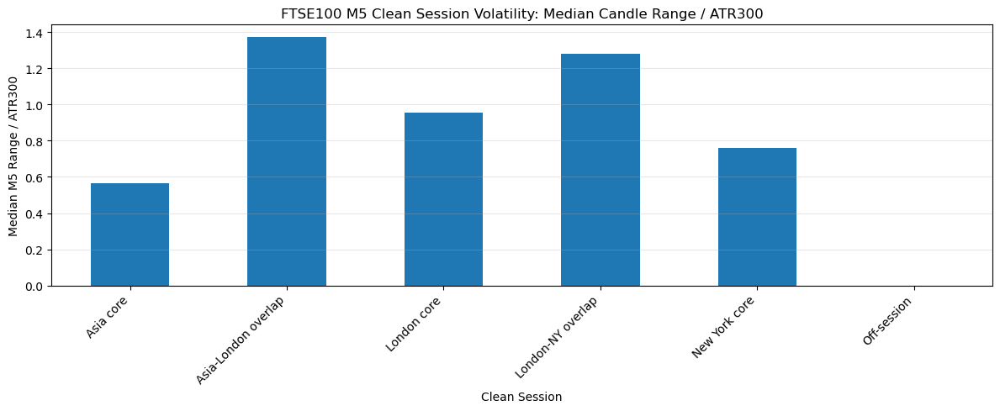

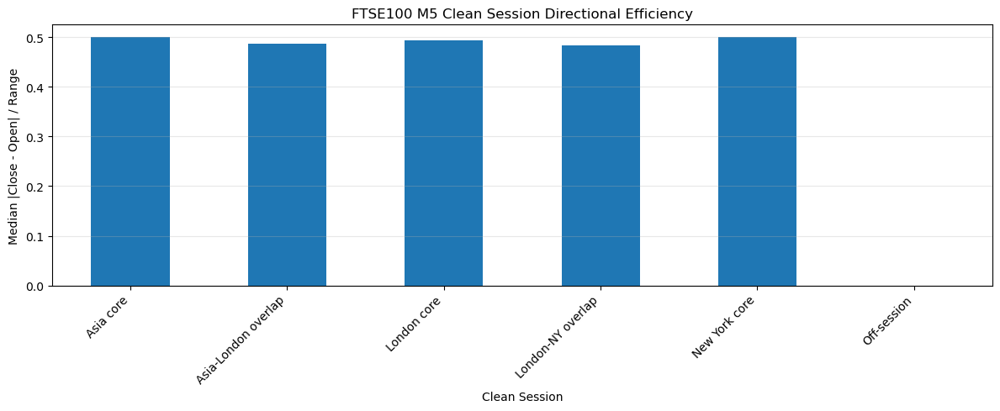

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,376,6.873883,7.665046,9.079073,12.351855,0.981983,1.098175,33.25,41.558511,7.0
Asia-London overlap,376,7.739298,8.319281,9.561867,12.011126,3.869649,4.159641,38.05,45.480585,2.0
London core,376,7.702133,8.420478,9.780057,12.291723,1.715658,1.884207,39.70,49.299468,4.5
London-NY overlap,371,7.671958,8.228273,9.707771,11.966001,3.068783,3.291309,40.80,47.880323,2.5
New York core,372,6.061267,6.649911,7.869815,9.933952,1.517014,1.666755,31.90,40.863978,4.0
Off-session,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


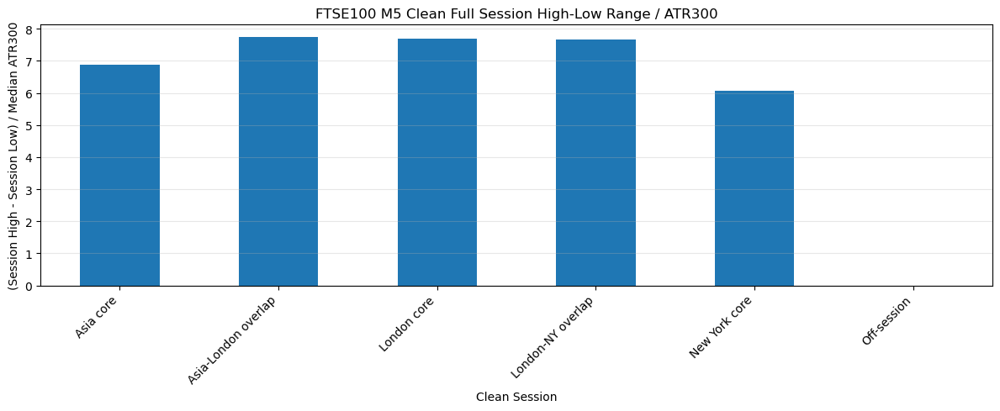

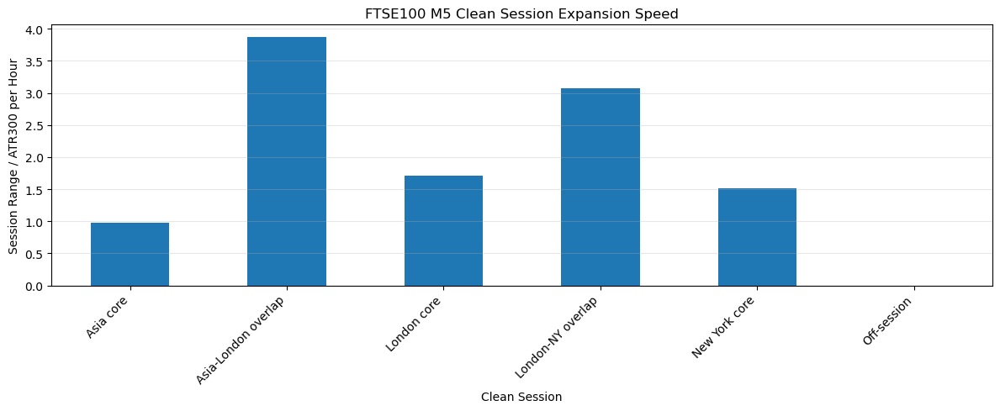

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


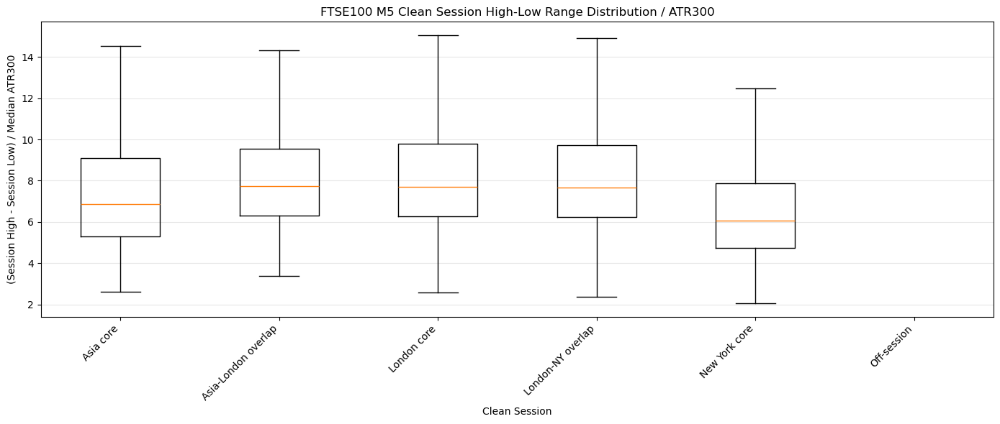

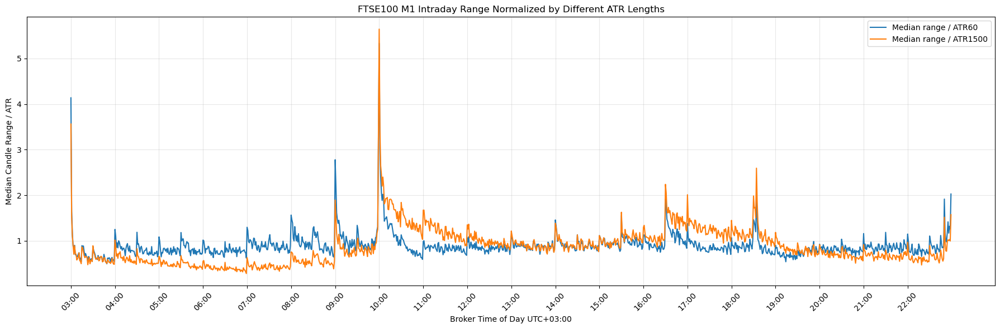

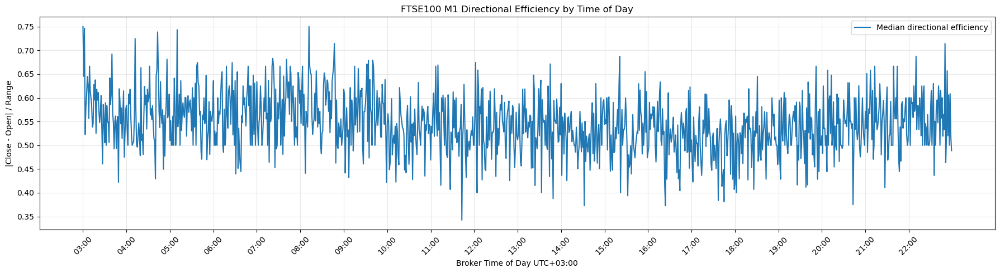

,candles,median_range_atr,mean_range_atr,p75_range_atr,p90_range_atr,median_body_atr,median_directional_efficiency,median_wick_ratio,median_tick_volume,mean_tick_volume
session_clean,,,,,,,,,,
Asia core,30898,0.541954,0.668028,0.832452,1.227432,0.267794,0.571429,0.428571,22.0,25.041815
Asia-London overlap,8880,1.366922,1.560309,1.864941,2.497810,0.680093,0.531250,0.468750,46.0,48.029167
London core,19979,0.962580,1.084725,1.300195,1.729300,0.476435,0.529412,0.470588,36.0,39.020471
London-NY overlap,11081,1.256150,1.416841,1.725067,2.269737,0.596380,0.511111,0.488889,54.0,53.727461
New York core,17491,0.703622,0.832411,1.024965,1.448039,0.347913,0.543478,0.456522,29.0,30.722657
Off-session,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


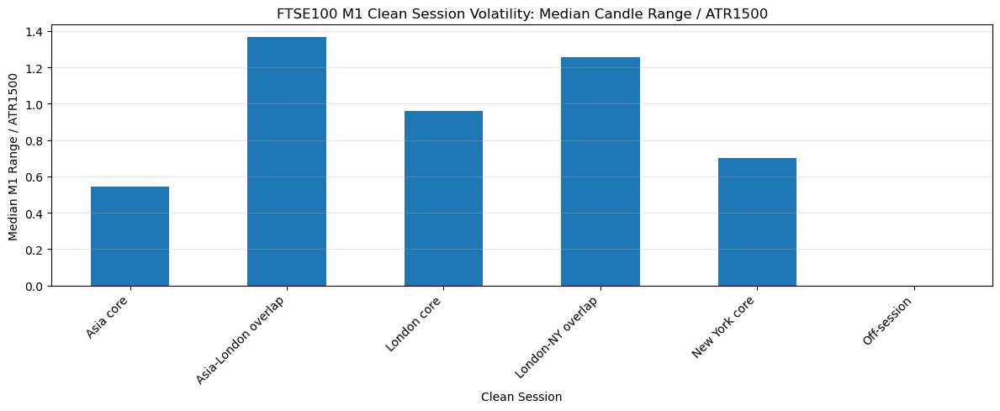

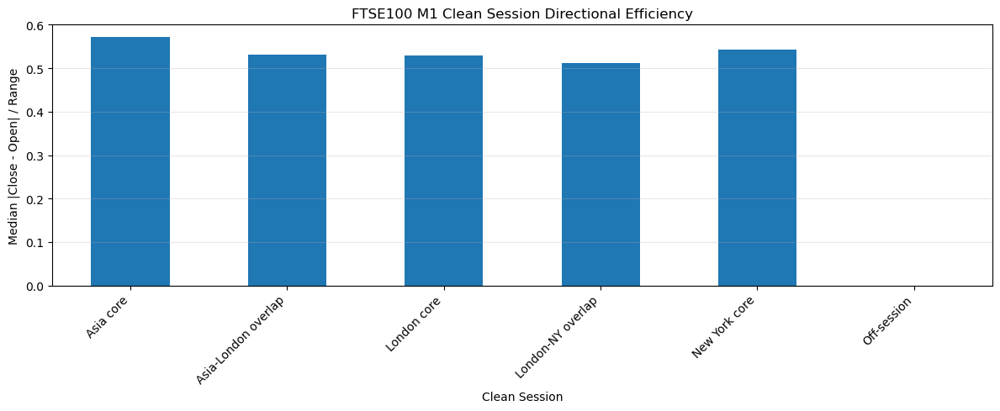

,sessions,median_session_range_atr,mean_session_range_atr,p75_session_range_atr,p90_session_range_atr,median_range_atr_per_hour,mean_range_atr_per_hour,median_raw_range,mean_raw_range,median_duration_hours
session_clean,,,,,,,,,,
Asia core,74,17.772213,19.252618,23.599388,30.498453,2.541892,2.754502,52.55,61.944595,7.0
Asia-London overlap,74,18.710931,20.790988,25.387453,28.324408,9.355465,10.395494,61.70,67.068919,2.0
London core,74,19.278016,21.882748,27.829336,34.747064,4.284004,4.863001,73.10,76.372973,4.5
London-NY overlap,74,18.018811,19.646799,23.554666,29.115502,7.243101,7.876491,64.90,67.290541,2.5
New York core,74,14.381175,15.479476,18.839961,22.863480,3.631271,3.913721,45.75,55.251351,4.0
Off-session,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


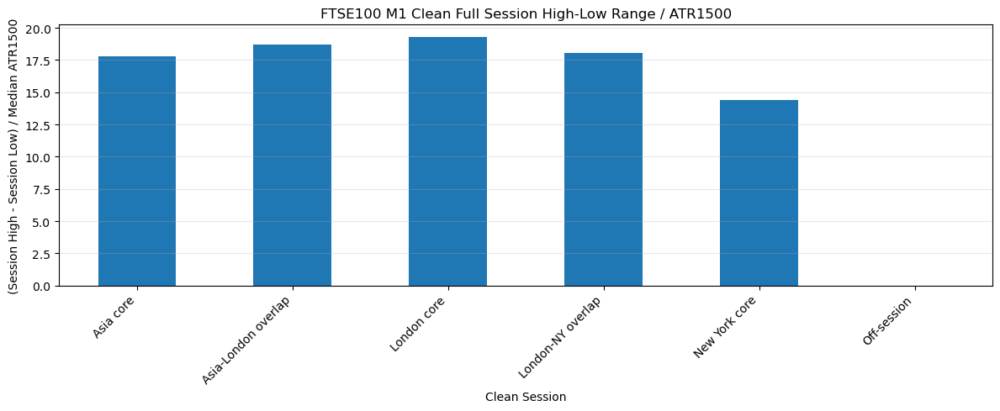

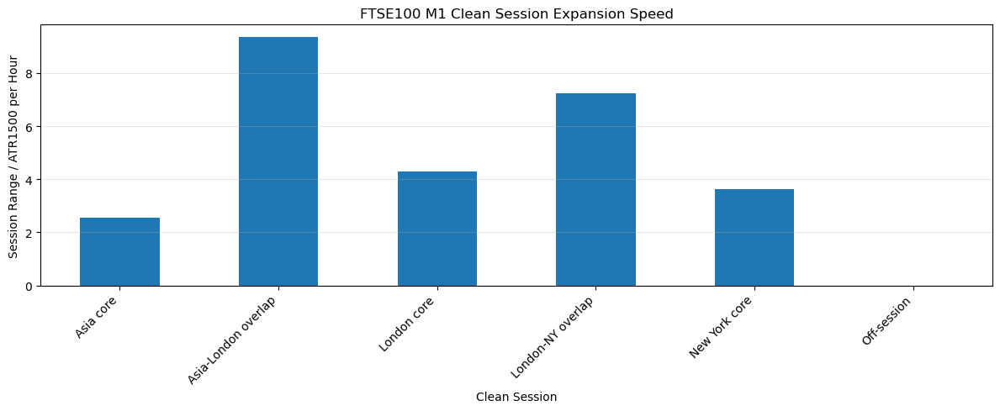

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\3789735906.py:266: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


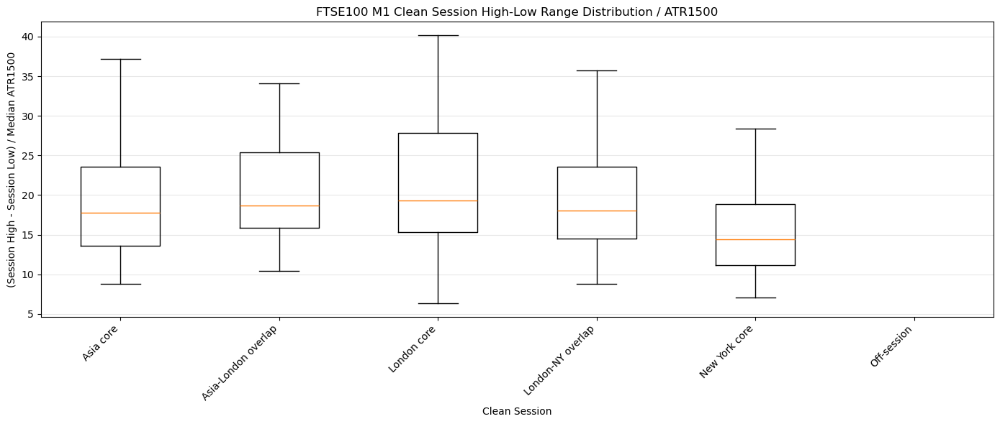

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
month_name,,,,,,,,,,,,,,,
January,170,78.85,89.647059,105.300,138.75,0.965672,1.183861,1.521780,0.358053,0.451447,0.548553,0.951505,0.899906,0.899328,0.852977
February,161,80.60,94.429814,108.800,159.20,1.020882,1.167306,1.624114,0.395250,0.469298,0.530702,0.922095,0.941655,0.937278,0.880644
March,175,102.50,148.560571,193.900,319.82,1.532850,1.982977,3.209814,0.530405,0.508655,0.491345,0.954348,0.992610,1.025435,1.013533
April,163,85.30,108.347853,128.900,199.78,1.111250,1.316334,1.747575,0.358697,0.403571,0.596429,0.871191,0.806160,0.786223,0.899142
May,161,93.20,101.081988,120.900,161.60,1.024437,1.222669,1.619225,0.428116,0.486066,0.513934,0.909430,0.920152,0.844800,0.942384
June,149,76.50,92.284564,114.800,153.18,0.931137,1.155874,1.448146,0.332152,0.431078,0.568922,0.893282,0.886981,0.819984,0.803811
July,156,80.45,88.819231,106.675,137.55,0.914651,1.084549,1.399964,0.369962,0.462389,0.537611,0.911776,0.910151,0.866029,0.832940
August,158,77.05,86.889873,101.225,141.25,0.922962,1.160470,1.454046,0.365640,0.476999,0.523001,0.881085,0.860249,0.849225,0.788470
September,171,83.50,91.005263,105.300,135.30,0.962013,1.174689,1.350469,0.357337,0.376190,0.623810,0.998317,1.000309,0.977659,0.891195


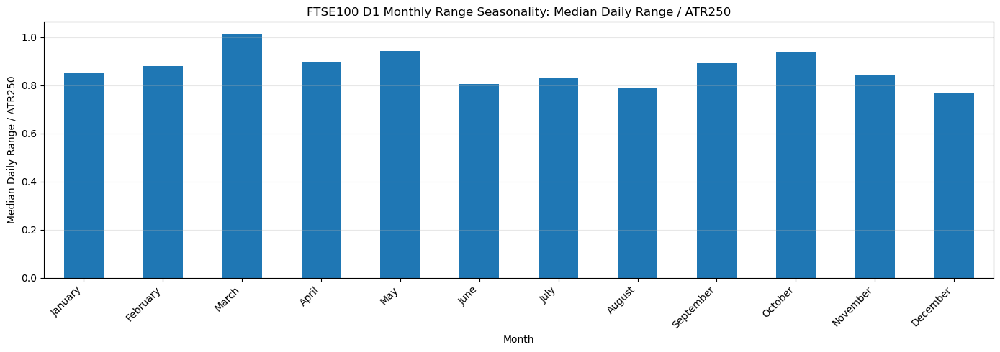

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:115: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


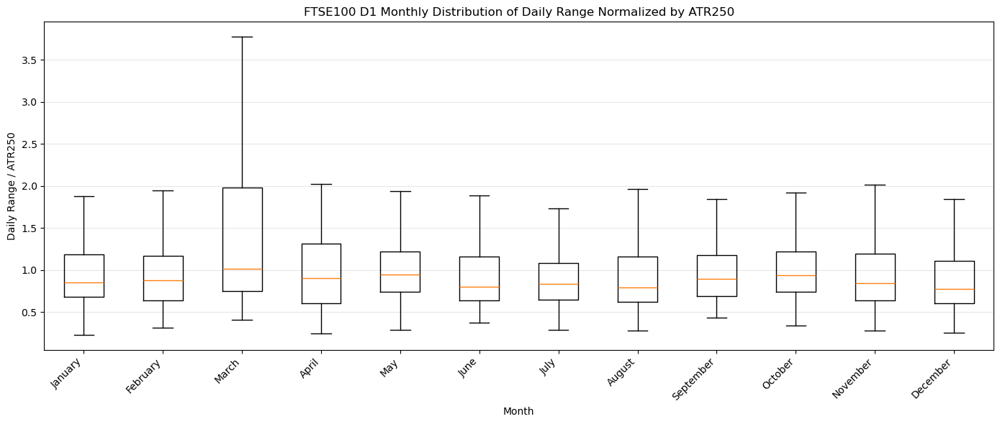

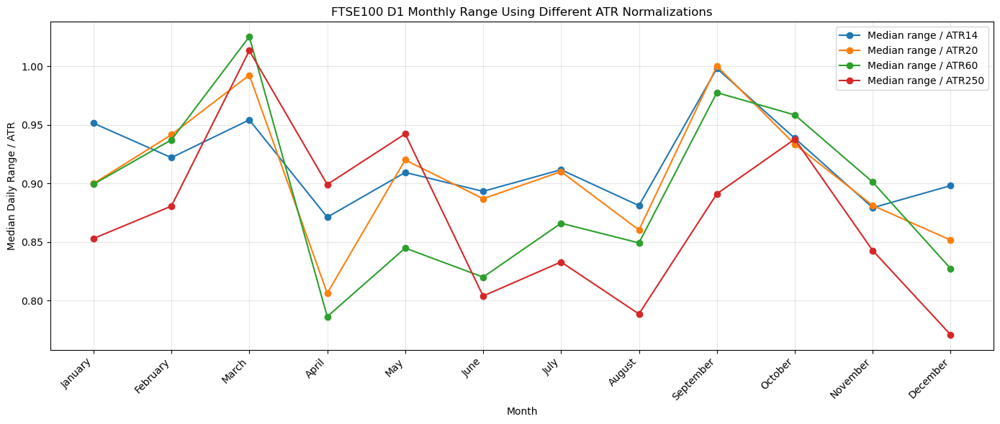

,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
weekday,,,,,,,,,,,,,,,
Monday,381,78.8,94.926247,107.400,151.10,0.992509,1.134324,1.587237,0.325018,0.407643,0.592357,0.878344,0.875230,0.849946,0.838053
Tuesday,400,83.0,97.639000,116.975,156.41,1.023589,1.232750,1.559492,0.380633,0.444898,0.555102,0.928821,0.917679,0.899464,0.886653
Wednesday,400,83.9,96.071000,116.450,158.81,1.003622,1.224462,1.624505,0.403378,0.460060,0.539940,0.913804,0.896049,0.874745,0.860306
Thursday,401,83.9,100.181546,111.800,167.70,1.050693,1.224775,1.698529,0.388407,0.462656,0.537344,0.944936,0.930622,0.906026,0.894682
Friday,395,84.2,98.860506,118.950,160.82,1.044345,1.260917,1.637157,0.401022,0.455738,0.544262,0.929732,0.933844,0.912950,0.874311


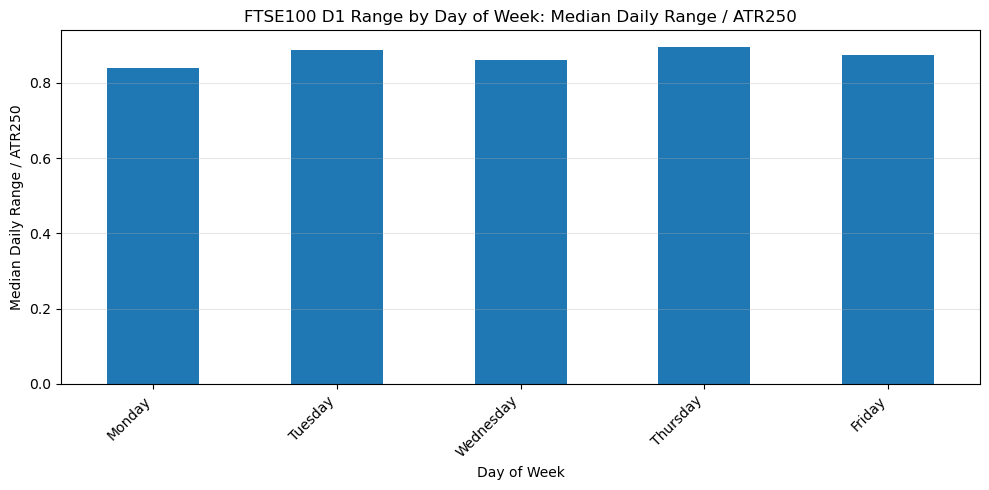

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\1418924779.py:173: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


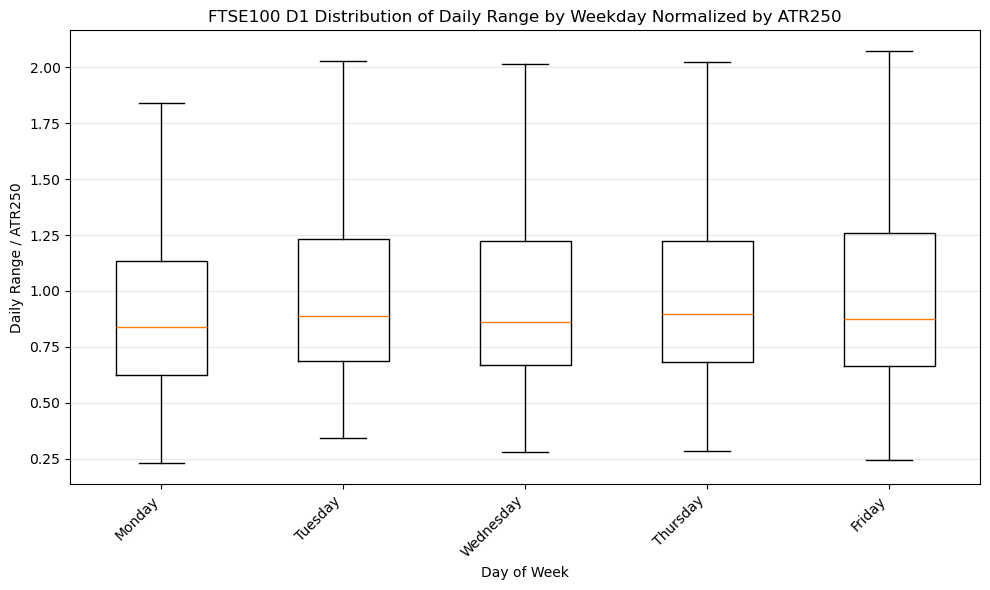

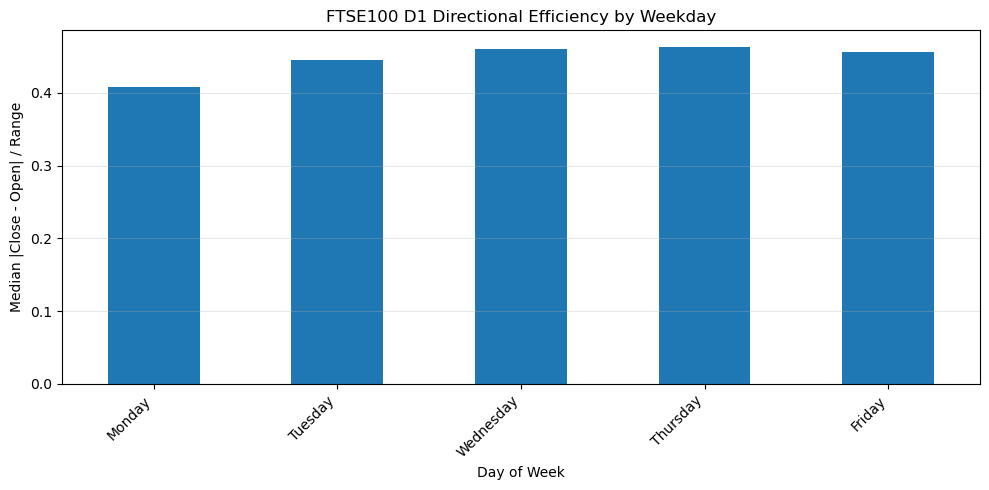

In [ ]:
FTSE100_m5 = analyze_asset_csv(r"mt5_data\FTSE100_M5_max_bars.csv", timeframe="M5", asset_name="FTSE100")
FTSE100_m1 = analyze_asset_csv(r"mt5_data\FTSE100_M1_max_bars.csv", timeframe="M1", asset_name="FTSE100")
FTSE100_d1 = analyze_asset_csv(r"mt5_data\FTSE100_D1_max_bars.csv", timeframe="D1", asset_name="FTSE100")

## M5 Time-of-Day Volatility Comparison Across Assets

In [ ]:
# %% [markdown]
# ## M5 Time-of-Day Volatility Comparison Across Assets

# %%
def compare_m5_time_of_day_volatility(
    m5_results,
    atr_period=300,
    stat="median",
    plot=True,
):
    """
    Compare M5 time-of-day volatility across assets.

    Uses the tod_stats output from analyze_intraday_csv().
    Default uses median M5 candle range / ATR300.

    Parameters
    ----------
    m5_results : dict
        Dictionary like:
        {
            "EURUSD": eurusd_m5,
            "USDJPY": usdjpy_m5,
            ...
        }

    atr_period : int
        ATR period used for normalization.
        For your M5 analysis, the default structural ATR is 300.

    stat : str
        "median" or "mean".

    plot : bool
        Whether to plot the comparison chart.

    Returns
    -------
    comparison_df : pd.DataFrame
        Rows are broker times of day.
        Columns are assets.
        Values are M5 range / ATR.
    """
    value_col = f"range_atr{atr_period}_{stat}"

    comparison_parts = []

    for asset_name, result in m5_results.items():
        tod_stats = result["tod_stats"].copy()

        if value_col not in tod_stats.columns:
            raise ValueError(
                f"{value_col} not found for {asset_name}. "
                f"Available columns: {list(tod_stats.columns)}"
            )

        asset_series = (
            tod_stats[["tod", value_col]]
            .rename(columns={value_col: asset_name})
            .set_index("tod")
        )

        comparison_parts.append(asset_series)

    comparison_df = pd.concat(comparison_parts, axis=1)

    display(comparison_df)

    if plot:
        x = np.arange(len(comparison_df))

        plt.figure(figsize=(20, 7))

        for asset_name in comparison_df.columns:
            plt.plot(
                x,
                comparison_df[asset_name],
                label=asset_name
            )

        # M5 has 288 candles per day, so 12 bars = 1 hour
        xtick_step = 12

        plt.xticks(
            x[::xtick_step],
            comparison_df.index[::xtick_step],
            rotation=45
        )

        plt.title(
            f"M5 Time-of-Day Volatility Comparison Across Assets "
            f"({stat.title()} Candle Range / ATR{atr_period})"
        )
        plt.xlabel("Broker Time of Day UTC+03:00")
        plt.ylabel(f"{stat.title()} M5 Range / ATR{atr_period}")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()

    return comparison_df

## Run M5 Time-of-Day Comparison Across All Assets

,EURUSD,USDJPY,S&P500,DowJones,DAX30,XAUUSD,AUDUSD,BRENT,BTCUSD,FTSE100
tod,,,,,,,,,,
00:00,0.854114,0.974859,0.982910,0.987203,NaN,1.303922,1.051772,NaN,0.865489,NaN
00:05,0.821485,1.012162,0.884504,0.857398,NaN,1.118381,0.957083,NaN,0.780460,NaN
00:10,0.521880,0.580599,0.877926,0.836863,NaN,0.881695,0.625140,NaN,0.967846,NaN
00:15,0.485192,0.553572,0.803825,0.712589,NaN,0.876277,0.608602,NaN,0.753436,NaN
00:20,0.402469,0.532872,0.606438,0.619684,NaN,0.772593,0.526092,NaN,0.707837,NaN
...,...,...,...,...,...,...,...,...,...,...
23:35,0.478469,0.454102,0.460476,0.464920,NaN,0.469374,0.398886,0.448776,0.772624,NaN
23:40,0.432692,0.463392,0.437260,0.427786,NaN,0.449974,0.407486,0.488147,0.703928,NaN
23:45,0.462440,0.455960,0.465541,0.461681,NaN,0.501386,0.435414,0.460833,0.741418,NaN


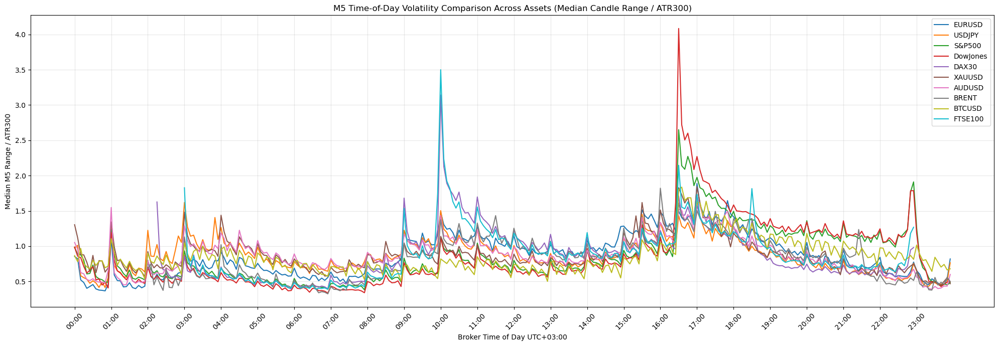

In [ ]:
# %% [markdown]
# ## Run M5 Time-of-Day Comparison Across All Assets

# %%
m5_results = {
    "EURUSD": eurusd_m5,
    "USDJPY": usdjpy_m5,
    "S&P500": SP_m5,
    "DowJones": DowJones_m5,
    "DAX30": DAX30_m5,
    "XAUUSD": XAUUSD_m5,
    "AUDUSD": AUDUSD_m5,
    "BRENT": BRENT_m5,
    "BTCUSD": BTCUSD_m5,
    "FTSE100": FTSE100_m5,
}

m5_tod_volatility_comparison = compare_m5_time_of_day_volatility(
    m5_results=m5_results,
    atr_period=300,
    stat="median",
    plot=True,
)

## Cleaner Grouped M5 Time-of-Day Volatility Charts

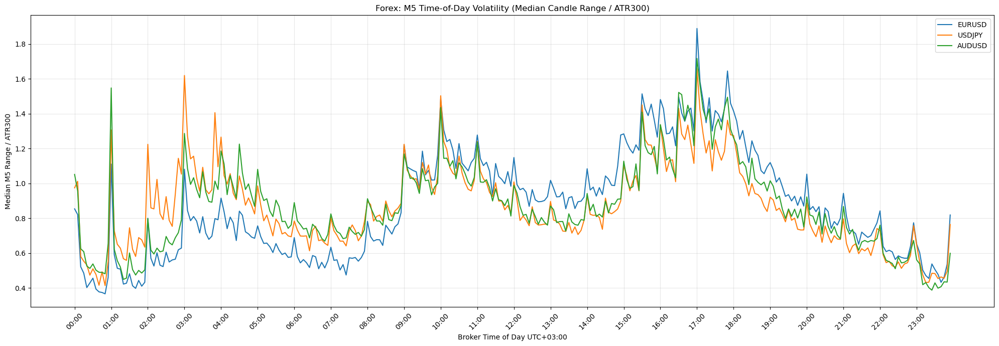

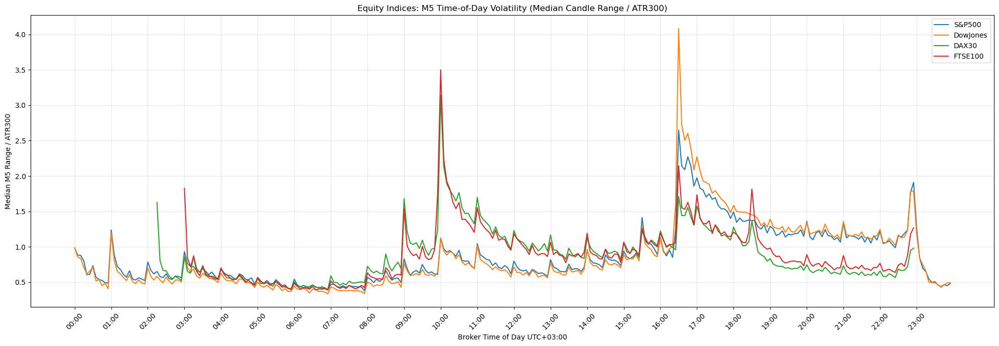

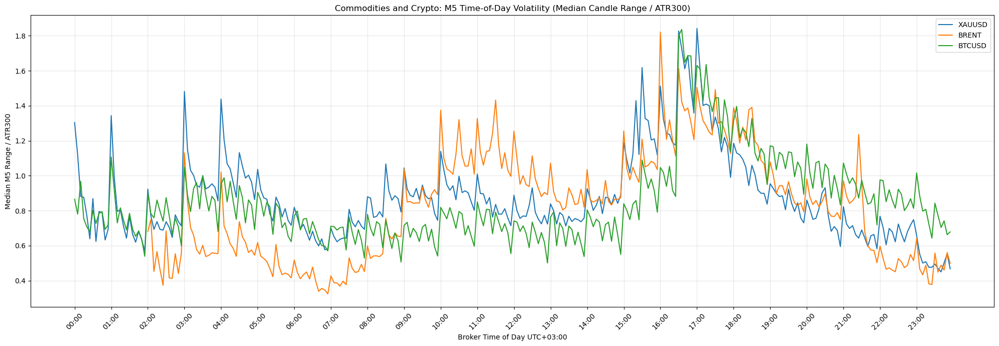

In [36]:
# %% [markdown]
# ## Cleaner Grouped M5 Time-of-Day Volatility Charts

# %%
def plot_m5_time_of_day_volatility_groups(
    comparison_df,
    groups,
    atr_period=300,
    stat="median",
):
    """
    Plot grouped M5 time-of-day volatility comparison charts.
    Useful when too many assets make one chart crowded.
    """
    x = np.arange(len(comparison_df))
    xtick_step = 12

    for group_name, assets in groups.items():
        available_assets = [a for a in assets if a in comparison_df.columns]

        if not available_assets:
            continue

        plt.figure(figsize=(20, 7))

        for asset_name in available_assets:
            plt.plot(
                x,
                comparison_df[asset_name],
                label=asset_name
            )

        plt.xticks(
            x[::xtick_step],
            comparison_df.index[::xtick_step],
            rotation=45
        )

        plt.title(
            f"{group_name}: M5 Time-of-Day Volatility "
            f"({stat.title()} Candle Range / ATR{atr_period})"
        )
        plt.xlabel("Broker Time of Day UTC+03:00")
        plt.ylabel(f"{stat.title()} M5 Range / ATR{atr_period}")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()


m5_volatility_groups = {
    "Forex": ["EURUSD", "USDJPY", "AUDUSD"],
    "Equity Indices": ["S&P500", "DowJones", "DAX30", "FTSE100"],
    "Commodities and Crypto": ["XAUUSD", "BRENT", "BTCUSD"],
}

plot_m5_time_of_day_volatility_groups(
    comparison_df=m5_tod_volatility_comparison,
    groups=m5_volatility_groups,
    atr_period=300,
    stat="median",
)

## Run D1 Day-of-Month Volatility for All Assets

Running D1 day-of-month volatility analysis for EURUSD


,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
day_of_month,,,,,,,,,,,,,,,
1,403,0.007900,0.008328,0.011800,0.01606,0.858471,1.147471,1.451821,0.260286,0.360825,0.639175,0.833517,0.820655,0.820755,0.828307
2,435,0.007700,0.008496,0.011300,0.01690,0.863497,1.116270,1.522611,0.257440,0.382812,0.617188,0.813953,0.805130,0.809319,0.785266
3,437,0.007700,0.008777,0.012200,0.01788,0.891150,1.214615,1.607116,0.233524,0.359375,0.640625,0.840525,0.844900,0.827967,0.799488
4,431,0.007500,0.008627,0.012000,0.01770,0.876508,1.135498,1.540859,0.231686,0.342105,0.657895,0.830923,0.822511,0.809838,0.796337
5,436,0.007700,0.008524,0.011625,0.01655,0.882818,1.128841,1.594433,0.215877,0.325558,0.674442,0.820063,0.818729,0.783215,0.801455
6,439,0.007700,0.008336,0.011750,0.01672,0.861534,1.158465,1.524307,0.263471,0.386792,0.613208,0.844961,0.826419,0.815264,0.815336
7,435,0.007300,0.008149,0.011200,0.01506,0.828647,1.099456,1.508051,0.237763,0.336957,0.663043,0.811408,0.807018,0.784314,0.767696
8,443,0.007300,0.008182,0.011000,0.01620,0.831148,1.083191,1.451847,0.224244,0.358491,0.641509,0.806061,0.790043,0.771273,0.730095
9,435,0.007200,0.008483,0.011500,0.01726,0.859787,1.107375,1.605170,0.213522,0.333333,0.666667,0.789436,0.773015,0.769466,0.768302


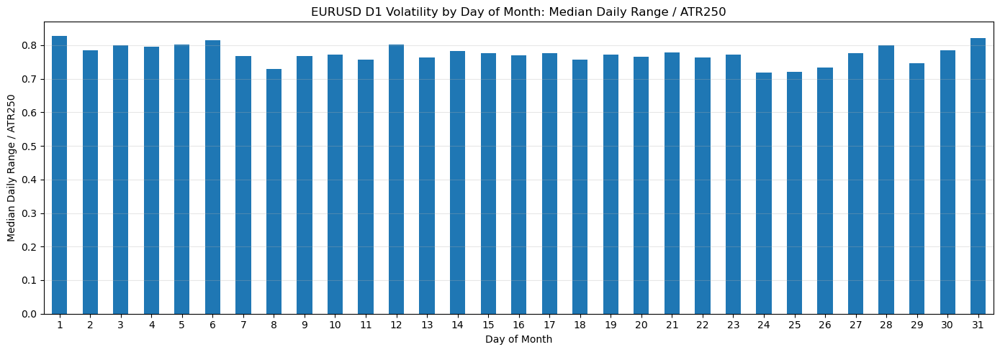

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\2803532151.py:135: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


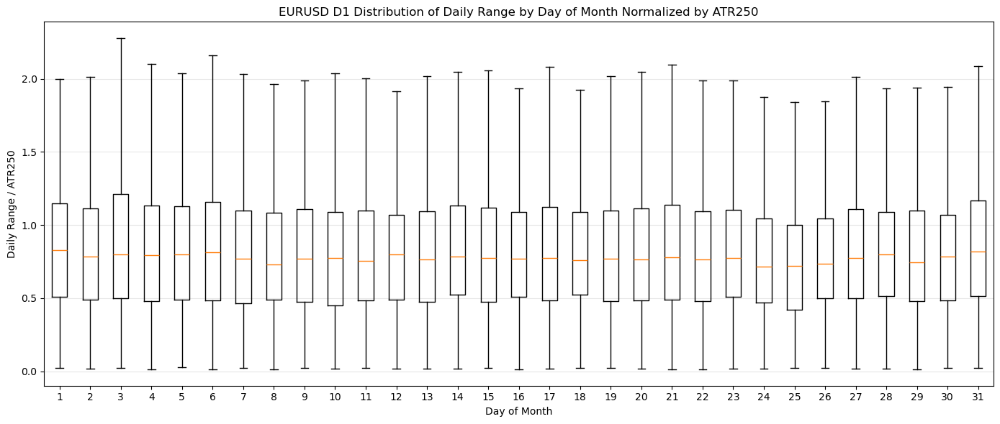

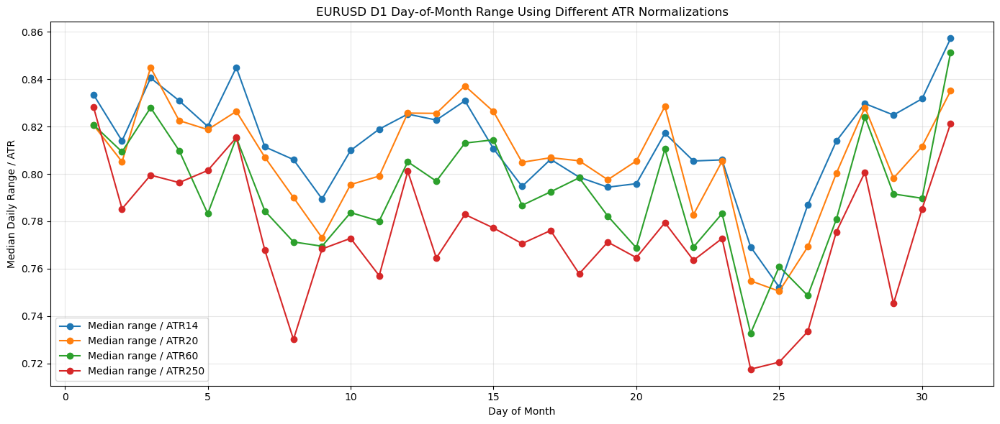

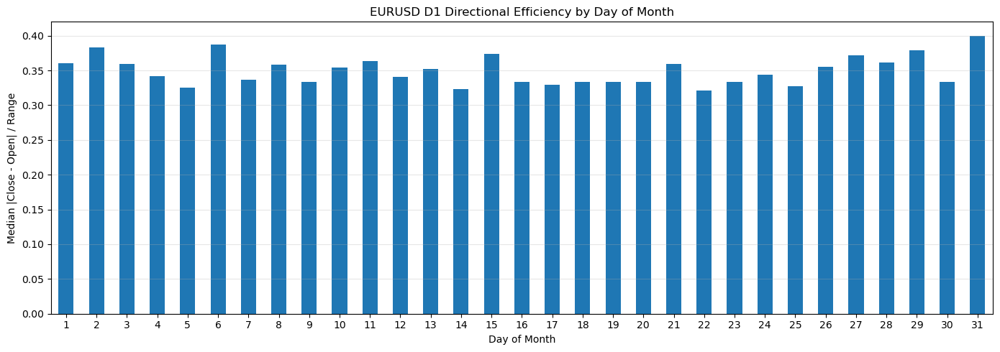

Running D1 day-of-month volatility analysis for USDJPY


,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
day_of_month,,,,,,,,,,,,,,,
1,321,0.990,1.101199,1.35000,1.8330,1.017986,1.184133,1.675924,0.384280,0.447619,0.552381,0.943820,0.946837,0.901700,0.912307
2,339,1.000,1.118398,1.35000,1.8000,1.022257,1.229138,1.554121,0.390691,0.477833,0.522167,0.966072,0.939794,0.926309,0.916954
3,337,0.980,1.123139,1.40000,1.8140,1.035570,1.241736,1.619225,0.401271,0.458333,0.541667,0.957265,0.947090,0.965618,0.944351
4,338,0.965,1.086571,1.31500,1.8500,0.991766,1.208261,1.606149,0.369258,0.465020,0.534980,0.911620,0.901127,0.910223,0.886954
5,338,0.985,1.128003,1.40750,1.9100,1.031626,1.256125,1.583257,0.442710,0.493363,0.506637,0.978185,0.964374,0.905990,0.922697
6,340,0.950,1.105515,1.39000,1.8310,1.019485,1.217750,1.723056,0.372366,0.480385,0.519615,0.911392,0.899233,0.877606,0.878029
7,337,0.970,1.192926,1.42000,2.0262,1.076217,1.250252,1.719139,0.377872,0.476190,0.523810,0.965517,0.956790,0.941542,0.937136
8,337,0.970,1.124955,1.33000,1.8340,1.026882,1.235950,1.634359,0.418388,0.463415,0.536585,0.936170,0.941001,0.919181,0.891004
9,338,0.920,1.161775,1.35000,2.1430,1.056944,1.205683,1.869458,0.364299,0.445363,0.554637,0.908477,0.898449,0.884161,0.859510


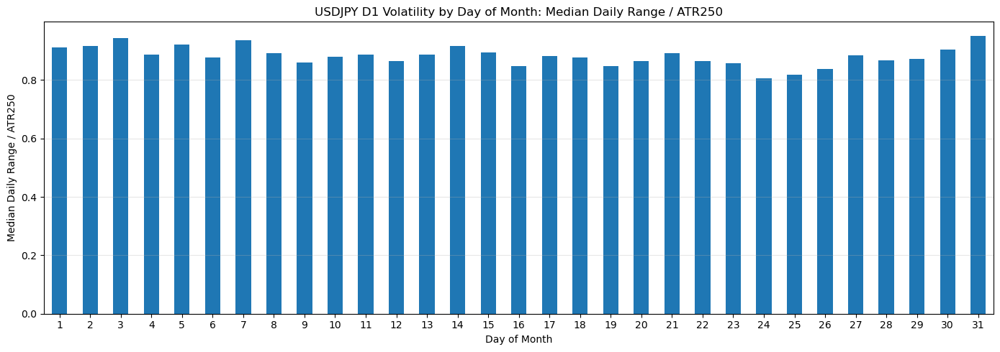

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\2803532151.py:135: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


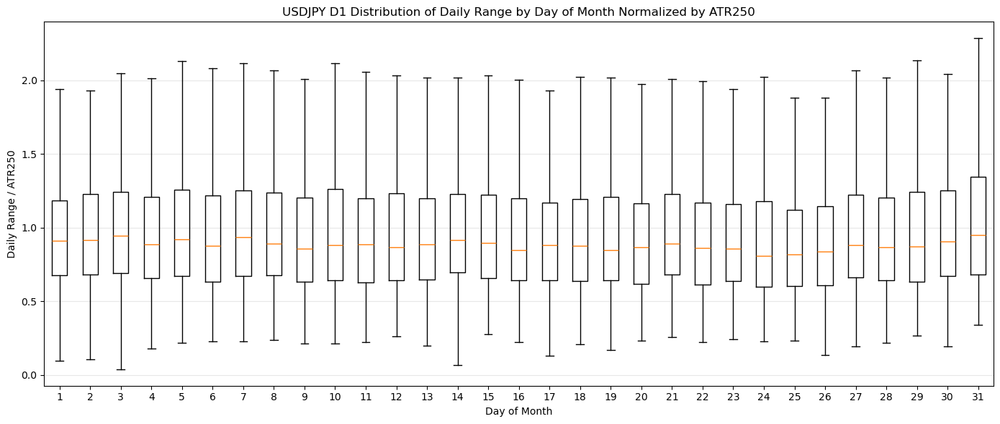

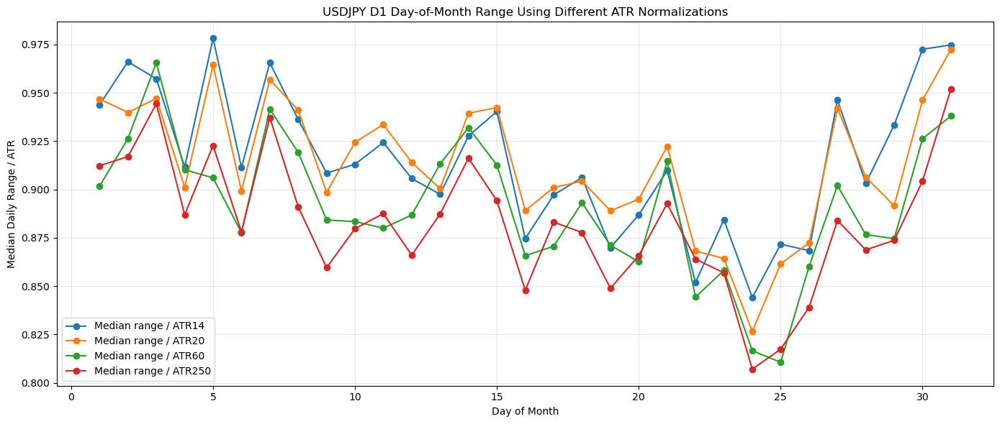

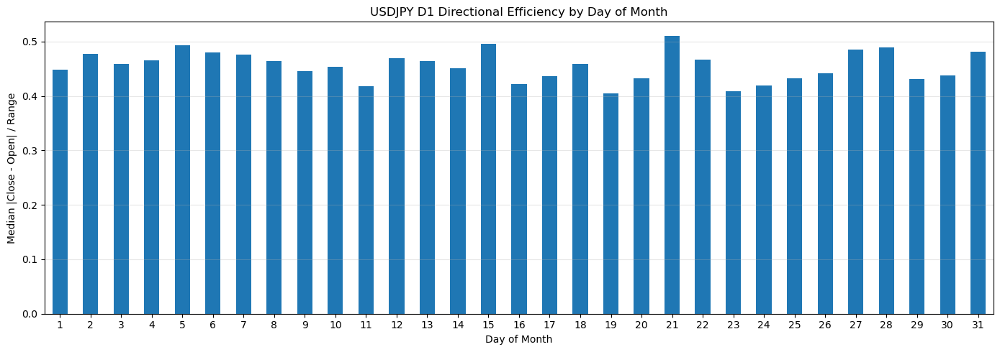

Running D1 day-of-month volatility analysis for S&P500


,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
day_of_month,,,,,,,,,,,,,,,
1,73,50.80,57.631507,80.000,103.94,1.139052,1.358609,1.907687,0.385180,0.500883,0.499117,0.974967,0.887007,0.865754,0.883460
2,78,60.10,64.956410,80.175,120.21,1.262799,1.483744,1.986576,0.491308,0.437176,0.562824,1.064860,1.103936,1.087356,1.020585
3,81,45.60,58.230864,78.800,124.70,1.098033,1.367020,1.902088,0.415695,0.478384,0.521616,0.956552,0.940666,0.935801,0.953704
4,80,52.20,61.508750,90.150,120.83,1.178096,1.426488,2.234985,0.474549,0.480952,0.519048,1.007657,0.967600,0.923212,0.946151
5,81,49.40,58.718519,84.800,112.60,1.206535,1.410197,1.776087,0.462821,0.560261,0.439739,1.045089,0.987099,0.928178,0.984582
6,83,51.70,60.367470,88.100,118.10,1.223357,1.318015,2.190033,0.471470,0.485597,0.514403,1.005988,0.993426,0.925243,0.935643
7,80,50.20,61.222500,81.000,109.55,1.154085,1.267894,2.187010,0.423753,0.484433,0.515567,0.957927,0.956226,0.921162,0.959696
8,80,40.85,52.721250,59.675,90.02,1.020326,1.017675,1.869656,0.329936,0.429338,0.570662,0.835529,0.775368,0.714148,0.731718
9,80,45.70,61.990000,67.550,111.33,1.176117,1.305494,2.011120,0.383919,0.483240,0.516760,0.930859,0.935008,0.879700,0.872050


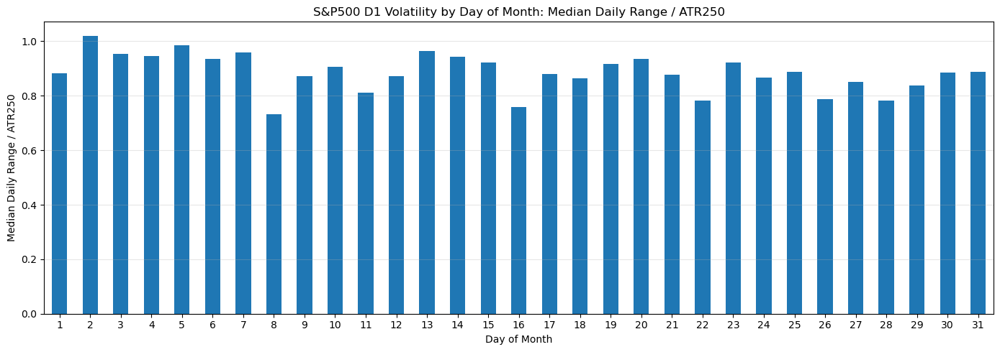

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\2803532151.py:135: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


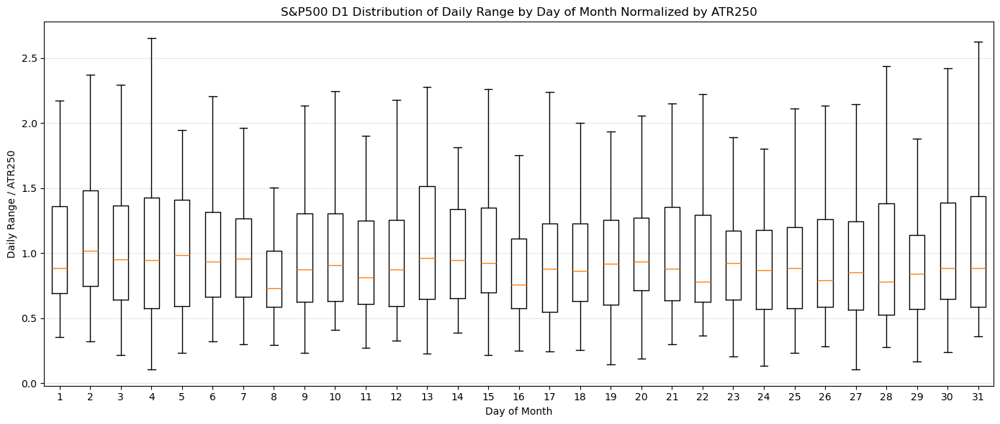

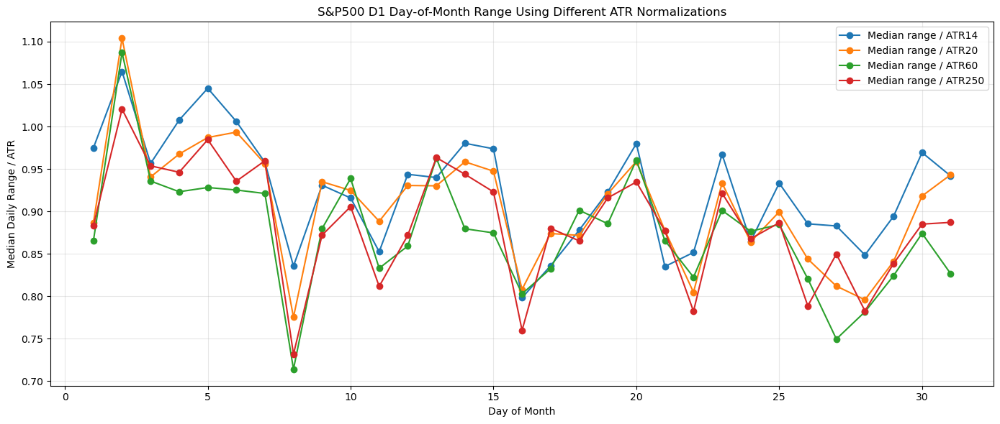

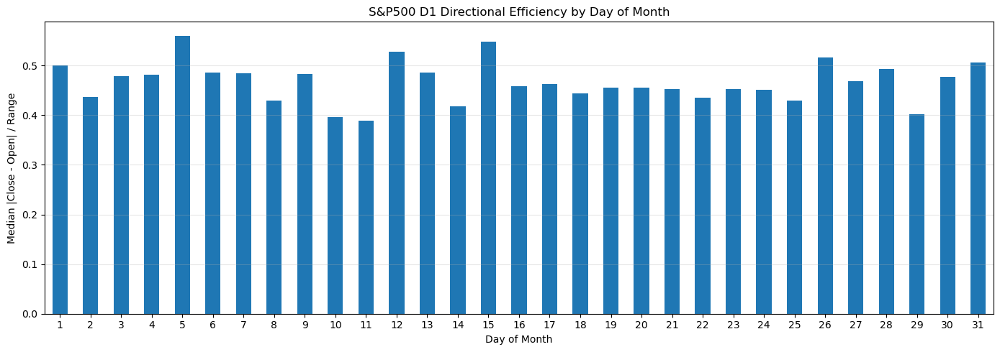

Running D1 day-of-month volatility analysis for DowJones


,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
day_of_month,,,,,,,,,,,,,,,
1,73,414.0,447.726027,544.00,742.4,1.151202,1.288314,2.293527,0.466433,0.468254,0.531746,1.001917,0.991988,0.917180,0.933836
2,78,430.0,497.551282,675.25,861.3,1.258314,1.503596,1.934987,0.409618,0.499606,0.500394,1.111820,1.102469,1.096631,1.016713
3,81,406.0,447.864198,543.00,759.0,1.091970,1.317292,1.929438,0.453896,0.485294,0.514706,0.994157,0.909759,0.949470,0.941730
4,80,389.5,471.250000,561.50,925.3,1.158541,1.435665,2.277847,0.421107,0.480489,0.519511,0.972873,0.947174,1.003962,0.918398
5,81,384.0,462.160494,572.00,904.0,1.245056,1.480205,2.001421,0.462180,0.501992,0.498008,1.041261,0.992277,0.876373,0.931645
6,83,381.0,485.084337,629.50,822.6,1.262427,1.239958,2.140821,0.401639,0.470120,0.529880,0.940729,0.947089,0.924912,0.981415
7,80,397.5,463.487500,614.25,731.7,1.142211,1.266905,1.927739,0.382604,0.440150,0.559850,0.980929,1.013101,0.961101,0.991905
8,80,314.0,410.400000,457.00,760.3,1.026766,1.082572,1.553764,0.280703,0.354952,0.645048,0.831671,0.797880,0.723096,0.819844
9,80,357.5,476.837500,496.75,855.7,1.171479,1.264297,1.917380,0.411890,0.458329,0.541671,0.888989,0.890474,0.867879,0.857615


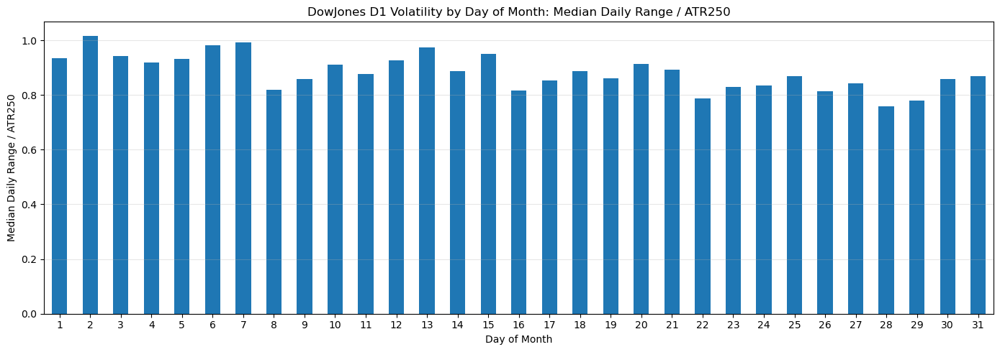

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\2803532151.py:135: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


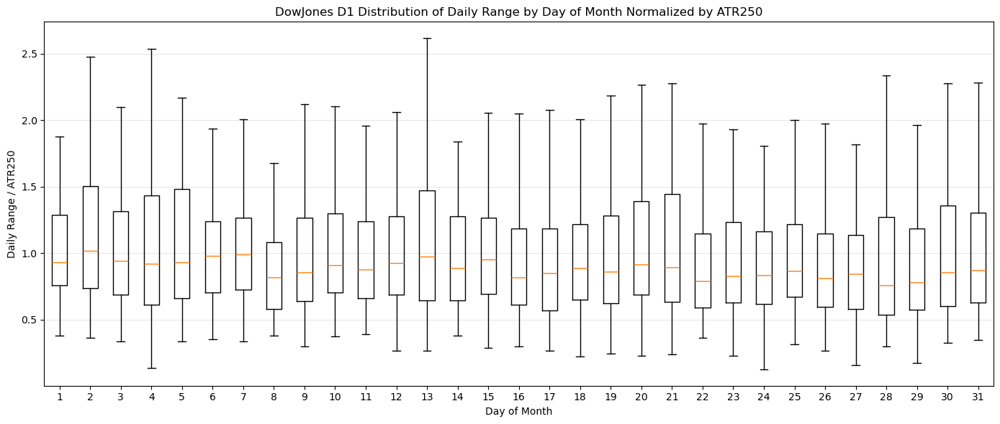

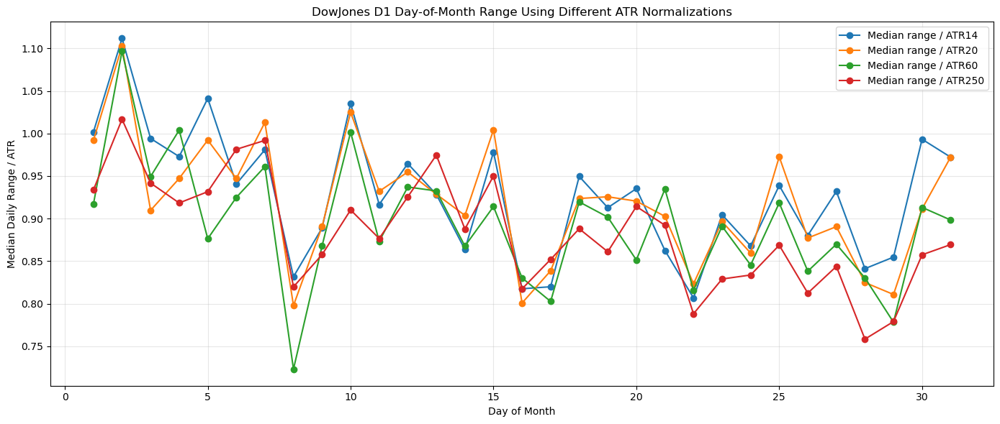

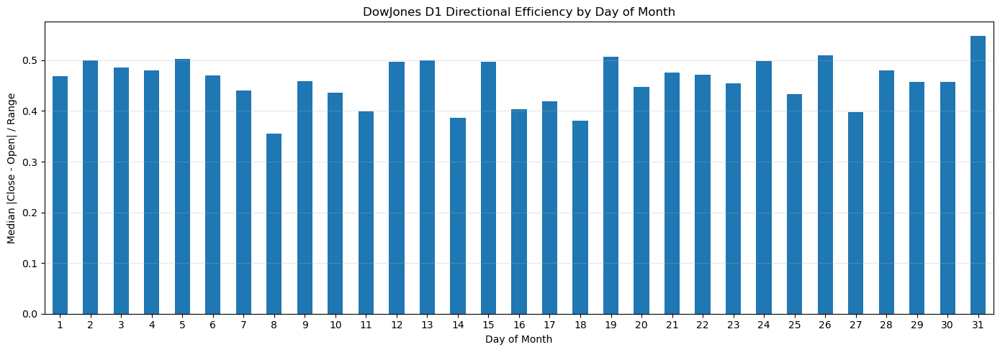

Running D1 day-of-month volatility analysis for DAX30


,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
day_of_month,,,,,,,,,,,,,,,
1,25,227.40,277.280000,359.500,472.72,1.102795,1.268065,1.626202,0.574031,0.530233,0.469767,1.043379,1.007503,1.043195,1.031257
2,33,293.90,318.036364,376.000,483.80,1.236531,1.634285,1.876303,0.687427,0.570058,0.429942,1.128788,1.092753,1.130824,1.121047
3,32,208.75,291.378125,336.025,475.88,1.150765,1.361583,1.923589,0.329991,0.399381,0.600619,0.950090,0.969507,0.986807,1.008737
4,33,226.40,298.909091,329.500,536.68,1.152109,1.302955,1.594082,0.424784,0.510601,0.489399,1.016271,0.973297,0.925342,1.010070
5,35,204.50,273.902857,329.400,552.02,1.066429,1.226444,1.817315,0.463479,0.532383,0.467617,0.940941,0.936986,0.894371,0.855808
6,34,232.50,284.641176,351.850,568.16,1.121848,1.645542,1.903579,0.480812,0.519297,0.480703,1.008490,0.985358,1.063404,0.974707
7,32,249.25,326.884375,345.575,481.11,1.280858,1.432277,1.786467,0.439830,0.477263,0.522737,0.983878,0.963050,1.010050,1.030807
8,33,213.10,248.984848,269.500,349.90,1.008594,1.135164,1.447674,0.394374,0.446027,0.553973,0.881254,0.900221,0.893315,0.854106
9,33,203.90,298.869697,263.900,334.28,1.126870,0.965778,1.444621,0.328060,0.460602,0.539398,0.877193,0.886386,0.804506,0.754808


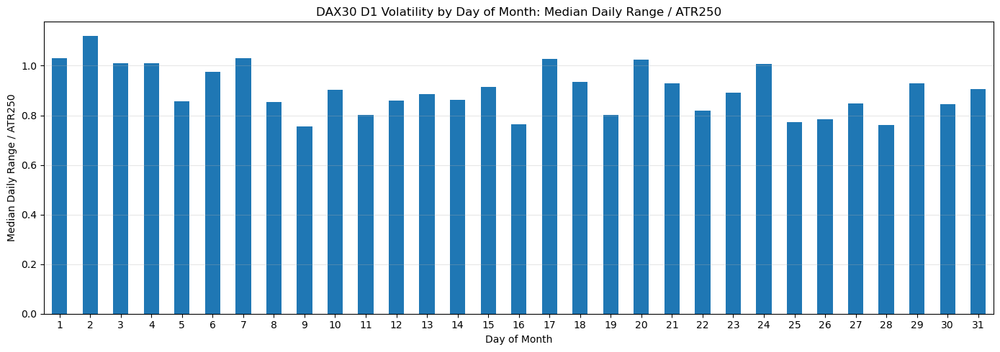

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\2803532151.py:135: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


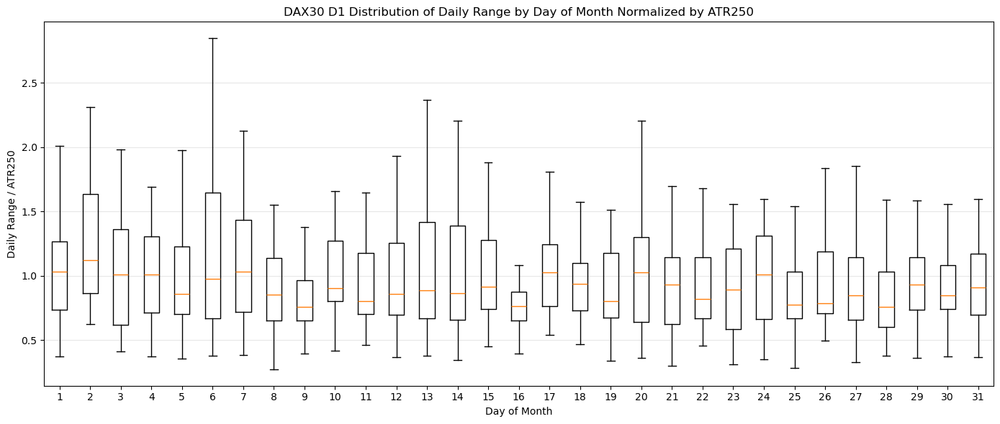

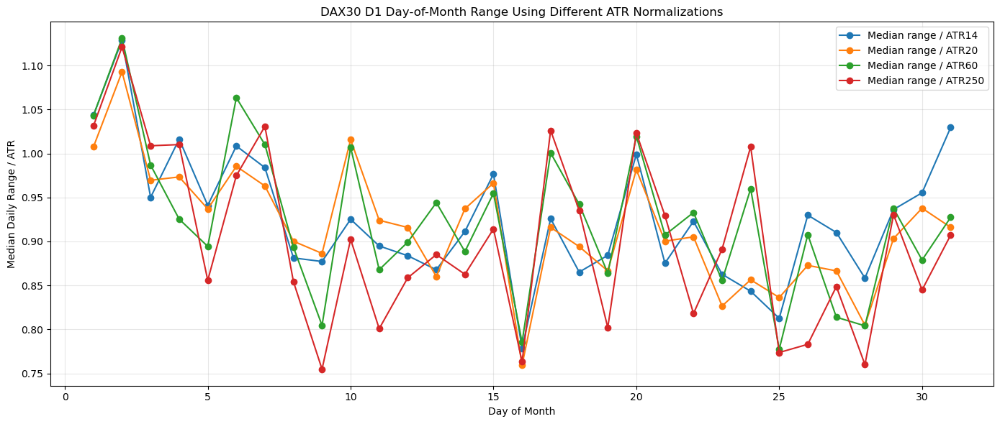

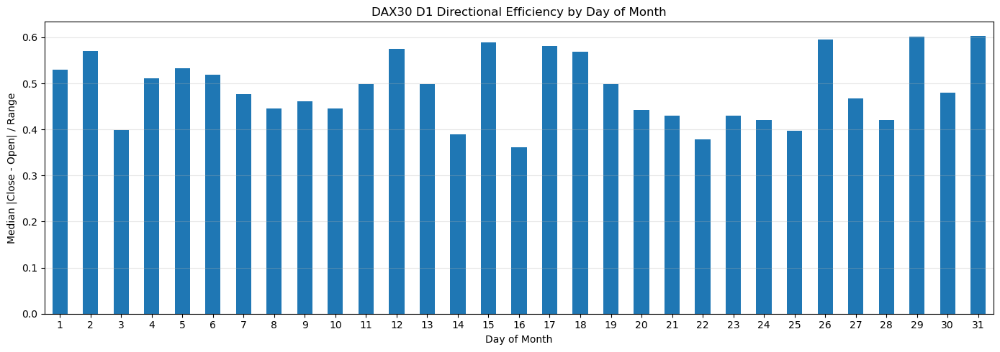

Running D1 day-of-month volatility analysis for XAUUSD


,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
day_of_month,,,,,,,,,,,,,,,
1,110,21.870,27.429091,33.1050,48.864,1.132882,1.340010,1.792229,0.343783,0.425570,0.574430,1.013769,1.009344,0.985129,0.992656
2,119,21.360,31.811597,32.4100,45.456,1.142328,1.409334,1.850827,0.437222,0.440559,0.559441,0.980183,0.942498,0.967468,0.999007
3,122,23.080,31.063443,31.8650,44.381,1.172613,1.389943,1.736195,0.526683,0.534145,0.465855,1.076426,1.065091,1.062362,1.104918
4,123,20.600,27.844390,31.8150,46.010,1.077172,1.267573,1.773318,0.297896,0.352041,0.647959,0.956040,0.955712,0.936011,0.940589
5,124,21.950,28.997419,32.3200,50.082,1.128475,1.342542,1.909297,0.380091,0.423546,0.576454,0.962398,0.940205,0.923218,0.948721
6,125,20.540,29.660320,33.2100,48.656,1.095131,1.309987,1.686826,0.435090,0.507824,0.492176,0.963599,0.951409,0.982181,0.980107
7,120,19.830,25.222167,29.4300,47.136,1.038209,1.233707,1.669614,0.394057,0.427820,0.572180,0.871365,0.877614,0.887538,0.915622
8,122,18.635,26.003689,30.0200,48.187,1.050727,1.248560,1.610657,0.344297,0.408904,0.591096,0.925796,0.922169,0.909073,0.887932
9,123,17.580,26.935854,26.9150,49.330,1.031721,1.160172,1.559726,0.332457,0.406393,0.593607,0.833448,0.829052,0.839530,0.857152


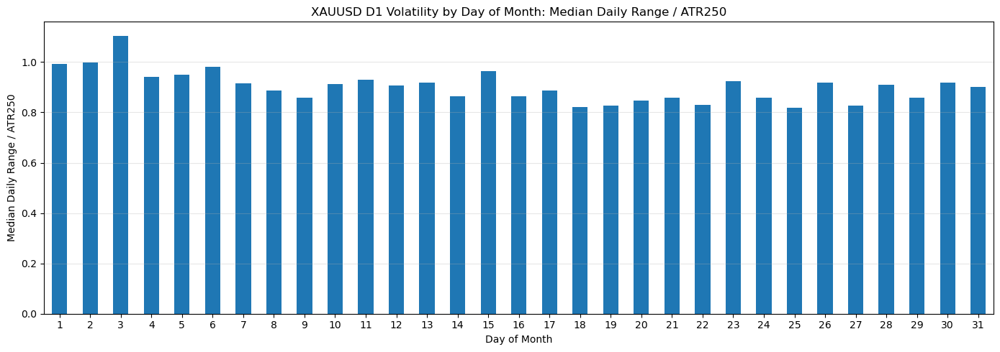

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\2803532151.py:135: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


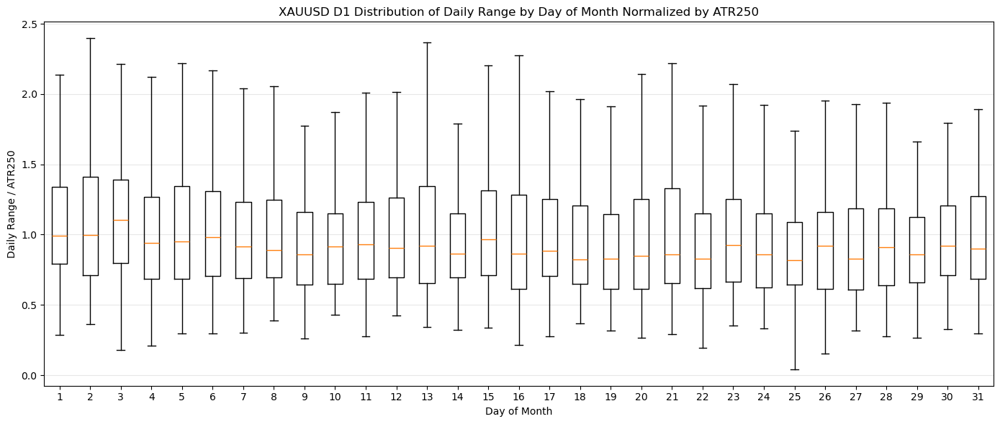

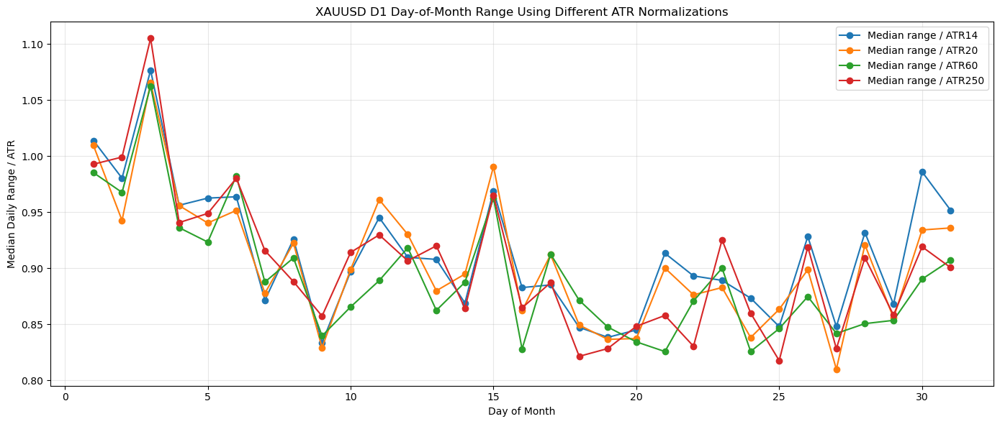

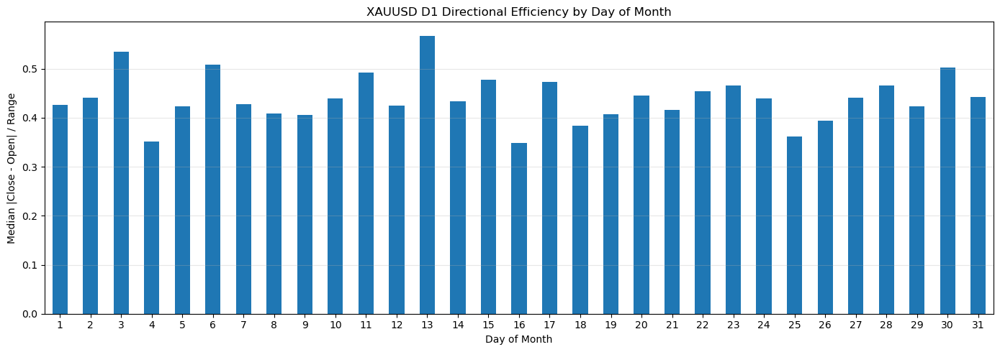

Running D1 day-of-month volatility analysis for AUDUSD


,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
day_of_month,,,,,,,,,,,,,,,
1,255,0.007300,0.008087,0.009800,0.013900,1.003811,1.184961,1.450871,0.381470,0.458824,0.541176,0.958904,0.948396,0.927430,0.952944
2,275,0.007000,0.008053,0.010000,0.012960,1.011288,1.221302,1.545169,0.411936,0.458333,0.541667,0.972421,0.949058,0.942134,0.920006
3,275,0.007200,0.008740,0.010400,0.014976,1.115103,1.310701,1.656955,0.474195,0.516129,0.483871,0.998770,0.997766,0.978690,0.991231
4,274,0.007300,0.008611,0.010000,0.014670,1.075389,1.300877,1.654889,0.431811,0.478273,0.521727,0.999965,0.995350,0.998465,0.979423
5,276,0.007000,0.007929,0.009425,0.013750,1.010402,1.221916,1.530100,0.350688,0.418605,0.581395,0.964372,0.935649,0.931280,0.920769
6,277,0.007300,0.008440,0.010100,0.013140,1.058170,1.263894,1.556895,0.471698,0.484139,0.515861,0.972021,0.964086,0.938375,0.956798
7,274,0.007400,0.008087,0.009500,0.012680,1.029263,1.193321,1.583978,0.412353,0.440228,0.559772,0.987674,0.979470,0.955797,0.937027
8,274,0.006850,0.008184,0.009400,0.012870,1.012337,1.139769,1.516789,0.374777,0.452625,0.547375,0.933037,0.924859,0.909009,0.882692
9,275,0.006800,0.008302,0.010000,0.013980,1.042321,1.258517,1.591761,0.360940,0.435897,0.564103,0.937409,0.919540,0.909912,0.884124


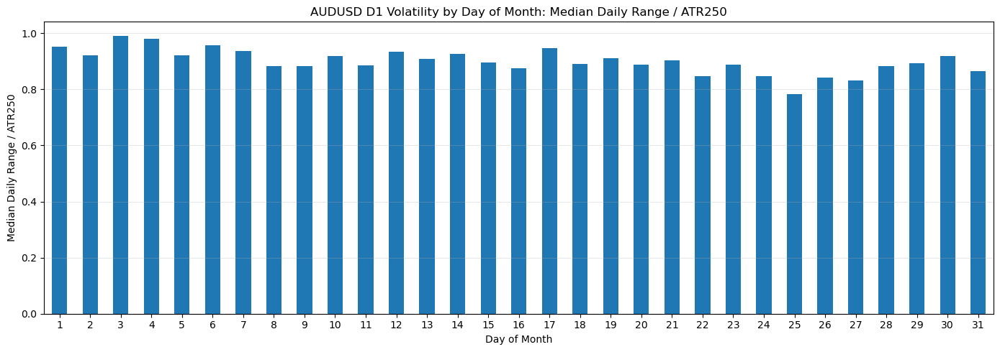

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\2803532151.py:135: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


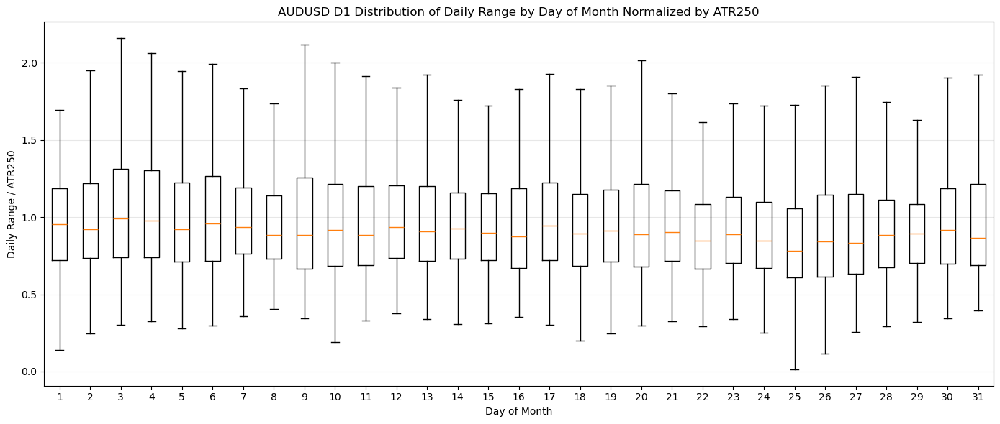

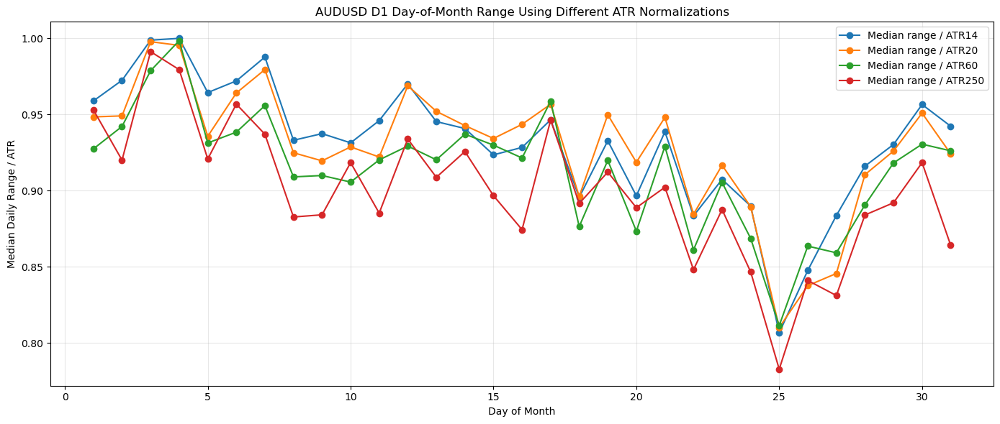

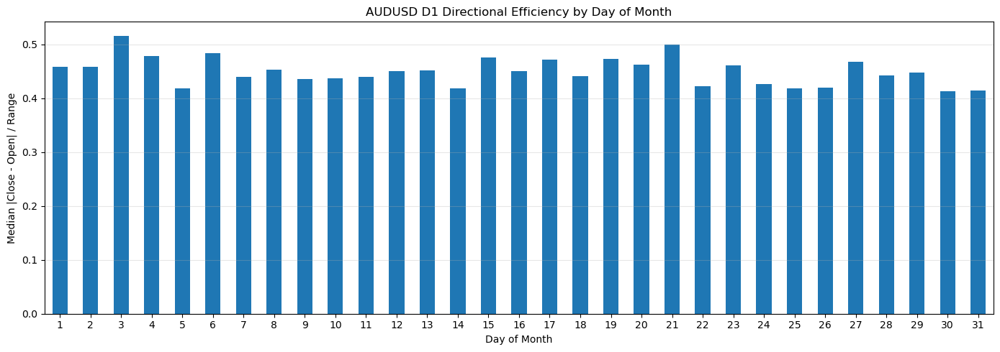

Running D1 day-of-month volatility analysis for BRENT


,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
day_of_month,,,,,,,,,,,,,,,
1,73,2.020,2.422055,2.7400,4.218,1.155463,1.352079,1.675923,0.542586,0.546053,0.453947,1.054477,1.019920,1.008403,1.060948
2,77,1.880,2.410390,2.5400,4.232,1.181716,1.322435,1.854500,0.491360,0.466321,0.533679,1.035320,1.026482,0.997720,0.976980
3,80,1.845,2.370250,3.0750,3.951,1.142994,1.347346,1.749703,0.392217,0.467755,0.532245,1.036882,1.054583,1.003783,0.985717
4,80,1.970,2.358375,2.6850,4.366,1.138025,1.368824,1.829809,0.417156,0.493396,0.506604,0.992178,0.987990,0.948699,0.995312
5,81,1.830,2.240741,2.6600,3.310,1.077034,1.307190,1.633987,0.470079,0.493151,0.506849,0.988599,0.939722,0.958188,0.973550
6,82,2.005,2.430854,2.6125,3.577,1.176542,1.421565,1.734632,0.396465,0.403097,0.596903,0.992716,1.015816,1.012774,0.969411
7,77,1.710,2.368701,2.6400,4.544,1.113564,1.309299,1.978944,0.407476,0.432692,0.567308,0.896437,0.896337,0.870032,0.879696
8,79,1.860,2.255443,2.9050,3.654,1.086386,1.237244,1.911187,0.467111,0.538462,0.461538,0.906149,0.929319,0.871614,0.969414
9,80,1.670,2.741125,2.3225,3.494,1.317968,1.217478,1.790503,0.356439,0.465546,0.534454,0.883991,0.926781,0.870121,0.786540


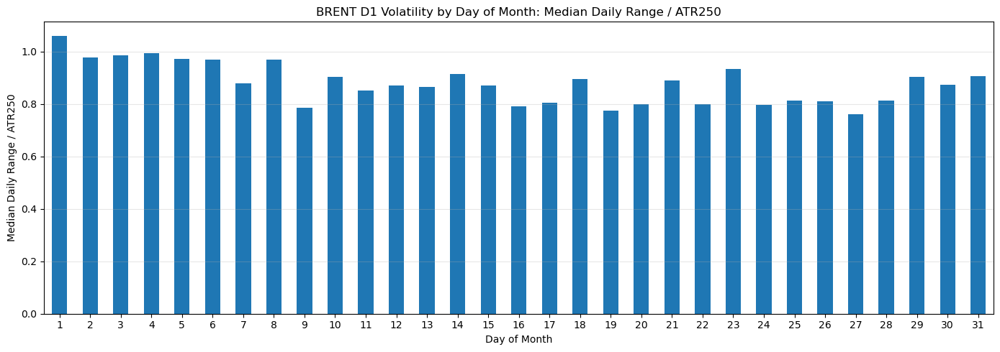

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\2803532151.py:135: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


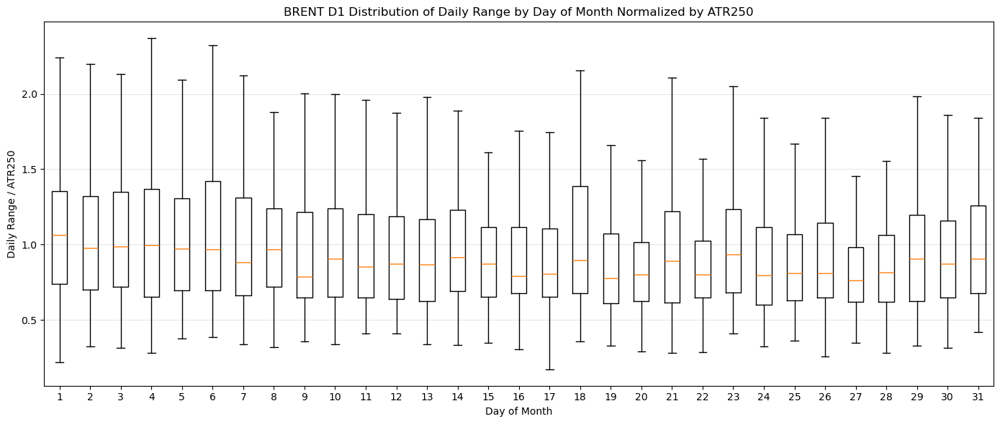

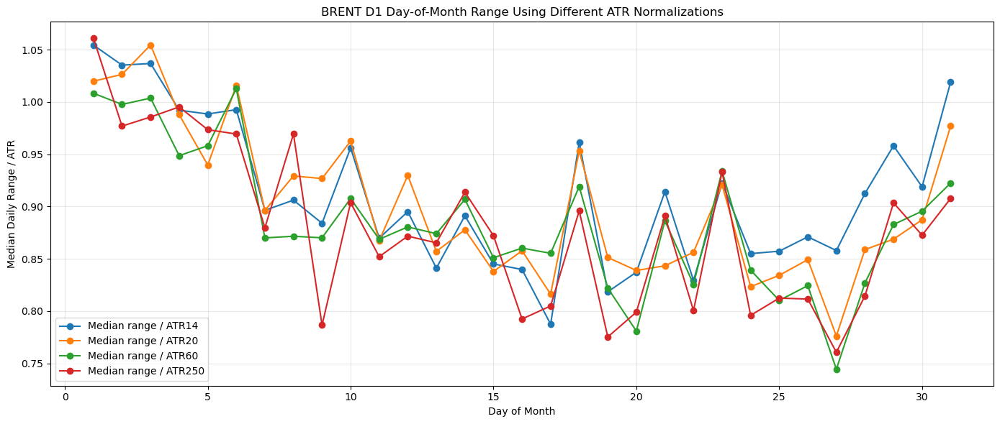

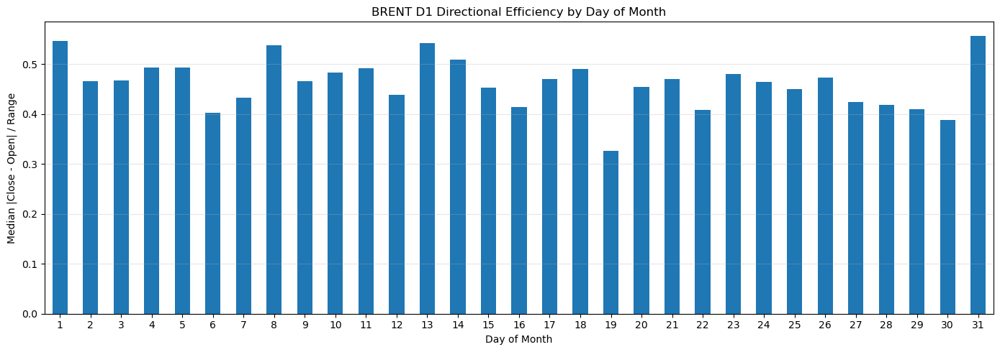

Running D1 day-of-month volatility analysis for BTCUSD


,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
day_of_month,,,,,,,,,,,,,,,
1,115,362.0,1105.243478,1846.50,2931.8,1.354537,1.562747,2.854847,0.357859,0.491099,0.508901,1.015690,0.952381,0.910591,0.961538
2,114,462.0,1121.219298,1616.25,3359.6,1.504886,1.687391,2.802383,0.384400,0.451304,0.548696,1.009544,0.986566,0.940366,0.901898
3,116,427.5,1199.758621,1676.50,3002.0,1.505426,1.597718,2.825694,0.316168,0.418443,0.581557,0.894627,0.896795,0.888897,0.956824
4,117,420.0,1298.521368,2323.00,3861.6,1.579366,1.702011,3.087787,0.429038,0.466667,0.533333,0.958993,0.979021,0.967998,0.968992
5,116,422.0,1431.258621,2146.75,4198.5,1.693139,1.954072,3.111969,0.394429,0.473323,0.526677,0.945201,0.965701,0.867108,0.916253
6,117,349.0,1268.085470,1685.00,3564.8,1.451850,1.546095,3.119314,0.363548,0.412533,0.587467,0.994536,0.993116,0.939281,0.911458
7,113,449.0,1215.053097,1864.00,3300.2,1.470087,1.546346,2.360119,0.367018,0.460513,0.539487,0.955631,0.965814,0.910747,0.958561
8,115,514.0,1221.939130,1754.50,3730.4,1.625689,1.746817,3.382633,0.398470,0.424901,0.575099,1.017301,0.973541,0.936813,0.977981
9,116,451.0,1243.000000,2105.75,3765.0,1.493054,1.728825,2.620643,0.476162,0.451709,0.548291,1.010041,0.961867,1.020521,0.986852


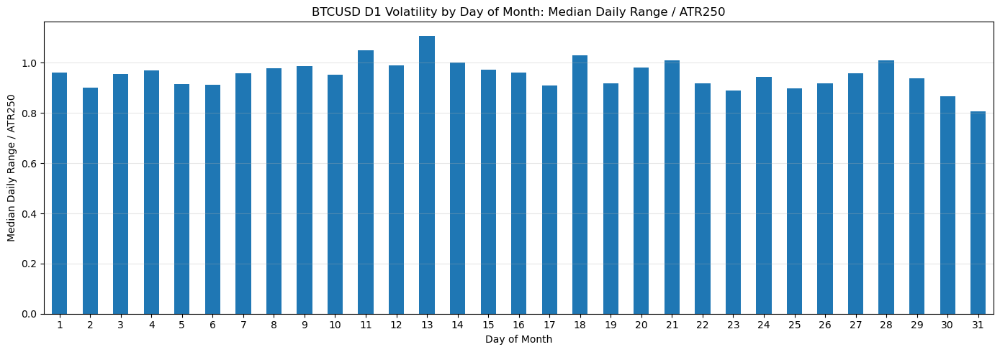

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\2803532151.py:135: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


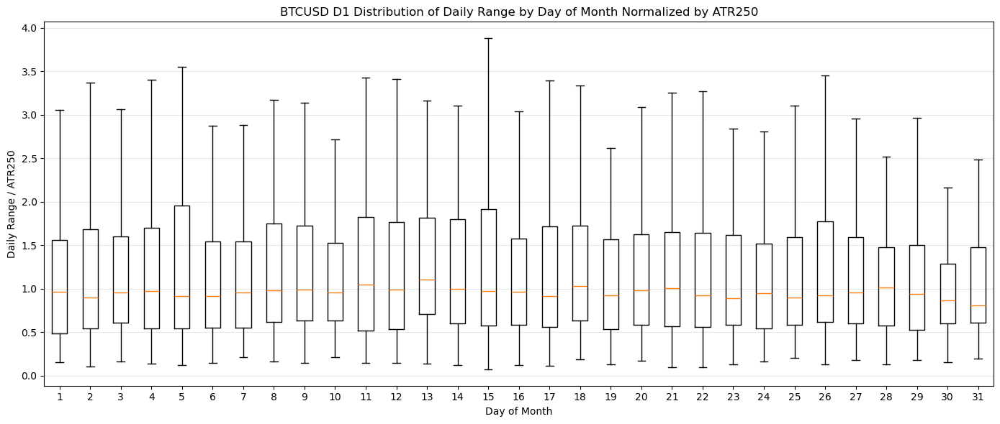

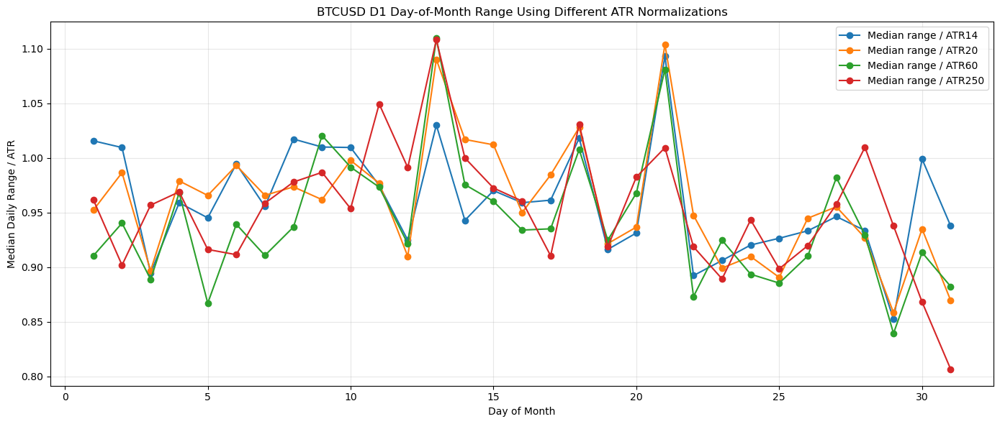

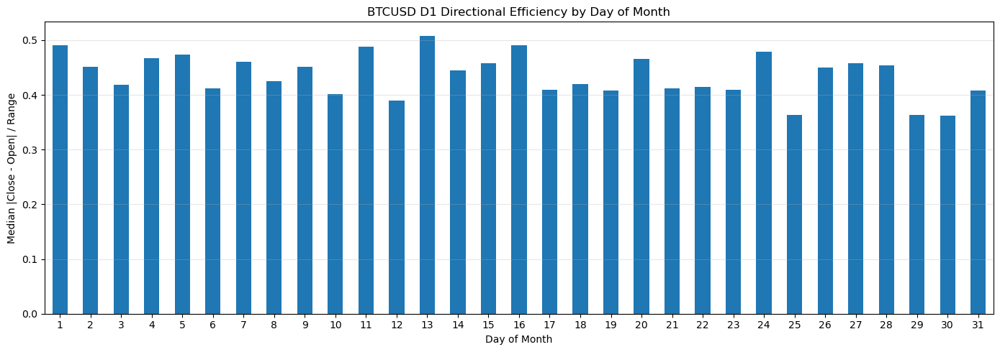

Running D1 day-of-month volatility analysis for FTSE100


,candles,median_range_raw,mean_range_raw,p75_range_raw,p90_range_raw,mean_range_atr250,p75_range_atr250,p90_range_atr250,median_body_atr250,median_directional_efficiency,median_wick_ratio,median_range_atr14,median_range_atr20,median_range_atr60,median_range_atr250
day_of_month,,,,,,,,,,,,,,,
1,59,88.00,95.418644,119.500,139.20,0.985922,1.113518,1.409950,0.448581,0.469298,0.530702,0.924707,0.925403,0.922932,0.959992
2,64,95.65,106.614062,129.075,166.74,1.129570,1.409582,1.854763,0.402175,0.475919,0.524081,1.038204,1.045630,1.035585,0.940030
3,65,87.80,104.652308,126.300,165.64,1.101219,1.294485,1.668930,0.422367,0.447981,0.552019,0.958638,0.996867,0.961257,0.980212
4,66,84.70,106.704545,120.700,191.25,1.126220,1.288286,1.841501,0.414309,0.387488,0.612512,0.949075,0.950516,0.939400,0.940924
5,66,81.60,100.150000,108.250,166.75,1.069914,1.254800,1.772978,0.390437,0.443064,0.556936,0.940948,0.923404,0.911272,0.895424
6,64,89.40,106.417188,129.875,179.52,1.119033,1.303562,1.955136,0.487087,0.575998,0.424002,1.016355,0.989335,0.983440,0.910348
7,66,78.95,98.507576,98.325,161.60,1.035485,1.095772,1.660186,0.419247,0.445233,0.554767,0.901702,0.921392,0.850142,0.835293
8,65,76.00,87.024615,100.500,123.86,0.919974,1.035769,1.447036,0.266872,0.341847,0.658153,0.850413,0.832979,0.778774,0.795781
9,65,71.50,104.723077,107.400,195.54,1.076778,1.157607,1.674001,0.423103,0.543478,0.456522,0.874322,0.873385,0.857143,0.810016


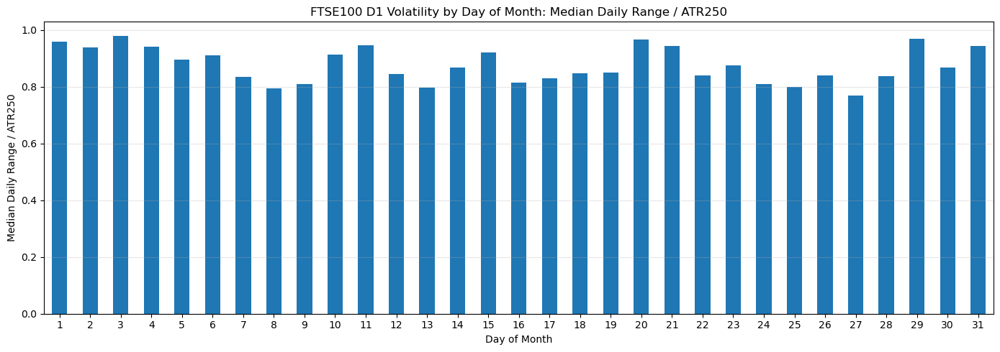

C:\Users\amirj\AppData\Local\Temp\ipykernel_14796\2803532151.py:135: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


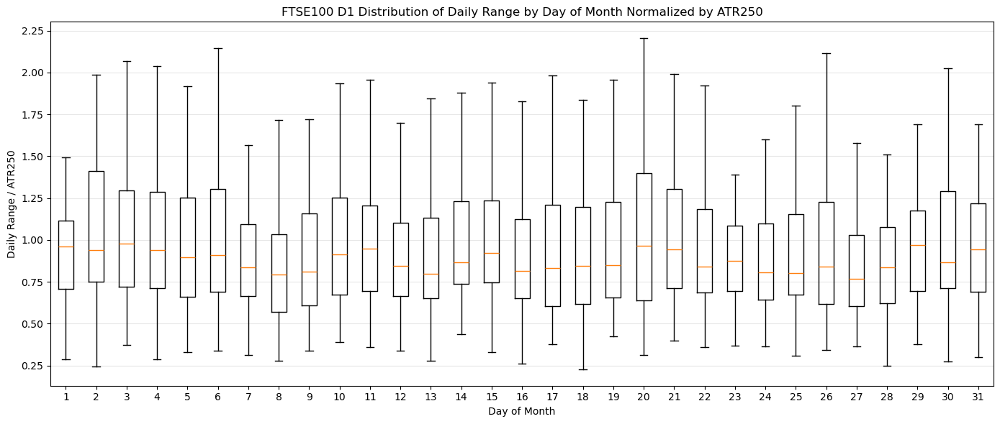

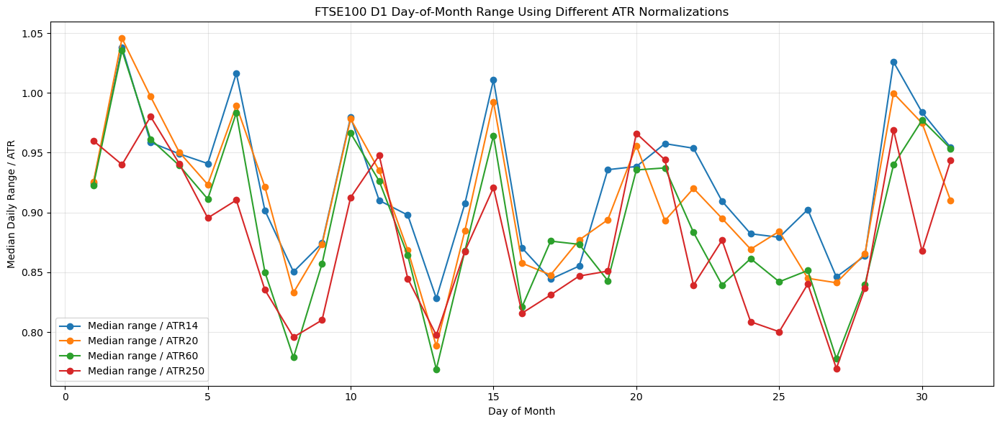

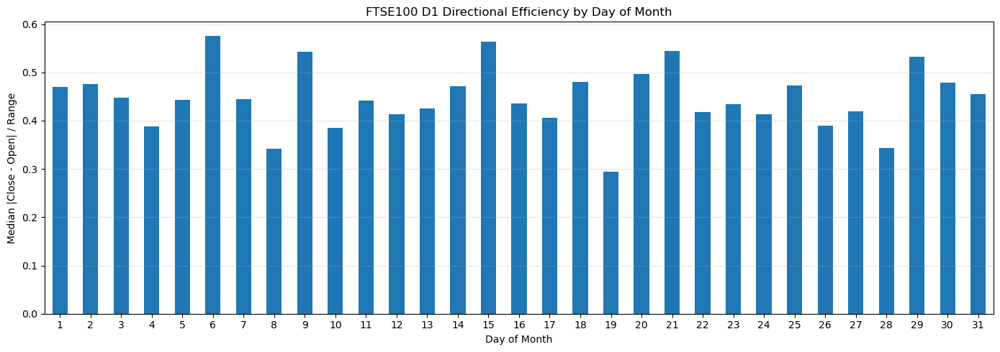

In [ ]:
# %% [markdown]
# ## Run D1 Day-of-Month Volatility for All Assets

# %%
day_of_month_results = {}

day_of_month_assets = {
    "EURUSD": r"mt5_data\EURUSDzero_D1_max_bars.csv",
    "USDJPY": r"mt5_data\USDJPYzero_D1_max_bars.csv",
    "S&P500": r"mt5_data\SP500_D1_max_bars.csv",
    "DowJones": r"mt5_data\DowJones30_D1_max_bars.csv",
    "DAX30": r"mt5_data\DAX30_D1_max_bars.csv",
    "XAUUSD": r"mt5_data\XAUUSDzero_D1_max_bars.csv",
    "AUDUSD": r"mt5_data\AUDUSDzero_D1_max_bars.csv",
    "BRENT": r"mt5_data\BRENT_D1_max_bars.csv",
    "BTCUSD": r"mt5_data\BTCUSD_D1_max_bars.csv",
    "FTSE100": r"mt5_data\FTSE100_D1_max_bars.csv",
}

for asset_name, csv_path in day_of_month_assets.items():
    print("=" * 80)
    print(f"Running D1 day-of-month volatility analysis for {asset_name}")
    print("=" * 80)

    day_of_month_results[asset_name] = analyze_d1_day_of_month_csv(
        csv_path=csv_path,
        asset_name=asset_name,
        atr_periods=[14, 20, 60, 250],
        structural_atr=250,
        min_candles_per_day=10,
        plot=True,
    )

## Compare Day-of-Month Volatility Across Assets

,EURUSD,USDJPY,S&P500,DowJones,DAX30,XAUUSD,AUDUSD,BRENT,BTCUSD,FTSE100
day_of_month,,,,,,,,,,
1,0.828307,0.912307,0.883460,0.933836,1.031257,0.992656,0.952944,1.060948,0.961538,0.959992
2,0.785266,0.916954,1.020585,1.016713,1.121047,0.999007,0.920006,0.976980,0.901898,0.940030
3,0.799488,0.944351,0.953704,0.941730,1.008737,1.104918,0.991231,0.985717,0.956824,0.980212
4,0.796337,0.886954,0.946151,0.918398,1.010070,0.940589,0.979423,0.995312,0.968992,0.940924
5,0.801455,0.922697,0.984582,0.931645,0.855808,0.948721,0.920769,0.973550,0.916253,0.895424
6,0.815336,0.878029,0.935643,0.981415,0.974707,0.980107,0.956798,0.969411,0.911458,0.910348
7,0.767696,0.937136,0.959696,0.991905,1.030807,0.915622,0.937027,0.879696,0.958561,0.835293
8,0.730095,0.891004,0.731718,0.819844,0.854106,0.887932,0.882692,0.969414,0.977981,0.795781
9,0.768302,0.859510,0.872050,0.857615,0.754808,0.857152,0.884124,0.786540,0.986852,0.810016


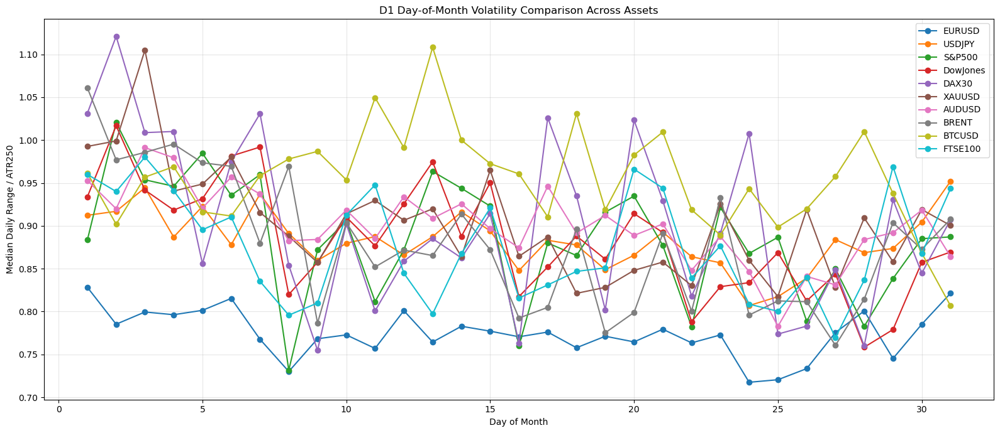

In [ ]:
# %% [markdown]
# ## Compare Day-of-Month Volatility Across Assets

# %%
compare_day_of_month = pd.DataFrame({
    asset: result["day_of_month_stats"][f"median_range_atr{result['structural_atr']}"]
    for asset, result in day_of_month_results.items()
})

display(compare_day_of_month)

plt.figure(figsize=(16, 7))

for asset in compare_day_of_month.columns:
    plt.plot(
        compare_day_of_month.index,
        compare_day_of_month[asset],
        marker="o",
        label=asset
    )

plt.title("D1 Day-of-Month Volatility Comparison Across Assets")
plt.xlabel("Day of Month")
plt.ylabel("Median Daily Range / ATR250")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()